1.Installer les bibliothèques

In [ ]:
%pip install transformers datasets evaluate scikit-learn gensim pyarabic emoji arabert

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 8.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 16.2 MB/s eta 0:00:00
  Created wheel for emoji: filename=emoji-1.4.2-py3-none-any.whl size=186540 sha256=587f84cb7fe921c96d8b77a17e119c5cbad735e3af570479bbda2459fca67f98
  Stored in directory: /root/.cache/pip/wheels/e1/79/2a/9864bac03173079abcc089d3eb3ec87456ac09c381b801f1a3
Successfully built emoji


2. Vérifier Python, PyTorch et le GPU

In [ ]:
import sys
import torch

print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Python : 3.13.15
PyTorch : 2.11.0+cu130
GPU disponible : True
GPU : Tesla T4


3. Fixer les graines et créer les dossiers

In [ ]:
import random
import numpy as np
from pathlib import Path
from transformers import set_seed

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

set_seed(SEED)

for dossier in ["src", "notebooks", "tests", "results", "predictions"]:
    Path(dossier).mkdir(exist_ok=True)

print("Graines fixées et dossiers créés.")

Graines fixées et dossiers créés.


4. Enregistrer les versions installées

In [ ]:
%pip freeze > requirements.txt

In [ ]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

5.charger les données et créer train/validation

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"

full = pd.read_csv(BASE + "training_data.csv")
test = pd.read_csv(BASE + "testing_data.csv")

full["id"] = range(len(full))
test["id"] = range(len(test))

train, val = train_test_split(
    full,
    test_size=0.10,
    random_state=42,
    stratify=full["sarcasm"]
)

print("Train :", len(train))
print("Validation :", len(val))
print("Test :", len(test))

print("\nColonnes :", full.columns.tolist())
display(train.head())

Train : 11293
Validation : 1255
Test : 3000

Colonnes : ['tweet', 'sarcasm', 'sentiment', 'dialect', 'id']


,tweet,sarcasm,sentiment,dialect,id
2474,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن ال...",False,NEU,msa,2474
12107,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يري...",False,NEU,msa,12107
2135,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين ع...,False,NEU,msa,2135
640,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الد...",True,NEG,msa,640
6766,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/x...",False,NEU,msa,6766


#Prétraitement

afficher 30 tweets bruts de train et 30 de test

In [ ]:
def afficher_tweets_bruts(df, nom, n=30):
    exemples = df.sample(n=n, random_state=42)

    print(f"\n===== {nom} : {n} tweets bruts =====")

    for _, ligne in exemples.iterrows():
        print(f"\nID : {ligne['id']}")
        print(
            f"Sarcasme : {ligne['sarcasm']} | "
            f"Sentiment : {ligne['sentiment']} | "
            f"Dialecte : {ligne['dialect']}"
        )

        print("Texte :", ligne["tweet"])
        print("Représentation :", repr(ligne["tweet"]))


afficher_tweets_bruts(train, "TRAIN")
afficher_tweets_bruts(test, "TEST")


===== TRAIN : 30 tweets bruts =====

ID : 7896
Sarcasme : False | Sentiment : POS | Dialecte : msa
Texte : #قطر يفوز
Représentation : '#قطر يفوز'

ID : 7650
Sarcasme : False | Sentiment : NEG | Dialecte : msa
Texte : "@RTarabic روسيا استخدمت جميع الاسلحه المحرمه 🖕🏻🖕🏻🖕🏻"
Représentation : '"@RTarabic روسيا استخدمت جميع الاسلحه المحرمه 🖕🏻🖕🏻🖕🏻"'

ID : 8599
Sarcasme : False | Sentiment : NEU | Dialecte : msa
Texte : "عمليات #الجيش_السوري مستمرة والمسلحون يشكلون "#جيش_حلب"https://t.co/TDbJso9cBd https://t.co/fZX1ftzcLb"
Représentation : '"عمليات #الجيش_السوري مستمرة والمسلحون يشكلون "#جيش_حلب"https://t.co/TDbJso9cBd https://t.co/fZX1ftzcLb"'

ID : 4564
Sarcasme : False | Sentiment : POS | Dialecte : msa
Texte : "@NawalElZoghbi #نوال_الزغبيﻫﻲّ ﺗﻌﻨﻲ ﻟﻲ ﺁﻟﺴﻌﺂﺩة ﻭ اﻟﻨﻘﺂﺀ ﻭ ﺁﻟﻔﺮﺡ ﻭ أﺷﻴﺂﺀ ﻵ ﺁﺳﺘﻄﻴﻊ ﺁﻟﺘﻌﺒﻴﺮ عنها 😍🙈ﻫﻲّ ﺷﻲﺀ ﺁﺗﻤﻨﻰ ﺁﻥ… https://t.co/JA26Bz05l6"
Représentation : '"@NawalElZoghbi #نوال_الزغبيﻫﻲّ ﺗﻌﻨﻲ ﻟﻲ ﺁﻟﺴﻌﺂﺩة ﻭ اﻟﻨﻘﺂﺀ ﻭ ﺁﻟﻔﺮﺡ ﻭ أﺷﻴﺂﺀ ﻵ ﺁﺳﺘﻄﻴﻊ ﺁﻟﺘﻌﺒﻴﺮ عنها 😍🙈ﻫﻲّ ﺷﻲﺀ ﺁﺗﻤﻨﻰ ﺁﻥ… https://t.c

1. Conserver les données avant nettoyage

In [ ]:
import re
import unicodedata
import emoji
from pathlib import Path

# Les copies sont créées une seule fois pour éviter
# de les remplacer si tu réexécutes la cellule.
if "train_brut" not in globals():
    train_brut = train.copy(deep=True)

if "test_brut" not in globals():
    test_brut = test.copy(deep=True)

Path("results").mkdir(exist_ok=True)

# Convertir les labels en 0/1 pour les statistiques
def labels_binaires(df):
    labels = (
        df["sarcasm"].astype(str).str.strip().str.lower()
        .map({"true": 1, "false": 0, "1": 1, "0": 0})
    )

    if labels.isna().any():
        raise ValueError("Valeur inattendue dans la colonne sarcasm.")

    return labels.astype(int)

assert train_brut["tweet"].notna().all()
assert test_brut["tweet"].notna().all()

print("Copies du texte brut conservées.")

Copies du texte brut conservées.


2. Examiner l’artefact et mesurer son lien avec le sarcasme

In [ ]:
def guillemets_externes(texte):
    texte = str(texte).strip()
    return (
        len(texte) >= 2
        and texte.startswith('"')
        and texte.endswith('"')
    )

bilans_artefact = []

for nom, df in [("train", train_brut), ("test", test_brut)]:
    present = df["tweet"].apply(guillemets_externes)
    y = labels_binaires(df)

    print(f"\n===== ARTEFACT : {nom.upper()} =====")
    print("Tweets concernés :", int(present.sum()))
    print("Fréquence :", round(100 * present.mean(), 2), "%")

    tableau = pd.DataFrame({
        "artefact_present": present,
        "sarcasm": y
    }).groupby("artefact_present")["sarcasm"].agg(
        effectif="size",
        nombre_sarcastiques="sum",
        taux_sarcasme="mean"
    )

    tableau["taux_sarcasme"] *= 100
    display(tableau.round(2))

    # Corrélation entre deux variables binaires
    correlation = (
        present.astype(int).corr(y)
        if present.nunique() > 1 and y.nunique() > 1
        else float("nan")
    )
    print("Corrélation avec sarcasm :", correlation)

    print("Exemples avec guillemets externes :")
    for texte in df.loc[present, "tweet"].head(5):
        print(repr(texte))

    bilans_artefact.append({
        "ensemble": nom,
        "nombre": int(present.sum()),
        "frequence_pct": 100 * present.mean(),
        "correlation": correlation
    })

pd.DataFrame(bilans_artefact).to_csv(
    "results/audit_artefact.csv", index=False
)


===== ARTEFACT : TRAIN =====
Tweets concernés : 6837
Fréquence : 60.54 %


,effectif,nombre_sarcastiques,taux_sarcasme
artefact_present,,,
False,4456,1110,24.91
True,6837,841,12.30


Corrélation avec sarcasm : -0.1630253931373359
Exemples avec guillemets externes :
'"#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"'
'"RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"'
'"RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔😔😔😔"'
'"أوباما يلاحق محمد بن سلمان !!: https://t.co/xDtS3uKFal via @YouTube"'
'"تبرعات الهلال الاحمر الكويتي لن تسلم للهلال الأحمر السوري وإنما لبعض المنظمات الدولية الداعمة للمسلحين وللهلال الأحمر القطري أي(جبهة النصرة)"'

===== ARTEFACT : TEST =====
Tweets concernés : 6
Fréquence : 0.2 %


,effectif,nombre_sarcastiques,taux_sarcasme
artefact_present,,,
False,2994,820,27.39
True,6,1,16.67


Corrélation avec sarcasm : -0.010743717144468376
Exemples avec guillemets externes :
'"إن التدين المغشوش قد يكون أنكى بالأمم من الإلحاد الصارخ"'
'"الشوقُ أَسالَ أدمعي..يا ليتَ مُعذّبي معي"'
'"مصير الدنيا تدور وتعيشك نفس الشعور"'
'"سَيمُر كُل مُرّ ، سيتمهد الطريق وينطوي تعب الأيام ، سينتهي كل ما حدث معك وكأنه لم يكن يوماً، سترحل الأوجاع من الدُنيا.. مثلما جاءت يوماً بلا استئذان، سيطرق الفرح باب قلبك بدون حساب ، سَتعود كما كُنت ذلك الشَخص القوي ، ستُقابل أشخاصاً أفضَل ، ثق بالله وَاطمئِن."'
'"ورميتُ سهم الحبِّ أقصدُ قلبها فأصاب سهمي عينها فاعورَّتِ"'


Les guillemets externes sont très fréquents dans train (60,54 %), mais presque absents dans test (0,20 %). Cela suggère une différence de formatage entre les deux ensembles.
Dans train :
- Avec guillemets : 12,30 % des tweets sont sarcastiques.
- Sans guillemets : 24,91 % sont sarcastiques.
- La corrélation −0,163 indique une association négative faible : la présence de guillemets est associée à moins de sarcasme.
Le risque : le modèle pourrait utiliser les guillemets comme raccourci pour prédire « non sarcastique ». Ce raccourci serait peu utile sur test, où ils sont presque absents. Les 6 tweets concernés dans test sont trop peu nombreux pour tirer une conclusion fiable sur leur taux de sarcasme. Certains guillemets peuvent aussi correspondre à de véritables citations.

3. Compter les marqueurs demandés

In [ ]:
motifs = {
    "URL": r"https?://\S+|www\.\S+",
    "Mentions": r"@\w+",
    "Hashtags": r"#\w+",
    "Rires": r"ه{3,}",
    "Ponctuation répétée": r"([!?؟.,،؛:…])\1+",
    "Diacritiques": r"[\u064B-\u065F\u0670]",
    "Tatweel": r"\u0640",
    "Lettres répétées": (
        r"([A-Za-z\u0621-\u063A\u0641-\u064A])\1{2,}"
    ),
    "Caractères latins": r"[A-Za-z]",
    "Chiffres indiens": r"[\u0660-\u0669]"
}

bilans_marqueurs = []

for nom, df in [("train", train_brut), ("test", test_brut)]:
    textes = df["tweet"].astype(str)

    for marqueur, motif in motifs.items():
        nombres = textes.apply(
            lambda texte: len(re.findall(motif, texte))
        )

        bilans_marqueurs.append({
            "ensemble": nom,
            "marqueur": marqueur,
            "occurrences": int(nombres.sum()),
            "tweets_concernes": int((nombres > 0).sum()),
            "frequence_pct": 100 * (nombres > 0).mean()
        })

    motif_emojis = emoji.get_emoji_regexp()

    nombres_emojis = textes.apply(
    lambda texte: len(motif_emojis.findall(texte))
    )

    bilans_marqueurs.append({
        "ensemble": nom,
        "marqueur": "Emojis",
        "occurrences": int(nombres_emojis.sum()),
        "tweets_concernes": int((nombres_emojis > 0).sum()),
        "frequence_pct": 100 * (nombres_emojis > 0).mean()
    })

tableau_marqueurs = pd.DataFrame(bilans_marqueurs)
display(tableau_marqueurs.round(2))

tableau_marqueurs.to_csv(
    "results/audit_marqueurs.csv", index=False
)

,ensemble,marqueur,occurrences,tweets_concernes,frequence_pct
0,train,URL,5199,4302,38.09
1,train,Mentions,3329,2638,23.36
2,train,Hashtags,11948,5333,47.22
3,train,Rires,141,132,1.17
4,train,Ponctuation répétée,2646,1990,17.62
5,train,Diacritiques,3788,1343,11.89
6,train,Tatweel,2335,514,4.55
7,train,Lettres répétées,702,520,4.60
8,train,Caractères latins,128117,6253,55.37
9,train,Chiffres indiens,813,276,2.44


4. Chercher les doublons exacts et après normalisation

In [ ]:
def normaliser_comparaison(texte):
    texte = unicodedata.normalize("NFC", str(texte)).strip()

    # Retirer une paire de guillemets externes
    if guillemets_externes(texte):
        texte = texte[1:-1]

    texte = re.sub(r"[\u064B-\u065F\u0670]", "", texte)
    texte = texte.replace("\u0640", "")
    texte = re.sub(r"[أإآٱ]", "ا", texte)
    texte = re.sub(r"\s+", " ", texte).strip()

    return texte

audit_train = train_brut.copy()
audit_test = test_brut.copy()

audit_train["texte_normalise"] = (
    audit_train["tweet"].apply(normaliser_comparaison)
)
audit_test["texte_normalise"] = (
    audit_test["tweet"].apply(normaliser_comparaison)
)

bilans_doublons = []

for type_doublon, colonne in [
    ("Exact", "tweet"),
    ("Après normalisation", "texte_normalise")
]:
    # Exclure les clés vides de la comparaison
    cles_test = set(
        audit_test.loc[
            audit_test[colonne].str.strip().ne(""),
            colonne
        ]
    )

    chevauchement = (
        audit_train[colonne].isin(cles_test)
        & audit_train[colonne].str.strip().ne("")
    )

    bilans_doublons.append({
        "type": type_doublon,
        "doublons_train_en_exces": int(
            audit_train.duplicated(colonne).sum()
        ),
        "tweets_train_presents_dans_test": int(
            chevauchement.sum()
        )
    })

tableau_doublons = pd.DataFrame(bilans_doublons)
display(tableau_doublons)

tableau_doublons.to_csv(
    "results/audit_doublons.csv", index=False
)

,type,doublons_train_en_exces,tweets_train_presents_dans_test
0,Exact,54,2
1,Après normalisation,331,2


6. Nettoyer train selon une politique explicite

In [ ]:
train_nettoye = audit_train.copy()
train_nettoye["label_binaire"] = labels_binaires(train_nettoye)

effectif_initial = len(train_nettoye)

# A. Retirer les chevauchements train/test
cles_test = set(
    audit_test.loc[
        audit_test["texte_normalise"].ne(""),
        "texte_normalise"
    ]
)

masque_test = (
    train_nettoye["tweet"].isin(set(audit_test["tweet"]))
    | (
        train_nettoye["texte_normalise"].ne("")
        & train_nettoye["texte_normalise"].isin(cles_test)
    )
)

n_chevauchements = int(masque_test.sum())
train_nettoye = train_nettoye.loc[~masque_test].copy()

# B. Retirer les groupes contradictoires de train
diversite = (
    train_nettoye.groupby("texte_normalise")["label_binaire"]
    .nunique()
)

cles_conflits = diversite[
    (diversite > 1) & (diversite.index != "")
].index

masque_conflits = train_nettoye["texte_normalise"].isin(
    cles_conflits
)

n_conflits = int(masque_conflits.sum())
train_nettoye = train_nettoye.loc[~masque_conflits].copy()

# C. Dédupliquer les textes non vides restants
masque_repetitions = (
    train_nettoye["texte_normalise"].ne("")
    & train_nettoye.duplicated("texte_normalise", keep="first")
)

n_repetitions = int(masque_repetitions.sum())
train_nettoye = train_nettoye.loc[~masque_repetitions].copy()

# Garder les colonnes originales et le texte brut
train = train_nettoye[train_brut.columns].copy()

# Vérifier le bilan des suppressions
assert effectif_initial == (
    len(train) + n_chevauchements + n_conflits + n_repetitions
)

bilan_nettoyage = pd.DataFrame([{
    "train_initial": effectif_initial,
    "retires_chevauchement_test": n_chevauchements,
    "retires_contradictions_train": n_conflits,
    "retires_repetitions_train": n_repetitions,
    "train_final": len(train)
}])

display(bilan_nettoyage)

Path("results").mkdir(exist_ok=True)

bilan_nettoyage.to_csv(
    "results/bilan_nettoyage.csv",
    index=False
)

print("Validation inchangée :", len(val))
print("Test inchangé :", len(test))

,train_initial,retires_chevauchement_test,retires_contradictions_train,retires_repetitions_train,train_final
0,11293,2,96,282,10913


Validation inchangée : 1255
Test inchangé : 3000


#Déroulé

#Partie A — Exploration, raccourcis & baseline

1. Calculer les taux de sarcasme

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

Path("results").mkdir(exist_ok=True)

statistiques = []

for nom, df in [("train", train), ("val", val), ("test", test)]:
    donnees = df.copy()
    donnees["y"] = labels_binaires(donnees)

    statistiques.append({
        "ensemble": nom,
        "regroupement": "global",
        "groupe": "tous",
        "effectif": len(donnees),
        "sarcastiques": int(donnees["y"].sum()),
        "taux_sarcasme_pct": 100 * donnees["y"].mean()
    })

    for colonne in ["dialect", "sentiment"]:
        for groupe, sous_ensemble in donnees.groupby(colonne):
            statistiques.append({
                "ensemble": nom,
                "regroupement": colonne,
                "groupe": groupe,
                "effectif": len(sous_ensemble),
                "sarcastiques": int(sous_ensemble["y"].sum()),
                "taux_sarcasme_pct": 100 * sous_ensemble["y"].mean()
            })

tableau_taux = pd.DataFrame(statistiques)

for regroupement in ["global", "dialect", "sentiment"]:
    print(f"\n===== {regroupement.upper()} =====")
    display(
        tableau_taux[
            tableau_taux["regroupement"] == regroupement
        ].round(2)
    )

tableau_taux.to_csv("results/taux_sarcasme.csv", index=False)


===== GLOBAL =====


,ensemble,regroupement,groupe,effectif,sarcastiques,taux_sarcasme_pct
0,train,global,tous,10913,1875,17.18
9,val,global,tous,1255,217,17.29
18,test,global,tous,3000,821,27.37



===== DIALECT =====


,ensemble,regroupement,groupe,effectif,sarcastiques,taux_sarcasme_pct
1,train,dialect,egypt,2330,817,35.06
2,train,dialect,gulf,521,120,23.03
3,train,dialect,levant,554,119,21.48
4,train,dialect,magreb,35,13,37.14
5,train,dialect,msa,7473,806,10.79
10,val,dialect,egypt,260,94,36.15
11,val,dialect,gulf,68,14,20.59
12,val,dialect,levant,55,16,29.09
13,val,dialect,magreb,5,0,0.00
14,val,dialect,msa,867,93,10.73



===== SENTIMENT =====


,ensemble,regroupement,groupe,effectif,sarcastiques,taux_sarcasme_pct
6,train,sentiment,NEG,4041,1693,41.90
7,train,sentiment,NEU,4953,136,2.75
8,train,sentiment,POS,1919,46,2.40
15,val,sentiment,NEG,465,195,41.94
16,val,sentiment,NEU,584,17,2.91
17,val,sentiment,POS,206,5,2.43
24,test,sentiment,NEG,1677,709,42.28
25,test,sentiment,NEU,748,106,14.17
26,test,sentiment,POS,575,6,1.04


In [ ]:
noms_dialectes = {
    "egypt": "Égyptien (egypt)",
    "gulf": "Golfe (gulf)",
    "levant": "Levant (levant)",
    "magreb": "Maghreb (magreb)",
    "msa": "Arabe standard (msa)"
}

tableau_dialectes = (
    tableau_taux[
        tableau_taux["regroupement"] == "dialect"
    ]
    .pivot(
        index="groupe",
        columns="ensemble",
        values="taux_sarcasme_pct"
    )
    .reindex(
        index=["egypt", "gulf", "levant", "magreb", "msa"],
        columns=["train", "val", "test"]
    )
    .rename(
        index=noms_dialectes,
        columns={
            "train": "Train",
            "val": "Validation",
            "test": "Test"
        }
    )
)

tableau_dialectes.index.name = "Dialecte"
tableau_dialectes.columns.name = None

# Afficher avec deux décimales, une virgule et le symbole %
display(
    tableau_dialectes.style.format(
        lambda valeur: f"{valeur:.2f} %".replace(".", ","),
        na_rep="—"
    )
)

# Enregistrer les valeurs numériques dans Colab
tableau_dialectes.to_csv(
    "results/taux_sarcasme_dialectes.csv",
    encoding="utf-8-sig"
)

,Train,Validation,Test
Dialecte,,,
Égyptien (egypt),"35,06 %","36,15 %","50,65 %"
Golfe (gulf),"23,03 %","20,59 %","17,70 %"
Levant (levant),"21,48 %","29,09 %","29,79 %"
Maghreb (magreb),"37,14 %","0,00 %","0,00 %"
Arabe standard (msa),"10,79 %","10,73 %","25,61 %"


2. Tester « jamais sarcastique »

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_train = labels_binaires(train).to_numpy()
y_val = labels_binaires(val).to_numpy()

def evaluer_sur_val(
    nom, predictions, preprocessing,
    seuil=None, temps=0.0, parametres=0, extras=None
):
    resultat = {
        "modele": nom,
        "pretraitement": preprocessing,
        "graine": 42,
        "seuil": seuil,
        "val_accuracy": accuracy_score(y_val, predictions),
        "val_precision_sarc": precision_score(
            y_val, predictions, zero_division=0
        ),
        "val_rappel_sarc": recall_score(
            y_val, predictions, zero_division=0
        ),
        "val_f1_sarc": f1_score(
            y_val, predictions, zero_division=0
        ),
        "val_macro_f1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "temps_entrainement_s": temps,
        "parametres_entraines": parametres
    }

    if extras:
        resultat.update(extras)

    fichier = Path("results/results.csv")
    nouvelle_ligne = pd.DataFrame([resultat])

    if fichier.exists():
        historique = pd.read_csv(fichier)
        nouvelle_ligne = pd.concat(
            [historique, nouvelle_ligne], ignore_index=True
        )

    nouvelle_ligne.to_csv(fichier, index=False)
    return resultat

predictions_triviales = np.zeros(len(y_val), dtype=int)

resultat_trivial = evaluer_sur_val(
    "Jamais sarcastique",
    predictions_triviales,
    preprocessing="aucun"
)

display(pd.DataFrame([resultat_trivial]))

,modele,pretraitement,graine,seuil,val_accuracy,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,temps_entrainement_s,parametres_entraines
0,Jamais sarcastique,aucun,42,None,0.827092,0.0,0.0,0.0,0.452682,0.0,0


3. Construire TF-IDF + régression logistique

In [ ]:
import time
import re

from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, auc

def nettoyer_baseline(texte):
    texte = str(texte).strip()

    if guillemets_externes(texte):
        texte = texte[1:-1]

    return re.sub(r"\s+", " ", texte).strip()

textes_train = train["tweet"].apply(nettoyer_baseline)
textes_val = val["tweet"].apply(nettoyer_baseline)

tfidf = FeatureUnion([
    ("mots", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        lowercase=False
    )),
    ("caracteres", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        lowercase=False
    ))
])

debut = time.perf_counter()

# Apprentissage du vocabulaire et des poids sur TRAIN uniquement
X_train = tfidf.fit_transform(textes_train)

# Application à validation sans nouvel apprentissage
X_val = tfidf.transform(textes_val)

lr = LogisticRegression(
    class_weight="balanced",
    solver="liblinear",
    max_iter=2000,
    random_state=42
)

lr.fit(X_train, y_train)

temps_entrainement = time.perf_counter() - debut

# Probabilité de la classe sarcastique
indice_sarc = list(lr.classes_).index(1)
probabilites_val = lr.predict_proba(X_val)[:, indice_sarc]

# Chercher le seuil maximisant le F1 sur validation
precision, rappel, seuils = precision_recall_curve(
    y_val, probabilites_val
)

f1_par_seuil = (
    2 * precision[:-1] * rappel[:-1]
    / np.maximum(precision[:-1] + rappel[:-1], 1e-12)
)

meilleur_indice = int(np.argmax(f1_par_seuil))
seuil_retenu = float(seuils[meilleur_indice])

predictions_baseline = (
    probabilites_val >= seuil_retenu
).astype(int)

pr_auc = auc(rappel[::-1], precision[::-1])

resultat_baseline = evaluer_sur_val(
    "TF-IDF mots+caracteres + LR balanced",
    predictions_baseline,
    preprocessing="sans guillemets externes + espaces harmonises",
    seuil=seuil_retenu,
    temps=temps_entrainement,
    parametres=lr.coef_.size + lr.intercept_.size,
    extras={"val_pr_auc": pr_auc}
)

print("Nombre de caractéristiques :", X_train.shape[1])
print("Seuil retenu sur validation :", seuil_retenu)
display(pd.DataFrame([resultat_baseline]))

pd.DataFrame({
    "seuil": seuils,
    "f1_sarcastique": f1_par_seuil
}).to_csv("results/seuils_baseline_val.csv", index=False)

Nombre de caractéristiques : 874342
Seuil retenu sur validation : 0.44982908756027223


,modele,pretraitement,graine,seuil,val_accuracy,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,temps_entrainement_s,parametres_entraines,val_pr_auc
0,TF-IDF mots+caracteres + LR balanced,sans guillemets externes + espaces harmonises,42,0.449829,0.793625,0.435185,0.64977,0.521257,0.694859,19.46181,874343,0.507603


4. Auditer les raccourcis et tester les règles simples

In [ ]:
detecteurs = {
    "URL": lambda texte: bool(
        re.search(r"https?://\S+|www\.\S+", str(texte))
    ),
    "Mention": lambda texte: bool(
        re.search(r"@\w+", str(texte))
    ),
    "Guillemets_externes": guillemets_externes
}

bilans_raccourcis = []
resultats_regles = []

for marqueur, detecteur in detecteurs.items():
    presence_train = train["tweet"].apply(detecteur).to_numpy()
    presence_val = val["tweet"].apply(detecteur).to_numpy()

    # Taux avec/sans marqueur dans chaque ensemble
    for nom, df in [("train", train), ("val", val), ("test", test)]:
        presence = df["tweet"].apply(detecteur).to_numpy()
        y = labels_binaires(df).to_numpy()

        for present in [False, True]:
            masque = presence == present

            bilans_raccourcis.append({
                "ensemble": nom,
                "marqueur": marqueur,
                "present": present,
                "effectif": int(masque.sum()),
                "taux_sarcasme_pct": (
                    100 * y[masque].mean()
                    if masque.any() else np.nan
                )
            })

    # Choisir le sens de la règle sur TRAIN
    if np.unique(presence_train).size < 2:
        print(f"{marqueur} : impossible de comparer les deux groupes.")
        continue

    taux_present = y_train[presence_train].mean()
    taux_absent = y_train[~presence_train].mean()

    if taux_present >= taux_absent:
        predictions = presence_val.astype(int)
        regle = "present => sarcastique ; absent => non sarcastique"
    else:
        predictions = (~presence_val).astype(int)
        regle = "absent => sarcastique ; present => non sarcastique"

    resultat = evaluer_sur_val(
        f"Regle unique : {marqueur}",
        predictions,
        preprocessing="texte brut",
        extras={"regle": regle}
    )

    resultats_regles.append(resultat)

tableau_raccourcis = pd.DataFrame(bilans_raccourcis)

display(tableau_raccourcis.round(2))
display(pd.DataFrame(resultats_regles))

tableau_raccourcis.to_csv(
    "results/audit_raccourcis.csv", index=False
)

/tmp/ipykernel_620/1792814018.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  nouvelle_ligne = pd.concat(
/tmp/ipykernel_620/1792814018.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  nouvelle_ligne = pd.concat(
/tmp/ipykernel_620/1792814018.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclu

,ensemble,marqueur,present,effectif,taux_sarcasme_pct
0,train,URL,False,6749,23.86
1,train,URL,True,4164,6.36
2,val,URL,False,756,23.28
3,val,URL,True,499,8.22
4,test,URL,False,2560,31.45
5,test,URL,True,440,3.64
6,train,Mention,False,8492,17.44
7,train,Mention,True,2421,16.27
8,val,Mention,False,954,16.35
9,val,Mention,True,301,20.27


,modele,pretraitement,graine,seuil,val_accuracy,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,temps_entrainement_s,parametres_entraines,regle
0,Regle unique : URL,texte brut,42,None,0.505179,0.232804,0.811060,0.361768,0.478867,0.0,0,absent => sarcastique ; present => non sarcast...
1,Regle unique : Mention,texte brut,42,None,0.315538,0.163522,0.718894,0.266439,0.312458,0.0,0,absent => sarcastique ; present => non sarcast...
2,Regle unique : Guillemets_externes,texte brut,42,None,0.614343,0.218947,0.479263,0.300578,0.517176,0.0,0,absent => sarcastique ; present => non sarcast...


#Partie B — PLM utilisé directement (aucun entraînement)

1.

In [ ]:
import torch
import numpy as np
import pandas as pd
import time
import gc

from pathlib import Path
from transformers import pipeline
from sklearn.metrics import precision_recall_curve, auc

Path("results").mkdir(exist_ok=True)
Path("predictions").mkdir(exist_ok=True)

textes_val = val["tweet"].apply(nettoyer_baseline).tolist()
y_val = labels_binaires(val).to_numpy()

device = 0 if torch.cuda.is_available() else -1

print("Tweets de validation :", len(textes_val))
print("GPU utilisé :", device == 0)

Tweets de validation : 1255
GPU utilisé : True


2. B1 — Charger le modèle NLI et définir les trois formulations

In [ ]:
zs = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=device
)

formulations = {
    "arabe": {
        "labels": ["ساخرة", "جادة"],
        "template": "هذه التغريدة {}."
    },
    "francais": {
        "labels": ["sarcastique", "sérieux"],
        "template": "Le ton de ce tweet est {}."
    },
    "anglais": {
        "labels": ["sarcastic", "serious"],
        "template": "The tone of this tweet is {}."
    }
}

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

3. B1 — Comparer les formulations et choisir les seuils sur validation
Pour chaque formulation, le code :
    1. récupère le score de la classe sarcastique ;
    2. choisit le seuil maximisant le F1 sur validation ;
    3. sauvegarde les scores et les prédictions.

In [ ]:
resultats_b1 = []

for langue, formulation in formulations.items():
    print(f"\n===== B1 : {langue.upper()} =====")
    debut = time.perf_counter()

    sorties = zs(
        textes_val,
        candidate_labels=formulation["labels"],
        hypothesis_template=formulation["template"],
        multi_label=False,
        batch_size=8
    )

    label_sarcastique = formulation["labels"][0]

    # Les labels de sortie sont triés par score :
    # on recherche donc explicitement le label sarcastique.
    scores = np.array([
        sortie["scores"][
            sortie["labels"].index(label_sarcastique)
        ]
        for sortie in sorties
    ])

    temps_inference = time.perf_counter() - debut

    precision, rappel, seuils = precision_recall_curve(
        y_val, scores
    )

    f1_seuils = (
        2 * precision[:-1] * rappel[:-1]
        / np.maximum(precision[:-1] + rappel[:-1], 1e-12)
    )

    seuil = float(seuils[np.argmax(f1_seuils)])
    predictions = (scores >= seuil).astype(int)

    resultat = evaluer_sur_val(
        nom=f"B1 NLI zero-shot {langue}",
        predictions=predictions,
        preprocessing="sans guillemets externes + espaces harmonises",
        seuil=seuil,
        temps=0.0,
        parametres=0,
        extras={
            "hypothese": formulation["template"],
            "temps_inference_val_s": temps_inference,
            "val_pr_auc": auc(rappel[::-1], precision[::-1])
        }
    )

    resultats_b1.append(resultat)

    pd.DataFrame({
        "id": val["id"].to_numpy(),
        "y_true": y_val,
        "y_pred": predictions,
        "score_sarcastique": scores
    }).to_csv(
        f"predictions/B1_{langue}_val_seed42.csv",
        index=False
    )

    print("Seuil :", seuil)
    print("F1 sarcastique :", resultat["val_f1_sarc"])

tableau_b1 = pd.DataFrame(resultats_b1)
display(tableau_b1)

meilleur_b1 = max(
    resultats_b1,
    key=lambda resultat: resultat["val_f1_sarc"]
)

print("Formulation retenue :", meilleur_b1["modele"])
print("Seuil retenu :", meilleur_b1["seuil"])

# Libérer le GPU avant B2
del zs
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


===== B1 : ARABE =====
Seuil : 0.7428533434867859
F1 sarcastique : 0.40052015604681407

===== B1 : FRANCAIS =====
Seuil : 0.8447295427322388
F1 sarcastique : 0.42758620689655175

===== B1 : ANGLAIS =====
Seuil : 0.7970635890960693
F1 sarcastique : 0.40752351097178685


,modele,pretraitement,graine,seuil,val_accuracy,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,temps_entrainement_s,parametres_entraines,hypothese,temps_inference_val_s,val_pr_auc
0,B1 NLI zero-shot arabe,sans guillemets externes + espaces harmonises,42,0.742853,0.632669,0.278986,0.709677,0.400520,0.567865,0.0,0,هذه التغريدة {}.,21.742019,0.340191
1,B1 NLI zero-shot francais,sans guillemets externes + espaces harmonises,42,0.844730,0.801594,0.426606,0.428571,0.427586,0.653793,0.0,0,Le ton de ce tweet est {}.,18.847777,0.353384
2,B1 NLI zero-shot anglais,sans guillemets externes + espaces harmonises,42,0.797064,0.698805,0.308789,0.599078,0.407524,0.602800,0.0,0,The tone of this tweet is {}.,15.020019,0.348857


Formulation retenue : B1 NLI zero-shot francais
Seuil retenu : 0.8447295427322388


4. B2 — Sentiment négatif ⇒ sarcastique

In [ ]:
sa = pipeline(
    "text-classification",
    model="CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment",
    device=device
)

print("Labels du modèle :", sa.model.config.id2label)

labels_negatifs = {
    str(label)
    for label in sa.model.config.id2label.values()
    if str(label).lower() in {"negative", "neg", "négatif"}
}

if not labels_negatifs:
    raise ValueError(
        "Label négatif non identifié : vérifier id2label."
    )

debut = time.perf_counter()

sorties_sentiment = sa(
    textes_val,
    batch_size=16,
    truncation=True,
    max_length=512
)

temps_inference = time.perf_counter() - debut

# Négatif -> 1 ; positif ou neutre -> 0
predictions_b2 = np.array([
    int(sortie["label"] in labels_negatifs)
    for sortie in sorties_sentiment
])

resultat_b2 = evaluer_sur_val(
    nom="B2 CAMeLBERT negatif => sarcastique",
    predictions=predictions_b2,
    preprocessing="sans guillemets externes + espaces harmonises",
    temps=0.0,
    parametres=0,
    extras={"temps_inference_val_s": temps_inference}
)

display(pd.DataFrame([resultat_b2]))

pd.DataFrame({
    "id": val["id"].to_numpy(),
    "y_true": y_val,
    "y_pred": predictions_b2,
    "sentiment_predit": [
        sortie["label"] for sortie in sorties_sentiment
    ]
}).to_csv(
    "predictions/B2_sentiment_val_seed42.csv",
    index=False
)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Labels du modèle : {0: 'positive', 1: 'negative', 2: 'neutral'}


/tmp/ipykernel_620/1792814018.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  nouvelle_ligne = pd.concat(


,modele,pretraitement,graine,seuil,val_accuracy,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,temps_entrainement_s,parametres_entraines,temps_inference_val_s
0,B2 CAMeLBERT negatif => sarcastique,sans guillemets externes + espaces harmonises,42,None,0.687649,0.332054,0.797235,0.468835,0.623808,0.0,0,5.960444


#Partie C — Embeddings statiques + réseaux profonds (PyTorch)

1. Normaliser et découper les tweets

In [ ]:
import re
import pandas as pd
from collections import Counter
from pathlib import Path

def tokeniser_c(texte):
    texte_normalise = normaliser_comparaison(texte)

    # Mots et nombres ; ponctuations et symboles conservés séparément
    return re.findall(r"\w+|[^\w\s]", texte_normalise)

train_c = train.copy()
val_c = val.copy()
test_c = test.copy()

for df in [train_c, val_c, test_c]:
    df["tokens"] = df["tweet"].apply(tokeniser_c)

# Vérifier quelques exemples de train
for _, ligne in train_c.head(3).iterrows():
    print("\nTweet :", ligne["tweet"])
    print("Tokens :", ligne["tokens"])


Tweet : "#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"
Tokens : ['#', 'لافروف', ':', '#', 'موسكو', 'تامل', 'باجراء', 'حوار', 'بناء', 'بشان', 'الازمة', 'في', '#', 'سورية', 'خلال', 'لقائي', 'مع', 'وزيري', 'خارجية', '#', 'ايران', 'و', '#', 'تركيا', 'غدا', 'https', ':', '/', '/', 't', '.', 'co', '/', 'm2ejSZD6WP']

Tweet : "RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"
Tokens : ['RT', '@', 'jalalyw', ':', '@', 'EHSANFAKEEH', 'تفصيل', 'الخبر', 'لمن', 'يريدالاستزادة', 'والاطلاع', '10دورسينما', 'ف', 'مصرستعرض', 'فيلماعن', 'بطولات', 'قاسم', 'سليماني', 'ف', 'العراق', 'وسوريامن', 'انتا', '…']

Tweet : تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول
Tokens : ['تحدثنا', 'عن', 'هذا', 'الكتاب', 'الجميل', 'عن', 'خروج', 'المصريين', 'على', 'السلاطين', 'في'

2. Construire le vocabulaire sur train uniquement

In [ ]:
frequences = Counter(
    token
    for tokens in train_c["tokens"]
    for token in tokens
)

# Deux identifiants réservés
PAD_ID = 0  # Compléter les séquences courtes
UNK_ID = 1  # Token absent du vocabulaire

vocabulaire = {
    "<PAD>": PAD_ID,
    "<UNK>": UNK_ID
}

for token, frequence in sorted(frequences.items()):
    if frequence >= 2 and token not in vocabulaire:
        vocabulaire[token] = len(vocabulaire)

print("Tokens distincts avant filtrage :", len(frequences))
print("Taille du vocabulaire avec PAD/UNK :", len(vocabulaire))

Tokens distincts avant filtrage : 53041
Taille du vocabulaire avec PAD/UNK : 15543


3. Transformer les tokens en identifiants

In [ ]:
def tokens_vers_ids(tokens):
    return [
        vocabulaire.get(token, UNK_ID)
        for token in tokens
    ]

for df in [train_c, val_c, test_c]:
    df["input_ids"] = df["tokens"].apply(tokens_vers_ids)

exemple = train_c.iloc[0]

print("Tokens :", exemple["tokens"])
print("Identifiants :", exemple["input_ids"])

Tokens : ['#', 'لافروف', ':', '#', 'موسكو', 'تامل', 'باجراء', 'حوار', 'بناء', 'بشان', 'الازمة', 'في', '#', 'سورية', 'خلال', 'لقائي', 'مع', 'وزيري', 'خارجية', '#', 'ايران', 'و', '#', 'تركيا', 'غدا', 'https', ':', '/', '/', 't', '.', 'co', '/', 'm2ejSZD6WP']
Identifiants : [4, 10934, 146, 4, 12654, 6312, 5249, 7817, 6077, 5810, 1879, 10305, 4, 8854, 7964, 1, 12282, 1, 7857, 4, 5193, 13247, 4, 6614, 9988, 573, 146, 16, 16, 685, 15, 522, 16, 1]


4. Calculer le taux d’OOV sur validation et test

In [ ]:
bilans_oov = []

for nom, df in [("val", val_c), ("test", test_c)]:
    total_tokens = sum(len(tokens) for tokens in df["tokens"])

    tokens_inconnus = sum(
        token not in vocabulaire
        for tokens in df["tokens"]
        for token in tokens
    )

    bilans_oov.append({
        "ensemble": nom,
        "total_tokens": total_tokens,
        "tokens_OOV": tokens_inconnus,
        "taux_OOV_pct": (
            100 * tokens_inconnus / total_tokens
            if total_tokens else 0.0
        )
    })

tableau_oov = pd.DataFrame(bilans_oov)
display(tableau_oov.round(2))

Path("results").mkdir(exist_ok=True)
tableau_oov.to_csv("results/C_taux_oov.csv", index=False)

,ensemble,total_tokens,tokens_OOV,taux_OOV_pct
0,val,28214,5715,20.26
1,test,63117,17058,27.03


Imports et paramètres communs

In [ ]:
import re
import ast
import gc
import json
import math
import time
import random
import zipfile
import unicodedata

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence,
    pad_packed_sequence
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    auc
)

for dossier in ["results", "predictions", "checkpoints", "resources"]:
    Path(dossier).mkdir(exist_ok=True)

DEVICE_C = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

PAD_ID = 0
UNK_ID = 1

assert vocabulaire["<PAD>"] == PAD_ID
assert vocabulaire["<UNK>"] == UNK_ID

# Longueur déterminée sur TRAIN uniquement.
MAX_LEN = max(
    1,
    min(
        256,
        int(np.ceil(
            np.quantile(train_c["input_ids"].apply(len), 0.95)
        ))
    )
)

CONFIG_C = {
    "seed": 42,
    "batch_size": 32,
    "max_epochs": 8,
    "patience": 2,
    "lr": 0.001,
    "dropout": 0.3,
    "hidden_size": 64,
    "max_len": MAX_LEN,
    "freeze_epochs": 1,
    "arch": "C1",
    "embedding": "random",
    "positions": True,
    "methode": "standard"
}

def fixer_graine_c(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def labels_c(df):
    labels = (
        df["sarcasm"].astype(str).str.strip().str.lower()
        .map({"true": 1, "false": 0, "1": 1, "0": 0})
    )

    if labels.isna().any():
        raise ValueError("Label de sarcasme inconnu.")

    return labels.astype(int).to_numpy()

print("Appareil :", DEVICE_C)
print("Longueur maximale :", MAX_LEN)

for nom, df in [("train", train_c), ("val", val_c)]:
    taux = 100 * df["input_ids"].apply(len).gt(MAX_LEN).mean()
    print(f"{nom} : {taux:.2f} % de tweets seront tronqués.")

Appareil : cuda
Longueur maximale : 35
train : 4.88 % de tweets seront tronqués.
val : 5.82 % de tweets seront tronqués.


Préparer les batchs et le padding

In [ ]:
class TweetsDatasetC(Dataset):
    def __init__(self, df, max_len):
        self.sequences = [
            list(ids[:max_len]) or [UNK_ID]
            for ids in df["input_ids"]
        ]
        self.labels = labels_c(df)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return (
            torch.tensor(
                self.sequences[index],
                dtype=torch.long
            ),
            int(self.labels[index])
        )


def preparer_batch_c(batch):
    sequences, labels = zip(*batch)

    longueurs = torch.tensor(
        [len(sequence) for sequence in sequences],
        dtype=torch.long
    )

    sequences_pad = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=PAD_ID
    )

    labels = torch.tensor(labels, dtype=torch.long)

    return sequences_pad, longueurs, labels


def creer_loaders_c(train_df, val_df, config):
    dataset_train = TweetsDatasetC(
        train_df, config["max_len"]
    )
    dataset_val = TweetsDatasetC(
        val_df, config["max_len"]
    )

    effectifs = np.bincount(
        dataset_train.labels,
        minlength=2
    )

    if (effectifs == 0).any():
        raise ValueError("Train doit contenir les deux classes.")

    generateur = torch.Generator().manual_seed(
        config["seed"]
    )

    sampler = None

    if config["methode"] == "oversampling":
        # Les poids viennent uniquement des labels de TRAIN.
        poids_exemples = 1.0 / effectifs[dataset_train.labels]

        sampler = WeightedRandomSampler(
            weights=torch.tensor(
                poids_exemples,
                dtype=torch.double
            ),
            num_samples=len(dataset_train),
            replacement=True,
            generator=generateur
        )

    train_loader = DataLoader(
        dataset_train,
        batch_size=config["batch_size"],
        shuffle=(sampler is None),
        sampler=sampler,
        collate_fn=preparer_batch_c,
        generator=generateur,
        num_workers=0
    )

    val_loader = DataLoader(
        dataset_val,
        batch_size=config["batch_size"],
        shuffle=False,
        collate_fn=preparer_batch_c,
        num_workers=0
    )

    return train_loader, val_loader, effectifs


train_loader, val_loader, effectifs = creer_loaders_c(
    train_c, val_c, CONFIG_C
)

ids, longueurs, labels = next(iter(val_loader))

print("Dimensions du batch :", ids.shape)
print("Longueurs :", longueurs[:5])
print("Labels :", labels[:5])
print("Effectifs non sarcastiques / sarcastiques :", effectifs)

Dimensions du batch : torch.Size([32, 35])
Longueurs : tensor([26, 27, 16, 15, 25])
Labels : tensor([0, 0, 1, 0, 0])
Effectifs non sarcastiques / sarcastiques : [9038 1875]


Définir les architectures C1, C2 et C3

In [ ]:
class PoolingAttentionC(nn.Module):
    def __init__(self, dimension, dimension_attention=64):
        super().__init__()

        self.W = nn.Linear(
            dimension,
            dimension_attention
        )

        self.v = nn.Linear(
            dimension_attention,
            1,
            bias=False
        )

    def forward(self, etats, masque):
        # score_i = v^T tanh(W h_i)
        scores = self.v(
            torch.tanh(self.W(etats))
        ).squeeze(-1)

        # Le padding ne doit recevoir aucun poids.
        scores = scores.masked_fill(
            ~masque,
            float("-inf")
        )

        alpha = torch.softmax(scores, dim=1)

        # c = somme(alpha_i * h_i)
        contexte = torch.sum(
            etats * alpha.unsqueeze(-1),
            dim=1
        )

        return contexte, alpha


class PositionsSinusoidalesC(nn.Module):
    def __init__(self, dimension, max_len):
        super().__init__()

        positions = torch.arange(
            max_len
        ).float().unsqueeze(1)

        frequences = torch.exp(
            torch.arange(0, dimension, 2).float()
            * (-math.log(10000.0) / dimension)
        )

        encodage = torch.zeros(max_len, dimension)

        encodage[:, 0::2] = torch.sin(
            positions * frequences
        )
        encodage[:, 1::2] = torch.cos(
            positions * frequences
        )

        self.register_buffer(
            "encodage",
            encodage.unsqueeze(0)
        )

    def forward(self, x):
        return x + self.encodage[:, :x.size(1)]


class ModeleC(nn.Module):
    def __init__(self, matrice_embedding, config):
        super().__init__()

        self.config = dict(config)

        poids = torch.as_tensor(
            matrice_embedding,
            dtype=torch.float32
        ).clone()

        poids[PAD_ID].zero_()

        self.embedding = nn.Embedding.from_pretrained(
            poids,
            freeze=False,
            padding_idx=PAD_ID
        )

        dimension_embedding = poids.shape[1]
        self.dropout = nn.Dropout(config["dropout"])

        architecture = config["arch"]

        if architecture in {"C1", "C2"}:
            self.encodeur = nn.LSTM(
                input_size=dimension_embedding,
                hidden_size=config["hidden_size"],
                batch_first=True,
                bidirectional=True
            )

            dimension_sortie = 2 * config["hidden_size"]

            if architecture == "C2":
                self.attention = PoolingAttentionC(
                    dimension_sortie
                )

        elif architecture == "C3":
            dimension_sortie = 128

            self.projection = nn.Linear(
                dimension_embedding,
                dimension_sortie
            )

            self.positions = PositionsSinusoidalesC(
                dimension_sortie,
                config["max_len"]
            )

            couche = nn.TransformerEncoderLayer(
                d_model=128,
                nhead=4,
                dim_feedforward=256,
                dropout=config["dropout"],
                batch_first=True
            )

            self.encodeur = nn.TransformerEncoder(
                couche,
                num_layers=2,
                enable_nested_tensor=False
            )

        elif architecture == "C4":
            self.convolutions = nn.ModuleList([
                nn.Conv1d(
                    dimension_embedding,
                    64,
                    kernel_size=k,
                    padding=k // 2
                )
                for k in [3, 5, 7]
            ])

            dimension_sortie = 64 * 3

        else:
            raise ValueError("Architecture inconnue.")

        self.classifieur = nn.Linear(
            dimension_sortie,
            2
        )

    def forward(
        self,
        ids,
        longueurs,
        retourner_attention=False
    ):
        masque = ids.ne(PAD_ID)
        x = self.dropout(self.embedding(ids))
        alpha = None

        if self.config["arch"] in {"C1", "C2"}:
            sequences = pack_padded_sequence(
                x,
                longueurs.cpu(),
                batch_first=True,
                enforce_sorted=False
            )

            etats_compacts, (h, _) = self.encodeur(
                sequences
            )

            if self.config["arch"] == "C1":
                # Derniers états avant et arrière hors padding.
                contexte = torch.cat(
                    [h[-2], h[-1]],
                    dim=-1
                )

            else:
                etats, _ = pad_packed_sequence(
                    etats_compacts,
                    batch_first=True,
                    total_length=ids.size(1)
                )

                contexte, alpha = self.attention(
                    etats,
                    masque
                )

        elif self.config["arch"] == "C3":
            x = self.projection(x) * math.sqrt(128)

            if self.config["positions"]:
                x = self.positions(x)

            etats = self.encodeur(
                x,
                src_key_padding_mask=~masque
            )

            # Moyenne uniquement sur les tokens réels.
            contexte = (
                etats * masque.unsqueeze(-1)
            ).sum(dim=1) / masque.sum(
                dim=1,
                keepdim=True
            )

        else:
            # C4 : CNN caractères + max-pooling masqué.
            sorties = []

            for convolution in self.convolutions:
                etats = torch.relu(
                    convolution(x.transpose(1, 2))
                )

                etats = etats.masked_fill(
                    ~masque.unsqueeze(1),
                    float("-inf")
                )

                sorties.append(etats.amax(dim=2))

            contexte = torch.cat(sorties, dim=1)

        logits = self.classifieur(
            self.dropout(contexte)
        )

        if retourner_attention:
            return logits, alpha

        return logits

Fonctions d’évaluation et d’entraînement communes

In [ ]:
@torch.no_grad()
def predire_c(modele, loader):
    modele.eval()

    vrais_labels = []
    probabilites = []

    for ids, longueurs, labels in loader:
        logits = modele(
            ids.to(DEVICE_C),
            longueurs
        )

        scores = torch.softmax(
            logits,
            dim=-1
        )[:, 1]

        probabilites.extend(
            scores.cpu().tolist()
        )

        vrais_labels.extend(
            labels.tolist()
        )

    return (
        np.asarray(vrais_labels),
        np.asarray(probabilites)
    )


def mesurer_c(y, scores, seuil):
    predictions = (scores >= seuil).astype(int)

    precision, rappel, _ = precision_recall_curve(
        y, scores
    )

    return {
        "val_accuracy": accuracy_score(y, predictions),
        "val_precision_sarc": precision_score(
            y, predictions, zero_division=0
        ),
        "val_rappel_sarc": recall_score(
            y, predictions, zero_division=0
        ),
        "val_f1_sarc": f1_score(
            y, predictions, zero_division=0
        ),
        "val_macro_f1": f1_score(
            y, predictions,
            average="macro",
            zero_division=0
        ),
        "val_pr_auc": auc(
            rappel[::-1],
            precision[::-1]
        )
    }


def choisir_seuil_c(y, scores):
    precision, rappel, seuils = precision_recall_curve(
        y, scores
    )

    f1 = (
        2 * precision[:-1] * rappel[:-1]
        / np.maximum(
            precision[:-1] + rappel[:-1],
            1e-12
        )
    )

    return float(seuils[np.argmax(f1)])


def regler_embedding_c(modele, config, epoque):
    mode = config["embedding"]

    entrainable = (
        mode == "random"
        or (
            mode == "aravec_thaw"
            and epoque > config["freeze_epochs"]
        )
    )

    modele.embedding.weight.requires_grad_(
        entrainable
    )


def ajouter_resultat_c(resultat, chemin):
    ligne = pd.DataFrame([{
        cle: valeur
        for cle, valeur in resultat.items()
        if cle != "config"
    }])

    chemin = Path(chemin)

    if chemin.exists():
        ligne = pd.concat(
            [pd.read_csv(chemin), ligne],
            ignore_index=True
        )

    ligne.to_csv(chemin, index=False)


def entrainer_c(
    config,
    matrice_embedding,
    train_df=None,
    val_df=None,
    vocab=None
):
    if train_df is None:
        train_df = train_c

    if val_df is None:
        val_df = val_c

    if vocab is None:
        vocab = vocabulaire

    config = dict(config)
    fixer_graine_c(config["seed"])

    train_loader, val_loader, effectifs = creer_loaders_c(
        train_df,
        val_df,
        config
    )

    modele = ModeleC(
        matrice_embedding,
        config
    ).to(DEVICE_C)

    poids_classes = None

    if config["methode"] == "weighted":
        poids_classes = torch.tensor(
            effectifs.sum() / (2 * effectifs),
            dtype=torch.float32,
            device=DEVICE_C
        )

    critere = nn.CrossEntropyLoss(
        weight=poids_classes
    )

    # Tous les paramètres sont inscrits dans l'optimiseur,
    # y compris les embeddings qui pourront être dégelés.
    optimiseur = torch.optim.Adam(
        modele.parameters(),
        lr=config["lr"]
    )

    nom = (
        f"{config['arch']}_{config['embedding']}"
        f"_pos{int(config['positions'])}"
        f"_{config['methode']}_seed{config['seed']}"
    )

    meilleur_f1 = -1.0
    meilleur_etat = None
    meilleure_epoque = 0
    attente = 0
    historique = []
    max_parametres_entraines = 0

    if DEVICE_C.type == "cuda":
        torch.cuda.synchronize()

    debut = time.perf_counter()

    for epoque in range(1, config["max_epochs"] + 1):
        regler_embedding_c(
            modele,
            config,
            epoque
        )

        nombre_parametres = sum(
            p.numel()
            for p in modele.parameters()
            if p.requires_grad
        )

        max_parametres_entraines = max(
            max_parametres_entraines,
            nombre_parametres
        )

        modele.train()
        somme_pertes = 0.0
        nombre_exemples = 0

        for ids, longueurs, labels in train_loader:
            ids = ids.to(DEVICE_C)
            labels = labels.to(DEVICE_C)

            optimiseur.zero_grad(set_to_none=True)

            logits = modele(ids, longueurs)
            perte = critere(logits, labels)

            perte.backward()

            nn.utils.clip_grad_norm_(
                modele.parameters(),
                max_norm=1.0
            )

            optimiseur.step()

            somme_pertes += perte.item() * len(labels)
            nombre_exemples += len(labels)

        y, scores = predire_c(
            modele,
            val_loader
        )

        f1_val = mesurer_c(
            y, scores, seuil=0.5
        )["val_f1_sarc"]

        perte_moyenne = somme_pertes / nombre_exemples

        historique.append({
            "epoque": epoque,
            "perte_train": perte_moyenne,
            "val_f1_seuil_05": f1_val,
            "parametres_entrainables": nombre_parametres
        })

        print(
            f"{nom} | époque {epoque} | "
            f"perte {perte_moyenne:.4f} | "
            f"F1 val {f1_val:.4f}"
        )

        # Pour le mode dégelé, sélectionner parmi les
        # checkpoints obtenus APRÈS le dégel.
        selection_autorisee = (
            config["embedding"] != "aravec_thaw"
            or epoque > config["freeze_epochs"]
        )

        if selection_autorisee:
            if f1_val > meilleur_f1 + 1e-8:
                meilleur_f1 = f1_val
                meilleure_epoque = epoque
                attente = 0

                meilleur_etat = {
                    cle: valeur.detach().cpu().clone()
                    for cle, valeur in modele.state_dict().items()
                }

            else:
                attente += 1

                if attente >= config["patience"]:
                    print("Early stopping.")
                    break

    if meilleur_etat is None:
        raise ValueError(
            "Aucun checkpoint sélectionné : "
            "vérifier max_epochs et freeze_epochs."
        )

    if DEVICE_C.type == "cuda":
        torch.cuda.synchronize()

    temps_entrainement = time.perf_counter() - debut

    modele.load_state_dict(meilleur_etat)

    y, scores = predire_c(
        modele,
        val_loader
    )

    seuil_optimise = choisir_seuil_c(y, scores)

    seuil = (
        seuil_optimise
        if config["methode"] == "threshold"
        else 0.5
    )

    chemin_checkpoint = Path("checkpoints") / f"{nom}.pt"

    torch.save({
        "state_dict": meilleur_etat,
        "config": config,
        "vocabulaire": vocab,
        "embedding_shape": list(matrice_embedding.shape),
        "seuil": seuil,
        "meilleure_epoque": meilleure_epoque
    }, chemin_checkpoint)

    resultat = {
        "modele": nom,
        "arch": config["arch"],
        "embedding": config["embedding"],
        "positions": config["positions"],
        "methode": config["methode"],
        "graine": config["seed"],
        "pretraitement": (
            "normalisation C + caracteres"
            if config["arch"] == "C4"
            else "normalisation C + mots et symboles"
        ),
        "seuil": seuil,
        "seuil_optimal_val": seuil_optimise,
        "temps_entrainement_s": temps_entrainement,
        "parametres_entraines": max_parametres_entraines,
        "meilleure_epoque": meilleure_epoque,
        "epoques_executees": len(historique),
        "taille_checkpoint_Mo": (
            chemin_checkpoint.stat().st_size / 1e6
        ),
        "checkpoint": str(chemin_checkpoint),
        "config": config,
        **mesurer_c(y, scores, seuil)
    }

    pd.DataFrame(historique).to_csv(
        f"results/{nom}_historique.csv",
        index=False
    )

    pd.DataFrame({
        "id": val_df["id"].to_numpy(),
        "y_true": y,
        "y_pred": (scores >= seuil).astype(int),
        "prob_sarcastique": scores
    }).to_csv(
        f"predictions/{nom}_val.csv",
        index=False
    )

    ajouter_resultat_c(
        resultat,
        "results/results.csv"
    )

    ajouter_resultat_c(
        resultat,
        "results/C_results.csv"
    )

    del modele, optimiseur
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return resultat

Entraîner C1, C2 et C3 avec embeddings aléatoires

In [ ]:
DIM_EMBEDDING = 100

generateur_numpy = np.random.default_rng(42)

MATRICE_RANDOM = generateur_numpy.normal(
    loc=0,
    scale=0.05,
    size=(len(vocabulaire), DIM_EMBEDDING)
).astype("float32")

MATRICE_RANDOM[PAD_ID] = 0

MATRICES_C = {
    "random": MATRICE_RANDOM
}

experiences_c = []

for architecture, positions in [
    ("C1", True),
    ("C2", True),
    ("C3", True),
    ("C3", False)
]:
    configuration = {
        **CONFIG_C,
        "arch": architecture,
        "positions": positions,
        "embedding": "random"
    }

    resultat = entrainer_c(
        configuration,
        MATRICE_RANDOM
    )

    experiences_c.append(resultat)

display(pd.DataFrame(experiences_c)[[
    "arch",
    "embedding",
    "positions",
    "val_precision_sarc",
    "val_rappel_sarc",
    "val_f1_sarc",
    "meilleure_epoque"
]].round(4))

C1_random_pos1_standard_seed42 | époque 1 | perte 0.4301 | F1 val 0.1311
C1_random_pos1_standard_seed42 | époque 2 | perte 0.2818 | F1 val 0.4721
C1_random_pos1_standard_seed42 | époque 3 | perte 0.1412 | F1 val 0.4011
C1_random_pos1_standard_seed42 | époque 4 | perte 0.0652 | F1 val 0.3923
Early stopping.
C2_random_pos1_standard_seed42 | époque 1 | perte 0.4265 | F1 val 0.2990
C2_random_pos1_standard_seed42 | époque 2 | perte 0.2846 | F1 val 0.4898
C2_random_pos1_standard_seed42 | époque 3 | perte 0.1637 | F1 val 0.4110
C2_random_pos1_standard_seed42 | époque 4 | perte 0.0857 | F1 val 0.3941
Early stopping.
C3_random_pos1_standard_seed42 | époque 1 | perte 0.4238 | F1 val 0.1362
C3_random_pos1_standard_seed42 | époque 2 | perte 0.2954 | F1 val 0.4266
C3_random_pos1_standard_seed42 | époque 3 | perte 0.1964 | F1 val 0.4381
C3_random_pos1_standard_seed42 | époque 4 | perte 0.1384 | F1 val 0.4483
C3_random_pos1_standard_seed42 | époque 5 | perte 0.1054 | F1 val 0.4252
C3_random_pos1_stan

,arch,embedding,positions,val_precision_sarc,val_rappel_sarc,val_f1_sarc,meilleure_epoque
0,C1,random,True,0.5254,0.4286,0.4721,2
1,C2,random,True,0.5486,0.4424,0.4898,2
2,C3,random,True,0.4815,0.4194,0.4483,4
3,C3,random,False,0.6094,0.3594,0.4522,2


Télécharger AraVec et charger son clean_str officiel

In [ ]:
%pip install gensim requests tqdm

In [ ]:
import requests

from tqdm.auto import tqdm
from gensim.models import Word2Vec

ARAVEC_DIR = Path("resources/aravec")
ARAVEC_DIR.mkdir(parents=True, exist_ok=True)


def telecharger_c(url, destination):
    destination = Path(destination)

    if destination.exists():
        print("Déjà présent :", destination.name)
        return

    temporaire = destination.with_suffix(
        destination.suffix + ".part"
    )

    with requests.get(
        url,
        stream=True,
        timeout=(30, 120)
    ) as reponse:
        reponse.raise_for_status()

        total = int(
            reponse.headers.get("content-length", 0)
        )

        with (
            temporaire.open("wb") as fichier,
            tqdm(
                total=total or None,
                unit="B",
                unit_scale=True
            ) as barre
        ):
            for bloc in reponse.iter_content(1024 * 1024):
                if bloc:
                    fichier.write(bloc)
                    barre.update(len(bloc))

    temporaire.replace(destination)


# Télécharger les utilitaires officiels.
chemin_utilities = ARAVEC_DIR / "utilities.py"

telecharger_c(
    "https://raw.githubusercontent.com/"
    "bakrianoo/aravec/master/utilities.py",
    chemin_utilities
)

# Extraire la fonction clean_str officielle.
source_utilities = chemin_utilities.read_text(
    encoding="utf-8-sig"
)

arbre = ast.parse(source_utilities)

fonction_clean = next(
    element
    for element in arbre.body
    if (
        isinstance(element, ast.FunctionDef)
        and element.name == "clean_str"
    )
)

espace_fonction = {"re": re}

exec(
    compile(
        ast.Module(
            body=[fonction_clean],
            type_ignores=[]
        ),
        str(chemin_utilities),
        "exec"
    ),
    espace_fonction
)

clean_str_aravec = espace_fonction["clean_str"]


# Télécharger le modèle.
nom_modele = "full_uni_cbow_100_twitter.mdl"

modeles_trouves = list(
    ARAVEC_DIR.rglob(nom_modele)
)

if not modeles_trouves:
    archive = ARAVEC_DIR / "full_uni_cbow_100_twitter.zip"

    telecharger_c(
        "https://bakrianoo.ewr1.vultrobjects.com/"
        "aravec/full_uni_cbow_100_twitter.zip",
        archive
    )

    with zipfile.ZipFile(archive) as fichier_zip:
        racine = ARAVEC_DIR.resolve()

        for membre in fichier_zip.infolist():
            destination = (
                racine / membre.filename
            ).resolve()

            if not destination.is_relative_to(racine):
                raise ValueError("Chemin de ZIP inattendu.")

        fichier_zip.extractall(ARAVEC_DIR)

    modeles_trouves = list(
        ARAVEC_DIR.rglob(nom_modele)
    )

if len(modeles_trouves) != 1:
    raise FileNotFoundError(
        "Modèle AraVec Twitter unigrammes 100D non trouvé."
    )

aravec = Word2Vec.load(
    str(modeles_trouves[0])
)

assert aravec.wv.vector_size == DIM_EMBEDDING

print("AraVec chargé.")
print("Dimension :", aravec.wv.vector_size)

  0%|          | 0.00/915 [00:00<?, ?B/s]

  0%|          | 0.00/962M [00:00<?, ?B/s]

AraVec chargé.
Dimension : 100


 Construire la matrice d’embedding AraVec

In [ ]:
MATRICE_ARAVEC = MATRICE_RANDOM.copy()

couverture_aravec = np.zeros(
    len(vocabulaire),
    dtype=bool
)

for token, identifiant in vocabulaire.items():
    if identifiant < 2:
        continue

    cle = clean_str_aravec(token)

    if (
        cle
        and len(cle.split()) == 1
        and cle in aravec.wv
    ):
        MATRICE_ARAVEC[identifiant] = aravec.wv[cle]
        couverture_aravec[identifiant] = True

MATRICE_ARAVEC[PAD_ID] = 0

MATRICES_C["aravec_frozen"] = MATRICE_ARAVEC
MATRICES_C["aravec_thaw"] = MATRICE_ARAVEC

print(
    "Couverture des tokens distincts du vocabulaire :",
    round(100 * couverture_aravec[2:].mean(), 2),
    "%"
)

bilans_couverture = []

for nom, df in [
    ("train", train_c),
    ("val", val_c),
    ("test", test_c)
]:
    identifiants = [
        identifiant
        for sequence in df["input_ids"]
        for identifiant in sequence
    ]

    nombre_couverts = sum(
        bool(couverture_aravec[i])
        for i in identifiants
    )

    bilans_couverture.append({
        "ensemble": nom,
        "total_tokens": len(identifiants),
        "tokens_avec_vecteur_aravec": nombre_couverts,
        "couverture_pct": (
            100 * nombre_couverts / len(identifiants)
            if identifiants else 0
        )
    })

tableau_couverture = pd.DataFrame(
    bilans_couverture
)

display(tableau_couverture.round(2))

tableau_couverture.to_csv(
    "results/C_couverture_aravec.csv",
    index=False
)

np.save(
    "resources/C_matrice_aravec.npy",
    MATRICE_ARAVEC
)

del aravec
gc.collect()

Couverture des tokens distincts du vocabulaire : 91.46 %


,ensemble,total_tokens,tokens_avec_vecteur_aravec,couverture_pct
0,train,242279,150870,62.27
1,val,28214,16099,57.06
2,test,63117,38045,60.28


142

Entraîner avec AraVec figé, puis avec dégel

In [ ]:
for mode_embedding in [
    "aravec_frozen",
    "aravec_thaw"
]:
    for architecture, positions in [
        ("C1", True),
        ("C2", True),
        ("C3", True),
        ("C3", False)
    ]:
        configuration = {
            **CONFIG_C,
            "arch": architecture,
            "positions": positions,
            "embedding": mode_embedding
        }

        resultat = entrainer_c(
            configuration,
            MATRICES_C[mode_embedding]
        )

        experiences_c.append(resultat)


colonnes_comparaison = [
    "arch",
    "embedding",
    "positions",
    "val_precision_sarc",
    "val_rappel_sarc",
    "val_f1_sarc",
    "val_macro_f1",
    "val_pr_auc",
    "temps_entrainement_s",
    "parametres_entraines",
    "meilleure_epoque"
]

tableau_comparaison_c = pd.DataFrame(
    experiences_c
)[colonnes_comparaison]

display(tableau_comparaison_c.round(4))

tableau_comparaison_c.to_csv(
    "results/C_comparaison_architectures.csv",
    index=False
)

# Choisir parmi C1, C2 et C3 avec positions.
# Le Transformer sans positions reste l'ablation.
candidats_c = [
    resultat
    for resultat in experiences_c
    if resultat["positions"]
]

meilleur_c = max(
    candidats_c,
    key=lambda resultat: resultat["val_f1_sarc"]
)

print("Meilleur modèle C :", meilleur_c["modele"])
print("F1 validation :", meilleur_c["val_f1_sarc"])

C1_aravec_frozen_pos1_standard_seed42 | époque 1 | perte 0.4134 | F1 val 0.3681
C1_aravec_frozen_pos1_standard_seed42 | époque 2 | perte 0.3595 | F1 val 0.3312
C1_aravec_frozen_pos1_standard_seed42 | époque 3 | perte 0.3416 | F1 val 0.3587
Early stopping.
C2_aravec_frozen_pos1_standard_seed42 | époque 1 | perte 0.4002 | F1 val 0.4566
C2_aravec_frozen_pos1_standard_seed42 | époque 2 | perte 0.3528 | F1 val 0.4026
C2_aravec_frozen_pos1_standard_seed42 | époque 3 | perte 0.3407 | F1 val 0.3882
Early stopping.
C3_aravec_frozen_pos1_standard_seed42 | époque 1 | perte 0.4082 | F1 val 0.3720
C3_aravec_frozen_pos1_standard_seed42 | époque 2 | perte 0.3969 | F1 val 0.4417
C3_aravec_frozen_pos1_standard_seed42 | époque 3 | perte 0.3964 | F1 val 0.3301
C3_aravec_frozen_pos1_standard_seed42 | époque 4 | perte 0.3922 | F1 val 0.4149
Early stopping.
C3_aravec_frozen_pos0_standard_seed42 | époque 1 | perte 0.4106 | F1 val 0.3186
C3_aravec_frozen_pos0_standard_seed42 | époque 2 | perte 0.3950 | F1 val

,arch,embedding,positions,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,val_pr_auc,temps_entrainement_s,parametres_entraines,meilleure_epoque
0,C1,random,True,0.5254,0.4286,0.4721,0.6869,0.5065,12.1099,1639550,2
1,C2,random,True,0.5486,0.4424,0.4898,0.6977,0.5101,15.1939,1647870,2
2,C3,random,True,0.4815,0.4194,0.4483,0.6709,0.4334,16.7848,1832446,4
3,C3,random,False,0.6094,0.3594,0.4522,0.6824,0.5222,10.9955,1832446,2
4,C1,aravec_frozen,True,0.4558,0.3088,0.3681,0.6305,0.4137,13.2451,85250,1
5,C2,aravec_frozen,True,0.4946,0.4240,0.4566,0.6763,0.4901,19.9428,93570,1
6,C3,aravec_frozen,True,0.4030,0.4885,0.4417,0.6548,0.4524,23.5107,278146,2
7,C3,aravec_frozen,False,0.3770,0.6359,0.4734,0.6570,0.4654,20.9580,278146,2
8,C1,aravec_thaw,True,0.5024,0.4839,0.4930,0.6947,0.5055,42.0702,1639550,7
9,C2,aravec_thaw,True,0.6966,0.2857,0.4052,0.6613,0.5199,19.6323,1647870,2


Meilleur modèle C : C1_aravec_thaw_pos1_standard_seed42
F1 validation : 0.49295774647887325


Visualiser l’attention de C2 sur cinq tweets sarcastiques

In [ ]:
import html

from IPython.display import HTML, display


def charger_modele_c(chemin):
    checkpoint = torch.load(
        chemin,
        map_location="cpu",
        weights_only=False
    )

    matrice_vide = np.zeros(
        checkpoint["embedding_shape"],
        dtype=np.float32
    )

    modele = ModeleC(
        matrice_vide,
        checkpoint["config"]
    )

    modele.load_state_dict(
        checkpoint["state_dict"]
    )

    return modele.eval(), checkpoint


meilleur_c2 = max(
    [
        resultat
        for resultat in experiences_c
        if resultat["arch"] == "C2"
    ],
    key=lambda resultat: resultat["val_f1_sarc"]
)

modele_attention, checkpoint_attention = charger_modele_c(
    meilleur_c2["checkpoint"]
)

exemples = val_c.loc[
    labels_c(val_c) == 1
].head(5)

blocs_html = []

with torch.no_grad():
    for _, ligne in exemples.iterrows():
        ids = (
            list(ligne["input_ids"][:MAX_LEN])
            or [UNK_ID]
        )

        tokens = (
            list(ligne["tokens"][:MAX_LEN])
            or ["<UNK>"]
        )

        logits, alpha = modele_attention(
            torch.tensor([ids], dtype=torch.long),
            torch.tensor([len(ids)]),
            retourner_attention=True
        )

        poids = alpha[0].numpy()
        maximum = max(float(poids.max()), 1e-12)

        morceaux = []

        for token, poids_token in zip(tokens, poids):
            intensite = float(poids_token) / maximum

            morceaux.append(
                f'<span title="poids={poids_token:.5f}" '
                f'style="background:rgba(255,130,0,{intensite:.3f});'
                f'padding:3px">'
                f'{html.escape(token)}</span>'
            )

        blocs_html.append(
            f'<p>ID : {ligne["id"]}</p>'
            '<p dir="auto" style="line-height:2.5">'
            + " ".join(morceaux)
            + "</p>"
        )

page_attention = (
    '<html><meta charset="utf-8"><body>'
    + "".join(blocs_html)
    + "</body></html>"
)

display(HTML(page_attention))

Path("results/C2_attention_5_tweets.html").write_text(
    page_attention,
    encoding="utf-8"
)

del modele_attention
gc.collect()

38

Comparer les trois méthodes contre le déséquilibre

In [ ]:
resultats_q6 = []

for methode in [
    "weighted",
    "oversampling",
    "threshold"
]:
    configuration = {
        **meilleur_c["config"],
        "methode": methode,
        "seed": 42
    }

    resultat = entrainer_c(
        configuration,
        MATRICES_C[configuration["embedding"]]
    )

    resultats_q6.append(resultat)


tableau_q6 = pd.DataFrame(resultats_q6)[[
    "methode",
    "seuil",
    "val_precision_sarc",
    "val_rappel_sarc",
    "val_f1_sarc",
    "val_macro_f1",
    "val_pr_auc",
    "temps_entrainement_s"
]]

display(tableau_q6.round(4))

tableau_q6.to_csv(
    "results/C_Q6_desequilibre.csv",
    index=False
)

meilleur_q6 = max(
    resultats_q6,
    key=lambda resultat: resultat["val_f1_sarc"]
)

print("Méthode retenue :", meilleur_q6["methode"])

C1_aravec_thaw_pos1_weighted_seed42 | époque 1 | perte 0.5827 | F1 val 0.4283
C1_aravec_thaw_pos1_weighted_seed42 | époque 2 | perte 0.5126 | F1 val 0.4874
C1_aravec_thaw_pos1_weighted_seed42 | époque 3 | perte 0.4722 | F1 val 0.4955
C1_aravec_thaw_pos1_weighted_seed42 | époque 4 | perte 0.4304 | F1 val 0.5064
C1_aravec_thaw_pos1_weighted_seed42 | époque 5 | perte 0.3886 | F1 val 0.5038
C1_aravec_thaw_pos1_weighted_seed42 | époque 6 | perte 0.3520 | F1 val 0.5140
C1_aravec_thaw_pos1_weighted_seed42 | époque 7 | perte 0.3115 | F1 val 0.5362
C1_aravec_thaw_pos1_weighted_seed42 | époque 8 | perte 0.2853 | F1 val 0.5213
C1_aravec_thaw_pos1_oversampling_seed42 | époque 1 | perte 0.5488 | F1 val 0.4763
C1_aravec_thaw_pos1_oversampling_seed42 | époque 2 | perte 0.4608 | F1 val 0.5079
C1_aravec_thaw_pos1_oversampling_seed42 | époque 3 | perte 0.4055 | F1 val 0.5076
C1_aravec_thaw_pos1_oversampling_seed42 | époque 4 | perte 0.3554 | F1 val 0.4984
Early stopping.
C1_aravec_thaw_pos1_threshold_se

,methode,seuil,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,val_pr_auc,temps_entrainement_s
0,weighted,0.5000,0.4418,0.6820,0.5362,0.7027,0.5134,21.6300
1,oversampling,0.5000,0.4114,0.6636,0.5079,0.6822,0.5009,10.6766
2,threshold,0.3626,0.4582,0.5806,0.5122,0.6966,0.5055,23.8537


Méthode retenue : weighted


Répéter le modèle final C avec trois graines

In [ ]:
resultats_finaux_c = [meilleur_q6]

for graine in [43, 44]:
    configuration = {
        **meilleur_q6["config"],
        "seed": graine
    }

    resultat = entrainer_c(
        configuration,
        MATRICES_C[configuration["embedding"]]
    )

    resultats_finaux_c.append(resultat)


tableau_finaux_c = pd.DataFrame(
    resultats_finaux_c
)

display(tableau_finaux_c[[
    "graine",
    "seuil",
    "val_f1_sarc",
    "val_macro_f1",
    "val_pr_auc"
]].round(4))

moyenne = tableau_finaux_c["val_f1_sarc"].mean()
ecart_type = tableau_finaux_c["val_f1_sarc"].std(ddof=1)

print(
    f"F1 validation : "
    f"{moyenne:.4f} ± {ecart_type:.4f}"
)

Path("results/C_modeles_finaux.json").write_text(
    json.dumps(
        resultats_finaux_c,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

C1_aravec_thaw_pos1_weighted_seed43 | époque 1 | perte 0.5893 | F1 val 0.4714
C1_aravec_thaw_pos1_weighted_seed43 | époque 2 | perte 0.5113 | F1 val 0.4615
C1_aravec_thaw_pos1_weighted_seed43 | époque 3 | perte 0.4592 | F1 val 0.5240
C1_aravec_thaw_pos1_weighted_seed43 | époque 4 | perte 0.4250 | F1 val 0.5085
C1_aravec_thaw_pos1_weighted_seed43 | époque 5 | perte 0.3869 | F1 val 0.5204
Early stopping.
C1_aravec_thaw_pos1_weighted_seed44 | époque 1 | perte 0.5874 | F1 val 0.4444
C1_aravec_thaw_pos1_weighted_seed44 | époque 2 | perte 0.5079 | F1 val 0.5038
C1_aravec_thaw_pos1_weighted_seed44 | époque 3 | perte 0.4681 | F1 val 0.5222
C1_aravec_thaw_pos1_weighted_seed44 | époque 4 | perte 0.4237 | F1 val 0.5287
C1_aravec_thaw_pos1_weighted_seed44 | époque 5 | perte 0.3903 | F1 val 0.5087
C1_aravec_thaw_pos1_weighted_seed44 | époque 6 | perte 0.3548 | F1 val 0.5558
C1_aravec_thaw_pos1_weighted_seed44 | époque 7 | perte 0.3170 | F1 val 0.5441
C1_aravec_thaw_pos1_weighted_seed44 | époque 8 |

,graine,seuil,val_f1_sarc,val_macro_f1,val_pr_auc
0,42,0.5,0.5362,0.7027,0.5134
1,43,0.5,0.5240,0.6964,0.5033
2,44,0.5,0.5558,0.7134,0.5189


F1 validation : 0.5387 ± 0.0160


3360

C4 — CNN caractères, optionnel

In [ ]:
EXECUTER_C4 = True

if EXECUTER_C4:
    train_char = train_c.copy()
    val_char = val_c.copy()

    frequences_char = Counter(
        caractere
        for texte in train_char["tweet"]
        for caractere in normaliser_comparaison(texte)
    )

    vocab_char = {
        "<PAD>": PAD_ID,
        "<UNK>": UNK_ID
    }

    for caractere, frequence in sorted(
        frequences_char.items()
    ):
        if frequence >= 2:
            vocab_char[caractere] = len(vocab_char)

    for df in [train_char, val_char]:
        df["input_ids"] = df["tweet"].apply(
            lambda texte: [
                vocab_char.get(caractere, UNK_ID)
                for caractere in normaliser_comparaison(texte)
            ]
        )

    max_len_char = max(
        1,
        min(
            512,
            int(np.ceil(
                np.quantile(
                    train_char["input_ids"].apply(len),
                    0.95
                )
            ))
        )
    )

    matrice_char = np.random.default_rng(42).normal(
        0,
        0.05,
        size=(len(vocab_char), 64)
    ).astype("float32")

    matrice_char[PAD_ID] = 0

    configuration_char = {
        **CONFIG_C,
        "arch": "C4",
        "embedding": "random",
        "max_len": max_len_char
    }

    resultat_c4 = entrainer_c(
        configuration_char,
        matrice_char,
        train_df=train_char,
        val_df=val_char,
        vocab=vocab_char
    )

    display(pd.DataFrame([resultat_c4])[[
        "arch",
        "val_precision_sarc",
        "val_rappel_sarc",
        "val_f1_sarc"
    ]])

C4_random_pos1_standard_seed42 | époque 1 | perte 0.4369 | F1 val 0.0840
C4_random_pos1_standard_seed42 | époque 2 | perte 0.4081 | F1 val 0.1393
C4_random_pos1_standard_seed42 | époque 3 | perte 0.3950 | F1 val 0.1411
C4_random_pos1_standard_seed42 | époque 4 | perte 0.3826 | F1 val 0.2039
C4_random_pos1_standard_seed42 | époque 5 | perte 0.3693 | F1 val 0.2348
C4_random_pos1_standard_seed42 | époque 6 | perte 0.3591 | F1 val 0.3154
C4_random_pos1_standard_seed42 | époque 7 | perte 0.3462 | F1 val 0.1912
C4_random_pos1_standard_seed42 | époque 8 | perte 0.3330 | F1 val 0.3427


,arch,val_precision_sarc,val_rappel_sarc,val_f1_sarc
0,C4,0.528846,0.253456,0.342679


Télécharger les résultats

In [ ]:
Path("resources/C_vocabulaire.json").write_text(
    json.dumps(
        vocabulaire,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

with zipfile.ZipFile(
    "Partie_C_resultats.zip",
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for dossier in ["results", "predictions"]:
        for fichier in Path(dossier).rglob("*"):
            if fichier.is_file():
                archive.write(
                    fichier,
                    arcname=str(fichier)
                )

    archive.write(
        "resources/C_vocabulaire.json",
        arcname="resources/C_vocabulaire.json"
    )

from google.colab import files

files.download("Partie_C_resultats.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Partie D — PLM gelé : l'encodeur comme extracteur de représentations

1. Charger AraBERT et son préprocesseur

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import joblib

from pathlib import Path
from tqdm.auto import tqdm

from transformers import AutoTokenizer, AutoModel
from arabert.preprocess import ArabertPreprocessor

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    auc
)

for dossier in ["results", "predictions", "checkpoints"]:
    Path(dossier).mkdir(exist_ok=True)

NOM_ARABERT = "aubmindlab/bert-base-arabertv02-twitter"
MAX_LEN_D = 64
BATCH_D = 32

DEVICE_D = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

preprocesseur_d = ArabertPreprocessor(
    model_name=NOM_ARABERT
)

tokenizer_d = AutoTokenizer.from_pretrained(
    NOM_ARABERT
)

encodeur_d = AutoModel.from_pretrained(
    NOM_ARABERT
).to(DEVICE_D)

# Geler tous les paramètres d'AraBERT.
for parametre in encodeur_d.parameters():
    parametre.requires_grad = False

# Désactiver notamment le dropout pendant l'extraction.
encodeur_d.eval()

print("Appareil :", DEVICE_D)
print(
    "Paramètres entraînables dans AraBERT :",
    sum(
        p.numel()
        for p in encodeur_d.parameters()
        if p.requires_grad
    )
)

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Appareil : cuda
Paramètres entraînables dans AraBERT : 0


2. Appliquer le prétraitement PLM

In [ ]:
def preparer_texte_d(texte):
    texte = str(texte).strip()

    # Même retrait de l'artefact candidat que précédemment.
    if (
        len(texte) >= 2
        and texte.startswith('"')
        and texte.endswith('"')
    ):
        texte = texte[1:-1]

    return preprocesseur_d.preprocess(texte)


textes_train_d = train["tweet"].apply(
    preparer_texte_d
).tolist()

textes_val_d = val["tweet"].apply(
    preparer_texte_d
).tolist()

y_train_d = labels_binaires(train).to_numpy()
y_val_d = labels_binaires(val).to_numpy()

# Examiner les effets du prétraitement pour Q3.
for i in range(3):
    print("\nAVANT :", train.iloc[i]["tweet"])
    print("APRÈS :", textes_train_d[i])


AVANT : "#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"
APRÈS : # لافروف : # موسكو تأمل بإجراء حوار بناء بشأن الأزمة في # سورية خلال لقائي مع وزيري خارجية # إيران و # تركيا غدا [رابط]

AVANT : "RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"
APRÈS : RT [مستخدم] : [مستخدم] تفصيل الخبر لمن يريدالإستزادة والإطلاع 10 دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا …

AVANT : تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول
APRÈS : تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول


3. Extraire [CLS] et la moyenne des tokens

In [ ]:
@torch.no_grad()
def extraire_representations_d(textes):
    vecteurs_cls = []
    vecteurs_moyens = []

    for debut in tqdm(
        range(0, len(textes), BATCH_D),
        desc="Extraction AraBERT"
    ):
        lot = textes[debut:debut + BATCH_D]

        entrees = tokenizer_d(
            lot,
            padding=True,
            truncation=True,
            max_length=MAX_LEN_D,
            return_tensors="pt"
        )

        entrees = {
            cle: valeur.to(DEVICE_D)
            for cle, valeur in entrees.items()
        }

        sorties = encodeur_d(**entrees)

        # Dimensions : batch × tokens × dimension cachée.
        etats = sorties.last_hidden_state

        # Premier token : CLS.
        cls = etats[:, 0, :]

        # Masque : 1 pour token réel, 0 pour padding.
        masque = entrees["attention_mask"].unsqueeze(-1)
        masque = masque.to(etats.dtype)

        moyenne = (
            (etats * masque).sum(dim=1)
            / masque.sum(dim=1).clamp(min=1)
        )

        vecteurs_cls.append(cls.cpu().numpy())
        vecteurs_moyens.append(moyenne.cpu().numpy())

    return (
        np.concatenate(vecteurs_cls),
        np.concatenate(vecteurs_moyens)
    )


debut_extraction = time.perf_counter()

X_train_cls, X_train_moyenne = extraire_representations_d(
    textes_train_d
)

X_val_cls, X_val_moyenne = extraire_representations_d(
    textes_val_d
)

temps_extraction_d1 = time.perf_counter() - debut_extraction

print("Train CLS :", X_train_cls.shape)
print("Train moyenne :", X_train_moyenne.shape)
print("Validation CLS :", X_val_cls.shape)
print("Temps d'extraction :", round(temps_extraction_d1, 2), "s")

Extraction AraBERT:   0%|          | 0/342 [00:00<?, ?it/s]

Extraction AraBERT:   0%|          | 0/40 [00:00<?, ?it/s]

Train CLS : (10913, 768)
Train moyenne : (10913, 768)
Validation CLS : (1255, 768)
Temps d'extraction : 31.93 s


4. Entraîner les deux régressions logistiques et optimiser leurs seuils

In [ ]:
def metriques_d(y, scores, seuil):
    predictions = (scores >= seuil).astype(int)

    precision, rappel, _ = precision_recall_curve(
        y, scores
    )

    return {
        "val_accuracy": accuracy_score(y, predictions),
        "val_precision_sarc": precision_score(
            y, predictions, zero_division=0
        ),
        "val_rappel_sarc": recall_score(
            y, predictions, zero_division=0
        ),
        "val_f1_sarc": f1_score(
            y, predictions, zero_division=0
        ),
        "val_macro_f1": f1_score(
            y, predictions,
            average="macro",
            zero_division=0
        ),
        "val_pr_auc": auc(
            rappel[::-1],
            precision[::-1]
        )
    }


def seuil_optimal_d(y, scores):
    precision, rappel, seuils = precision_recall_curve(
        y, scores
    )

    f1 = (
        2 * precision[:-1] * rappel[:-1]
        / np.maximum(
            precision[:-1] + rappel[:-1],
            1e-12
        )
    )

    return float(seuils[np.argmax(f1)])


resultats_d1 = []
modeles_d1 = {}

for representation, X_train_d, X_val_d in [
    ("CLS", X_train_cls, X_val_cls),
    ("moyenne", X_train_moyenne, X_val_moyenne)
]:
    modele_lr_d = LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=2000,
        random_state=42
    )

    debut = time.perf_counter()
    modele_lr_d.fit(X_train_d, y_train_d)
    temps_lr = time.perf_counter() - debut

    indice_sarc = list(modele_lr_d.classes_).index(1)

    scores = modele_lr_d.predict_proba(
        X_val_d
    )[:, indice_sarc]

    seuil = seuil_optimal_d(y_val_d, scores)

    resultat = {
        "modele": f"D1_AraBERT_gele_{representation}_LR",
        "representation": representation,
        "pretraitement": "guillemets externes retires + ArabertPreprocessor",
        "graine": 42,
        "seuil": seuil,
        "temps_entrainement_s": temps_lr,
        "temps_extraction_commun_s": temps_extraction_d1,
        "parametres_entraines": (
            modele_lr_d.coef_.size
            + modele_lr_d.intercept_.size
        ),
        **metriques_d(y_val_d, scores, seuil)
    }

    resultats_d1.append(resultat)
    modeles_d1[representation] = modele_lr_d

    joblib.dump({
        "classifieur": modele_lr_d,
        "seuil": seuil,
        "representation": representation,
        "encodeur": NOM_ARABERT,
        "revision_encodeur": getattr(
            encodeur_d.config, "_commit_hash", None
        ),
        "max_length": MAX_LEN_D,
        "pretraitement": resultat["pretraitement"]
    }, f"checkpoints/D1_{representation}_seed42.joblib")

    pd.DataFrame({
        "id": val["id"].to_numpy(),
        "y_true": y_val_d,
        "y_pred": (scores >= seuil).astype(int),
        "prob_sarcastique": scores
    }).to_csv(
        f"predictions/D1_{representation}_val_seed42.csv",
        index=False
    )


tableau_d1 = pd.DataFrame(resultats_d1)

display(tableau_d1.round(4))

tableau_d1.to_csv(
    "results/D1_comparaison.csv",
    index=False
)

# Ajouter les expériences au journal commun.
chemin_resultats = Path("results/results.csv")

if chemin_resultats.exists():
    historique = pd.read_csv(chemin_resultats)

    journal = pd.concat(
        [historique, tableau_d1],
        ignore_index=True
    )
else:
    journal = tableau_d1

journal.to_csv(chemin_resultats, index=False)

,modele,representation,pretraitement,graine,seuil,temps_entrainement_s,temps_extraction_commun_s,parametres_entraines,val_accuracy,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,val_pr_auc
0,D1_AraBERT_gele_CLS_LR,CLS,guillemets externes retires + ArabertPreprocessor,42,0.6671,8.9206,31.9338,769,0.8478,0.5485,0.6774,0.6062,0.7559,0.6077
1,D1_AraBERT_gele_moyenne_LR,moyenne,guillemets externes retires + ArabertPreprocessor,42,0.6863,6.4067,31.9338,769,0.8574,0.5731,0.6866,0.6247,0.7683,0.6311


D2-1. Extraire les représentations de tous les tokens

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence,
    pad_packed_sequence
)

@torch.no_grad()
def extraire_tokens_d2(textes):
    encodeur_d.to(DEVICE_D)
    encodeur_d.eval()

    representations = []
    identifiants = []

    for debut in tqdm(
        range(0, len(textes), BATCH_D),
        desc="Extraction des tokens D2"
    ):
        entrees = tokenizer_d(
            textes[debut:debut + BATCH_D],
            padding=True,
            truncation=True,
            max_length=MAX_LEN_D,
            return_tensors="pt"
        )

        longueurs = entrees["attention_mask"].sum(dim=1)
        ids_cpu = entrees["input_ids"]

        entrees_gpu = {
            cle: valeur.to(DEVICE_D)
            for cle, valeur in entrees.items()
        }

        etats = encodeur_d(
            **entrees_gpu
        ).last_hidden_state

        # Stockage CPU en float16 pour réduire la mémoire.
        etats_cpu = etats.to(
            device="cpu",
            dtype=torch.float16
        )

        for i, longueur in enumerate(longueurs.tolist()):
            representations.append(
                etats_cpu[i, :longueur].clone()
            )
            identifiants.append(
                ids_cpu[i, :longueur].clone()
            )

    return representations, identifiants


debut = time.perf_counter()

etats_train_d2, ids_train_d2 = extraire_tokens_d2(
    textes_train_d
)

etats_val_d2, ids_val_d2 = extraire_tokens_d2(
    textes_val_d
)

temps_extraction_d2 = time.perf_counter() - debut

# AraBERT n'est plus nécessaire sur GPU pour entraîner la tête.
encodeur_d.to("cpu")

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Tweets train :", len(etats_train_d2))
print("Dimensions du premier tweet :", etats_train_d2[0].shape)
print("Temps d'extraction :", round(temps_extraction_d2, 2), "s")

Extraction des tokens D2:   0%|          | 0/342 [00:00<?, ?it/s]

Extraction des tokens D2:   0%|          | 0/40 [00:00<?, ?it/s]

Tweets train : 10913
Dimensions du premier tweet : torch.Size([31, 768])
Temps d'extraction : 33.35 s


2. Préparer les batchs de représentations

In [ ]:
class DatasetD2(Dataset):
    def __init__(self, representations, labels):
        self.representations = representations
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return (
            self.representations[index],
            int(self.labels[index])
        )


def preparer_batch_d2(batch):
    representations, labels = zip(*batch)

    longueurs = torch.tensor(
        [len(x) for x in representations],
        dtype=torch.long
    )

    representations_pad = pad_sequence(
        representations,
        batch_first=True,
        padding_value=0
    ).float()

    return (
        representations_pad,
        longueurs,
        torch.tensor(labels, dtype=torch.long)
    )


train_loader_d2 = DataLoader(
    DatasetD2(etats_train_d2, y_train_d),
    batch_size=32,
    shuffle=True,
    collate_fn=preparer_batch_d2,
    generator=torch.Generator().manual_seed(42)
)

val_loader_d2 = DataLoader(
    DatasetD2(etats_val_d2, y_val_d),
    batch_size=32,
    shuffle=False,
    collate_fn=preparer_batch_d2
)

3. Définir la tête BiLSTM + attention

In [ ]:
class TeteD2(nn.Module):
    def __init__(
        self,
        dimension_entree,
        hidden_size=64,
        dropout=0.3
    ):
        super().__init__()

        self.bilstm = nn.LSTM(
            input_size=dimension_entree,
            hidden_size=hidden_size,
            batch_first=True,
            bidirectional=True
        )

        self.attention = PoolingAttentionC(
            dimension=2 * hidden_size
        )

        self.dropout = nn.Dropout(dropout)
        self.classifieur = nn.Linear(2 * hidden_size, 2)

    def forward(
        self,
        representations,
        longueurs,
        retourner_attention=False
    ):
        sequences = pack_padded_sequence(
            representations,
            longueurs.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        etats_compacts, _ = self.bilstm(sequences)

        etats, _ = pad_packed_sequence(
            etats_compacts,
            batch_first=True,
            total_length=representations.size(1)
        )

        positions = torch.arange(
            representations.size(1),
            device=representations.device
        ).unsqueeze(0)

        masque = positions < longueurs.to(
            representations.device
        ).unsqueeze(1)

        contexte, alpha = self.attention(
            etats,
            masque
        )

        logits = self.classifieur(
            self.dropout(contexte)
        )

        if retourner_attention:
            return logits, alpha

        return logits

4. Entraîner uniquement cette tête

In [ ]:
@torch.no_grad()
def predire_d2(modele, loader):
    modele.eval()

    probabilites = []
    vrais_labels = []

    for representations, longueurs, labels in loader:
        logits = modele(
            representations.to(DEVICE_D),
            longueurs
        )

        scores = torch.softmax(logits, dim=-1)[:, 1]

        probabilites.extend(scores.cpu().tolist())
        vrais_labels.extend(labels.tolist())

    return np.array(vrais_labels), np.array(probabilites)


fixer_graine_c(42)

dimension_d2 = encodeur_d.config.hidden_size

tete_d2 = TeteD2(
    dimension_entree=dimension_d2
).to(DEVICE_D)

effectifs = np.bincount(y_train_d, minlength=2)

poids_classes = torch.tensor(
    effectifs.sum() / (2 * effectifs),
    dtype=torch.float32,
    device=DEVICE_D
)

critere_d2 = nn.CrossEntropyLoss(
    weight=poids_classes
)

optimiseur_d2 = torch.optim.Adam(
    tete_d2.parameters(),
    lr=0.001
)

meilleur_f1_d2 = -1.0
meilleur_etat_d2 = None
meilleure_epoque_d2 = 0
attente = 0
historique_d2 = []

if DEVICE_D.type == "cuda":
    torch.cuda.synchronize()

debut = time.perf_counter()

for epoque in range(1, 9):
    tete_d2.train()
    somme_pertes = 0.0
    nombre_exemples = 0

    for representations, longueurs, labels in train_loader_d2:
        representations = representations.to(DEVICE_D)
        labels = labels.to(DEVICE_D)

        optimiseur_d2.zero_grad(set_to_none=True)

        logits = tete_d2(representations, longueurs)
        perte = critere_d2(logits, labels)

        perte.backward()

        nn.utils.clip_grad_norm_(
            tete_d2.parameters(),
            max_norm=1.0
        )

        optimiseur_d2.step()

        somme_pertes += perte.item() * len(labels)
        nombre_exemples += len(labels)

    y_d2, scores_d2 = predire_d2(
        tete_d2,
        val_loader_d2
    )

    f1_val = metriques_d(
        y_d2,
        scores_d2,
        seuil=0.5
    )["val_f1_sarc"]

    historique_d2.append({
        "epoque": epoque,
        "perte_train": somme_pertes / nombre_exemples,
        "val_f1_seuil_05": f1_val
    })

    print(
        f"Époque {epoque} | "
        f"perte {somme_pertes / nombre_exemples:.4f} | "
        f"F1 val {f1_val:.4f}"
    )

    if f1_val > meilleur_f1_d2 + 1e-8:
        meilleur_f1_d2 = f1_val
        meilleure_epoque_d2 = epoque
        attente = 0

        meilleur_etat_d2 = {
            cle: valeur.detach().cpu().clone()
            for cle, valeur in tete_d2.state_dict().items()
        }

    else:
        attente += 1

        if attente >= 2:
            print("Early stopping.")
            break

if DEVICE_D.type == "cuda":
    torch.cuda.synchronize()

temps_entrainement_d2 = time.perf_counter() - debut

tete_d2.load_state_dict(meilleur_etat_d2)

y_d2, scores_d2 = predire_d2(
    tete_d2,
    val_loader_d2
)

seuil_d2 = seuil_optimal_d(y_d2, scores_d2)

print("Meilleure époque :", meilleure_epoque_d2)
print("Seuil retenu :", seuil_d2)

Époque 1 | perte 0.4431 | F1 val 0.5649
Époque 2 | perte 0.3462 | F1 val 0.5884
Époque 3 | perte 0.2698 | F1 val 0.6386
Époque 4 | perte 0.1852 | F1 val 0.6245
Époque 5 | perte 0.1219 | F1 val 0.6051
Early stopping.
Meilleure époque : 3
Seuil retenu : 0.7260468006134033


5. Sauvegarder le modèle et les résultats

In [ ]:
resultat_d2 = {
    "modele": "D2_AraBERT_gele_BiLSTM_attention",
    "pretraitement": "guillemets externes retires + ArabertPreprocessor",
    "graine": 42,
    "seuil": seuil_d2,
    "temps_extraction_commun_s": temps_extraction_d2,
    "temps_entrainement_s": temps_entrainement_d2,
    "parametres_entraines": sum(
        p.numel()
        for p in tete_d2.parameters()
        if p.requires_grad
    ),
    "meilleure_epoque": meilleure_epoque_d2,
    **metriques_d(y_d2, scores_d2, seuil_d2)
}

tableau_d2 = pd.DataFrame([resultat_d2])
display(tableau_d2.round(4))

tableau_d2.to_csv(
    "results/D2_resultat.csv",
    index=False
)

pd.DataFrame(historique_d2).to_csv(
    "results/D2_historique.csv",
    index=False
)

pd.DataFrame({
    "id": val["id"].to_numpy(),
    "y_true": y_d2,
    "y_pred": (scores_d2 >= seuil_d2).astype(int),
    "prob_sarcastique": scores_d2
}).to_csv(
    "predictions/D2_val_seed42.csv",
    index=False
)

torch.save({
    "state_dict": meilleur_etat_d2,
    "dimension_entree": dimension_d2,
    "hidden_size": 64,
    "dropout": 0.3,
    "encodeur": NOM_ARABERT,
    "revision_encodeur": getattr(
        encodeur_d.config, "_commit_hash", None
    ),
    "max_length": MAX_LEN_D,
    "seuil": seuil_d2,
    "pretraitement": resultat_d2["pretraitement"]
}, "checkpoints/D2_tete_seed42.pt")

tokenizer_d.save_pretrained(
    "resources/D_tokenizer"
)

chemin_journal = Path("results/results.csv")

if chemin_journal.exists():
    journal = pd.concat(
        [pd.read_csv(chemin_journal), tableau_d2],
        ignore_index=True
    )
else:
    journal = tableau_d2

journal.to_csv(chemin_journal, index=False)

,modele,pretraitement,graine,seuil,temps_extraction_commun_s,temps_entrainement_s,parametres_entraines,meilleure_epoque,val_accuracy,val_precision_sarc,val_rappel_sarc,val_f1_sarc,val_macro_f1,val_pr_auc
0,D2_AraBERT_gele_BiLSTM_attention,guillemets externes retires + ArabertPreprocessor,42,0.726,33.3471,23.5337,435586,3,0.8853,0.6834,0.6267,0.6538,0.7925,0.6925


6. Visualiser l’attention sur cinq tweets sarcastiques

In [ ]:
import html
from IPython.display import HTML, display

indices_sarcastiques = np.flatnonzero(
    y_val_d == 1
)[:5]

blocs_d2 = []
top_tokens_d2 = []

tete_d2.eval()

with torch.no_grad():
    for indice in indices_sarcastiques:
        representations = (
            etats_val_d2[indice]
            .float()
            .unsqueeze(0)
            .to(DEVICE_D)
        )

        longueur = torch.tensor([
            representations.size(1)
        ])

        logits, alpha = tete_d2(
            representations,
            longueur,
            retourner_attention=True
        )

        poids = alpha[0].cpu().numpy()

        tokens = tokenizer_d.convert_ids_to_tokens(
            ids_val_d2[indice].tolist()
        )

        id_tweet = val.iloc[indice]["id"]
        maximum = max(float(poids.max()), 1e-12)

        spans = []

        for token, valeur in zip(tokens, poids):
            intensite = float(valeur) / maximum

            spans.append(
                f'<span title="poids={valeur:.5f}" '
                f'style="background:rgba(255,130,0,{intensite:.3f});'
                f'padding:3px;display:inline-block;margin:2px">'
                f'{html.escape(token)}'
                f'<small> ({valeur:.3f})</small>'
                f'</span>'
            )

        blocs_d2.append(
            f"<p>ID : {id_tweet}</p>"
            '<p dir="auto" style="line-height:2">'
            + " ".join(spans)
            + "</p>"
        )

        for position in np.argsort(poids)[-5:][::-1]:
            top_tokens_d2.append({
                "id": id_tweet,
                "token": tokens[position],
                "poids_attention": float(poids[position])
            })

page_d2 = (
    '<html><meta charset="utf-8"><body>'
    + "".join(blocs_d2)
    + "</body></html>"
)

display(HTML(page_d2))
display(pd.DataFrame(top_tokens_d2).round(5))

Path("results/D2_attention_5_tweets.html").write_text(
    page_d2,
    encoding="utf-8"
)

pd.DataFrame(top_tokens_d2).to_csv(
    "results/D2_attention_top_tokens.csv",
    index=False
)

,id,token,poids_attention
0,6476,##كوش,0.60801
1,6476,الفن,0.16601
2,6476,##بها,0.06142
3,6476,صبا,0.02644
4,6476,##تكم,0.02593
5,2709,ه,0.20928
6,2709,بالص,0.12853
7,2709,##صة,0.11695
8,2709,##ه,0.09518
9,2709,#,0.07904


#Partie E — Fine-tuning : mono-tâche vs multi-tâche

1. Préparer les paramètres et les labels

In [ ]:
import gc
import json
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from pathlib import Path
from torch import nn
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)
from arabert.preprocess import ArabertPreprocessor

DEVICE_E = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

AMP_E = DEVICE_E.type == "cuda"

MODELES_E = {
    "AraBERT": "aubmindlab/bert-base-arabertv02-twitter",
    "MARBERT": "UBC-NLP/MARBERTv2"
}

CONFIG_E = {
    "lr": 2e-5,
    "batch_size": 32,
    "micro_batch": 8,
    "max_epochs": 5,
    "patience": 2,
    "warmup_ratio": 0.10,
    "weight_decay": 0.01,
    "max_length": 64,
    "dropout": 0.1
}

SENTIMENTS_E = {
    "NEG": 0,
    "NEU": 1,
    "POS": 2
}

for dossier in [
    "results",
    "predictions",
    "checkpoints/E"
]:
    Path(dossier).mkdir(parents=True, exist_ok=True)

# Libérer les anciens modèles et caches de représentations.
# Leurs fichiers de sauvegarde restent disponibles.
for variable in [
    "sa", "zs", "encodeur_d", "tete_d2",
    "etats_train_d2", "etats_val_d2"
]:
    globals().pop(variable, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Appareil :", DEVICE_E)
print("FP16 activé :", AMP_E)

Appareil : cuda
FP16 activé : True


2. Prétraitement et batchs

In [ ]:
def textes_pour_e(df, nom_court):
    textes = []

    prep = (
        ArabertPreprocessor(
            model_name=MODELES_E[nom_court]
        )
        if nom_court == "AraBERT"
        else None
    )

    for texte in df["tweet"].astype(str):
        texte = texte.strip()

        if (
            len(texte) >= 2
            and texte.startswith('"')
            and texte.endswith('"')
        ):
            texte = texte[1:-1]

        if prep is not None:
            texte = prep.preprocess(texte)
        else:
            texte = " ".join(texte.split())

        textes.append(texte)

    return textes


class DatasetE(Dataset):
    def __init__(self, df, textes):
        self.textes = textes
        self.sarcasme = labels_binaires(df).to_numpy()

        sentiment = (
            df["sentiment"].astype(str)
            .str.strip().str.upper()
            .map(SENTIMENTS_E)
        )

        if sentiment.isna().any():
            raise ValueError("Label de sentiment inconnu.")

        self.sentiment = sentiment.astype(int).to_numpy()

    def __len__(self):
        return len(self.textes)

    def __getitem__(self, index):
        return (
            self.textes[index],
            int(self.sarcasme[index]),
            int(self.sentiment[index])
        )


def creer_loaders_e(nom_court, tokenizer, graine):
    dataset_train = DatasetE(
        train,
        textes_pour_e(train, nom_court)
    )

    dataset_val = DatasetE(
        val,
        textes_pour_e(val, nom_court)
    )

    def preparer_batch(batch):
        textes, sarcasmes, sentiments = zip(*batch)

        entrees = tokenizer(
            list(textes),
            padding=True,
            truncation=True,
            max_length=CONFIG_E["max_length"],
            return_tensors="pt"
        )

        return (
            entrees,
            torch.tensor(sarcasmes, dtype=torch.long),
            torch.tensor(sentiments, dtype=torch.long)
        )

    train_loader = DataLoader(
        dataset_train,
        batch_size=CONFIG_E["batch_size"],
        shuffle=True,
        collate_fn=preparer_batch,
        generator=torch.Generator().manual_seed(graine)
    )

    val_loader = DataLoader(
        dataset_val,
        batch_size=CONFIG_E["batch_size"],
        shuffle=False,
        collate_fn=preparer_batch
    )

    return train_loader, val_loader, dataset_train.sarcasme

3. Définir le modèle mono-tâche et multi-tâche

In [ ]:
class ModeleE(nn.Module):
    def __init__(self, nom_modele, multitache=False):
        super().__init__()

        self.multitache = multitache

        self.enc = AutoModel.from_pretrained(
            nom_modele,
            add_pooling_layer=False
        )

        # Tous les paramètres de l'encodeur sont entraînables.
        for parametre in self.enc.parameters():
            parametre.requires_grad = True

        dimension = self.enc.config.hidden_size

        self.dropout = nn.Dropout(
            CONFIG_E["dropout"]
        )

        self.sarc = nn.Linear(dimension, 2)

        self.sent = (
            nn.Linear(dimension, 3)
            if multitache
            else None
        )

    def forward(self, **entrees):
        sortie = self.enc(**entrees)

        cls = self.dropout(
            sortie.last_hidden_state[:, 0]
        )

        logits_sarc = self.sarc(cls)

        logits_sent = (
            self.sent(cls)
            if self.sent is not None
            else None
        )

        return logits_sarc, logits_sent

4. Fonction commune d’entraînement
perte totale = perte sarcasme + λ × perte sentiment

In [ ]:
@torch.no_grad()
def evaluer_e(modele, loader):
    modele.eval()

    vrais_labels = []
    scores = []

    for entrees, y_sarc, _ in loader:
        entrees = {
            cle: valeur.to(DEVICE_E)
            for cle, valeur in entrees.items()
        }

        with torch.autocast(
            device_type=DEVICE_E.type,
            dtype=torch.float16,
            enabled=AMP_E
        ):
            logits_sarc, _ = modele(**entrees)

        probabilites = torch.softmax(
            logits_sarc.float(),
            dim=-1
        )[:, 1]

        scores.extend(probabilites.cpu().tolist())
        vrais_labels.extend(y_sarc.tolist())

    y = np.array(vrais_labels)
    scores = np.array(scores)

    seuil = seuil_optimal_d(y, scores)

    return (
        y,
        scores,
        seuil,
        metriques_d(y, scores, seuil)
    )


def entrainer_e(
    nom_court,
    multitache=False,
    lam=0.0,
    graine=42
):
    fixer_graine_c(graine)

    nom_modele = MODELES_E[nom_court]
    tache = "E2" if multitache else "E1"

    if not multitache:
        lam = 0.0

    nom_run = (
        f"{tache}_{nom_court}"
        f"_lambda{lam}_seed{graine}"
    )

    dossier_run = Path("checkpoints/E") / nom_run
    dossier_run.mkdir(parents=True, exist_ok=True)

    tokenizer = AutoTokenizer.from_pretrained(
        nom_modele
    )

    train_loader, val_loader, y_train = creer_loaders_e(
        nom_court,
        tokenizer,
        graine
    )

    modele = ModeleE(
        nom_modele,
        multitache=multitache
    ).to(DEVICE_E)

    effectifs = np.bincount(
        y_train,
        minlength=2
    )

    if (effectifs == 0).any():
        raise ValueError("Train doit contenir les deux classes.")

    poids = torch.tensor(
        effectifs.sum() / (2 * effectifs),
        dtype=torch.float32,
        device=DEVICE_E
    )

    # Ne pas appliquer le weight decay aux biais et LayerNorm.
    sans_decay = (
        "bias",
        "LayerNorm.weight",
        "layer_norm.weight"
    )

    groupes = [
        {
            "params": [
                p for nom, p in modele.named_parameters()
                if not any(mot in nom for mot in sans_decay)
            ],
            "weight_decay": CONFIG_E["weight_decay"]
        },
        {
            "params": [
                p for nom, p in modele.named_parameters()
                if any(mot in nom for mot in sans_decay)
            ],
            "weight_decay": 0.0
        }
    ]

    optimiseur = torch.optim.AdamW(
        groupes,
        lr=CONFIG_E["lr"]
    )

    total_steps = (
        len(train_loader) * CONFIG_E["max_epochs"]
    )

    scheduler = get_linear_schedule_with_warmup(
        optimiseur,
        num_warmup_steps=math.ceil(
            CONFIG_E["warmup_ratio"] * total_steps
        ),
        num_training_steps=total_steps
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_E
    )

    nombre_parametres = sum(
        p.numel()
        for p in modele.parameters()
        if p.requires_grad
    )

    meilleur_f1 = -1.0
    meilleure_epoque = 0
    attente = 0
    historique = []
    temps_train = 0.0

    chemin_checkpoint = dossier_run / "best.pt"

    for epoque in range(1, CONFIG_E["max_epochs"] + 1):
        modele.train()

        if AMP_E:
            torch.cuda.synchronize()

        debut_epoque = time.perf_counter()
        somme_pertes = 0.0

        for entrees, y_sarc, y_sent in train_loader:
            optimiseur.zero_grad(set_to_none=True)

            taille_batch = len(y_sarc)

            # Normalisation de la perte pondérée sur tout
            # le batch effectif de 32 exemples.
            denominateur_sarc = poids[
                y_sarc.to(DEVICE_E)
            ].sum()

            for debut in range(
                0,
                taille_batch,
                CONFIG_E["micro_batch"]
            ):
                fin = debut + CONFIG_E["micro_batch"]

                micro_entrees = {
                    cle: valeur[debut:fin].to(DEVICE_E)
                    for cle, valeur in entrees.items()
                }

                micro_sarc = y_sarc[debut:fin].to(DEVICE_E)
                micro_sent = y_sent[debut:fin].to(DEVICE_E)

                with torch.autocast(
                    device_type=DEVICE_E.type,
                    dtype=torch.float16,
                    enabled=AMP_E
                ):
                    logits_sarc, logits_sent = modele(
                        **micro_entrees
                    )

                    perte = F.cross_entropy(
                        logits_sarc.float(),
                        micro_sarc,
                        weight=poids,
                        reduction="sum"
                    ) / denominateur_sarc

                    if multitache:
                        perte_sent = F.cross_entropy(
                            logits_sent.float(),
                            micro_sent,
                            reduction="sum"
                        ) / taille_batch

                        perte = perte + lam * perte_sent

                scaler.scale(perte).backward()
                somme_pertes += perte.item()

            scaler.unscale_(optimiseur)

            nn.utils.clip_grad_norm_(
                modele.parameters(),
                max_norm=1.0
            )

            ancienne_echelle = scaler.get_scale()

            scaler.step(optimiseur)
            scaler.update()

            # Avancer le scheduler seulement si le pas
            # d'optimisation n'a pas été annulé en FP16.
            if scaler.get_scale() >= ancienne_echelle:
                scheduler.step()

        if AMP_E:
            torch.cuda.synchronize()

        temps_train += time.perf_counter() - debut_epoque

        y, scores, seuil, mesures = evaluer_e(
            modele,
            val_loader
        )

        f1_val = mesures["val_f1_sarc"]

        historique.append({
            "epoque": epoque,
            "perte_train": somme_pertes / len(train_loader),
            "seuil_val": seuil,
            **mesures
        })

        print(
            f"{nom_run} | époque {epoque} | "
            f"F1 val {f1_val:.4f} | seuil {seuil:.4f}"
        )

        if f1_val > meilleur_f1 + 1e-8:
            meilleur_f1 = f1_val
            meilleure_epoque = epoque
            attente = 0

            etat_cpu = {
                cle: valeur.detach().cpu()
                for cle, valeur in modele.state_dict().items()
            }

            torch.save({
                "state_dict": etat_cpu,
                "nom_modele": nom_modele,
                "revision_encodeur": getattr(
                    modele.enc.config,
                    "_commit_hash",
                    None
                ),
                "multitache": multitache,
                "lambda": lam,
                "graine": graine,
                "seuil": seuil,
                "config": CONFIG_E,
                "sentiment_mapping": SENTIMENTS_E,
                "meilleure_epoque": epoque
            }, chemin_checkpoint)

            del etat_cpu

        else:
            attente += 1

            if attente >= CONFIG_E["patience"]:
                print("Early stopping.")
                break

    # Restaurer le meilleur checkpoint.
    sauvegarde = torch.load(
        chemin_checkpoint,
        map_location="cpu",
        weights_only=False
    )

    modele.load_state_dict(
        sauvegarde["state_dict"]
    )

    seuil_retenu = sauvegarde["seuil"]
    del sauvegarde

    y, scores, _, _ = evaluer_e(
        modele,
        val_loader
    )

    resultat = {
        "modele": nom_run,
        "tache": tache,
        "encodeur": nom_court,
        "lambda": lam,
        "graine": graine,
        "seuil": seuil_retenu,
        "pretraitement": (
            "guillemets retires + ArabertPreprocessor"
            if nom_court == "AraBERT"
            else "guillemets retires + espaces harmonises"
        ),
        "temps_entrainement_s": temps_train,
        "parametres_entraines": nombre_parametres,
        "meilleure_epoque": meilleure_epoque,
        "checkpoint": str(chemin_checkpoint),
        **metriques_d(y, scores, seuil_retenu)
    }

    tokenizer.save_pretrained(
        dossier_run / "tokenizer"
    )

    pd.DataFrame(historique).to_csv(
        f"results/{nom_run}_historique.csv",
        index=False
    )

    pd.DataFrame({
        "id": val["id"].to_numpy(),
        "y_true": y,
        "y_pred": (scores >= seuil_retenu).astype(int),
        "prob_sarcastique": scores
    }).to_csv(
        f"predictions/{nom_run}_val.csv",
        index=False
    )

    ligne = pd.DataFrame([resultat])

    for chemin in [
        Path("results/results.csv"),
        Path("results/E_results.csv")
    ]:
        if chemin.exists():
            journal = pd.concat(
                [pd.read_csv(chemin), ligne],
                ignore_index=True
            )
        else:
            journal = ligne

        journal.to_csv(chemin, index=False)

    del modele, optimiseur, scheduler, scaler
    gc.collect()

    if AMP_E:
        torch.cuda.empty_cache()

    return resultat

5. E1 — Fine-tuning mono-tâche des deux modèles

In [ ]:
resultats_e1 = []

for nom_court in ["AraBERT", "MARBERT"]:
    resultat = entrainer_e(
        nom_court=nom_court,
        multitache=False,
        graine=42
    )

    resultats_e1.append(resultat)

tableau_e1 = pd.DataFrame(resultats_e1)

display(tableau_e1[[
    "encodeur",
    "seuil",
    "val_precision_sarc",
    "val_rappel_sarc",
    "val_f1_sarc",
    "temps_entrainement_s",
    "parametres_entraines"
]].round(4))

tableau_e1.to_csv(
    "results/E1_comparaison.csv",
    index=False
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E1_AraBERT_lambda0.0_seed42 | époque 1 | F1 val 0.6875 | seuil 0.8041
E1_AraBERT_lambda0.0_seed42 | époque 2 | F1 val 0.6833 | seuil 0.8159
E1_AraBERT_lambda0.0_seed42 | époque 3 | F1 val 0.6814 | seuil 0.5093
Early stopping.


config.json:   0%|          | 0.00/757 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/439 [00:00<?, ?B/s]

...

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

E1_MARBERT_lambda0.0_seed42 | époque 1 | F1 val 0.6626 | seuil 0.8192
E1_MARBERT_lambda0.0_seed42 | époque 2 | F1 val 0.6861 | seuil 0.8587
E1_MARBERT_lambda0.0_seed42 | époque 3 | F1 val 0.6838 | seuil 0.4872
E1_MARBERT_lambda0.0_seed42 | époque 4 | F1 val 0.6667 | seuil 0.0416
Early stopping.


,encodeur,seuil,val_precision_sarc,val_rappel_sarc,val_f1_sarc,temps_entrainement_s,parametres_entraines
0,AraBERT,0.8041,0.6667,0.7097,0.6875,217.1168,134604290
1,MARBERT,0.8587,0.6681,0.7051,0.6861,320.1352,162252290


6. E2 — Fine-tuning multi-tâche et comparaison de λ

In [ ]:
resultats_e2 = []

for nom_court in ["AraBERT", "MARBERT"]:
    for lam in [0.3, 0.5, 1.0]:
        resultat = entrainer_e(
            nom_court=nom_court,
            multitache=True,
            lam=lam,
            graine=42
        )

        resultats_e2.append(resultat)

tableau_e2 = pd.DataFrame(resultats_e2)

display(tableau_e2[[
    "encodeur",
    "lambda",
    "seuil",
    "val_precision_sarc",
    "val_rappel_sarc",
    "val_f1_sarc"
]].round(4))

tableau_e2.to_csv(
    "results/E2_comparaison_lambda.csv",
    index=False
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E2_AraBERT_lambda0.3_seed42 | époque 1 | F1 val 0.6932 | seuil 0.8317
E2_AraBERT_lambda0.3_seed42 | époque 2 | F1 val 0.6789 | seuil 0.8070
E2_AraBERT_lambda0.3_seed42 | époque 3 | F1 val 0.6823 | seuil 0.5930
Early stopping.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

E2_MARBERT_lambda0.5_seed42 | époque 1 | F1 val 0.6681 | seuil 0.8314
E2_MARBERT_lambda0.5_seed42 | époque 2 | F1 val 0.6848 | seuil 0.7110
E2_MARBERT_lambda0.5_seed42 | époque 3 | F1 val 0.6708 | seuil 0.4452
E2_MARBERT_lambda0.5_seed42 | époque 4 | F1 val 0.6667 | seuil 0.1169
Early stopping.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E2_MARBERT_lambda1.0_seed42 | époque 1 | F1 val 0.6711 | seuil 0.8666
E2_MARBERT_lambda1.0_seed42 | époque 2 | F1 val 0.6811 | seuil 0.6606
E2_MARBERT_lambda1.0_seed42 | époque 3 | F1 val 0.6725 | seuil 0.7024
E2_MARBERT_lambda1.0_seed42 | époque 4 | F1 val 0.6753 | seuil 0.4211
Early stopping.


,encodeur,lambda,seuil,val_precision_sarc,val_rappel_sarc,val_f1_sarc
0,AraBERT,0.3,0.8317,0.6653,0.7235,0.6932
1,AraBERT,0.5,0.8124,0.6129,0.7880,0.6895
2,AraBERT,1.0,0.8303,0.6611,0.7281,0.6930
3,MARBERT,0.3,0.7478,0.6328,0.7465,0.6850
4,MARBERT,0.5,0.7110,0.6260,0.7558,0.6848
5,MARBERT,1.0,0.6606,0.5945,0.7972,0.6811


Pour Q9, on compare E1 et E2 avec le même encodeur, afin de mesurer l’effet de la tâche sentiment.

In [ ]:
comparaison_multitache = []

for nom_court in ["AraBERT", "MARBERT"]:
    mono = next(
        r for r in resultats_e1
        if r["encodeur"] == nom_court
    )

    multi = max(
        [
            r for r in resultats_e2
            if r["encodeur"] == nom_court
        ],
        key=lambda r: r["val_f1_sarc"]
    )

    comparaison_multitache.append({
        "encodeur": nom_court,
        "F1_E1": mono["val_f1_sarc"],
        "meilleur_lambda": multi["lambda"],
        "F1_E2": multi["val_f1_sarc"],
        "gain_F1": (
            multi["val_f1_sarc"]
            - mono["val_f1_sarc"]
        )
    })

tableau_q9 = pd.DataFrame(
    comparaison_multitache
)

display(tableau_q9.round(4))

tableau_q9.to_csv(
    "results/E_Q9_mono_vs_multi.csv",
    index=False
)

,encodeur,F1_E1,meilleur_lambda,F1_E2,gain_F1
0,AraBERT,0.6875,0.3,0.6932,0.0057
1,MARBERT,0.6861,0.3,0.6850,-0.0011


7. Trois graines pour les deux configurations finales
On choisit sur validation :
- le meilleur modèle E1 ;
- le meilleur modèle E2, avec son λ fixé.
On conserve la graine 42 déjà exécutée et ajoute 43 et 44.

In [ ]:
meilleur_e1 = max(
    resultats_e1,
    key=lambda r: r["val_f1_sarc"]
)

meilleur_e2 = max(
    resultats_e2,
    key=lambda r: r["val_f1_sarc"]
)

finaux_e = []

for meilleur in [meilleur_e1, meilleur_e2]:
    finaux_e.append(meilleur)

    for graine in [43, 44]:
        resultat = entrainer_e(
            nom_court=meilleur["encodeur"],
            multitache=(meilleur["tache"] == "E2"),
            lam=meilleur["lambda"],
            graine=graine
        )

        finaux_e.append(resultat)

tableau_finaux_e = pd.DataFrame(finaux_e)

display(tableau_finaux_e[[
    "tache",
    "encodeur",
    "lambda",
    "graine",
    "val_f1_sarc"
]].round(4))

resume_e = tableau_finaux_e.groupby(
    ["tache", "encodeur", "lambda"]
)["val_f1_sarc"].agg(
    moyenne="mean",
    ecart_type="std"
).reset_index()

display(resume_e.round(4))

resume_e.to_csv(
    "results/E_finaux_moyenne_ecart_type.csv",
    index=False
)

Path("results/E_modeles_finaux.json").write_text(
    json.dumps(
        finaux_e,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E1_AraBERT_lambda0.0_seed43 | époque 1 | F1 val 0.6598 | seuil 0.5716
E1_AraBERT_lambda0.0_seed43 | époque 2 | F1 val 0.6858 | seuil 0.8671
E1_AraBERT_lambda0.0_seed43 | époque 3 | F1 val 0.6863 | seuil 0.2816
E1_AraBERT_lambda0.0_seed43 | époque 4 | F1 val 0.6654 | seuil 0.1369
E1_AraBERT_lambda0.0_seed43 | époque 5 | F1 val 0.6753 | seuil 0.2582
Early stopping.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E2_AraBERT_lambda0.3_seed44 | époque 1 | F1 val 0.6707 | seuil 0.5631
E2_AraBERT_lambda0.3_seed44 | époque 2 | F1 val 0.6966 | seuil 0.7746
E2_AraBERT_lambda0.3_seed44 | époque 3 | F1 val 0.6894 | seuil 0.4191
E2_AraBERT_lambda0.3_seed44 | époque 4 | F1 val 0.6871 | seuil 0.2803
Early stopping.


,tache,encodeur,lambda,graine,val_f1_sarc
0,E1,AraBERT,0.0,42,0.6875
1,E1,AraBERT,0.0,43,0.6863
2,E1,AraBERT,0.0,44,0.6857
3,E2,AraBERT,0.3,42,0.6932
4,E2,AraBERT,0.3,43,0.6940
5,E2,AraBERT,0.3,44,0.6966


,tache,encodeur,lambda,moyenne,ecart_type
0,E1,AraBERT,0.0,0.6865,0.0009
1,E2,AraBERT,0.3,0.6946,0.0018


3979

#Partie F — Tests de généralisation (le test officiel est « descellé »)

1. Préparer les modèles à évaluer

In [ ]:
import os
import re
import gc
import json
import time
import copy
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from contextlib import contextmanager
from collections import Counter

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from torch.nn.utils.rnn import pad_sequence
from scipy.stats import binomtest

RACINE_F = Path.cwd().resolve()

for dossier in [
    "results/F",
    "predictions",
    "checkpoints/F",
    "experiences_F"
]:
    Path(dossier).mkdir(parents=True, exist_ok=True)

DEVICE_F = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def lire_json_f(chemin):
    chemin = Path(chemin)

    if not chemin.exists():
        raise FileNotFoundError(
            f"{chemin} absent. Terminer les modèles finaux "
            "et leurs trois graines avant F."
        )

    return json.loads(chemin.read_text(encoding="utf-8"))

def chemin_absolu_f(chemin):
    chemin = Path(chemin)

    if not chemin.is_absolute():
        chemin = RACINE_F / chemin

    return str(chemin.resolve())

def creer_spec_f(famille, type_modele, checkpoint, graine, f1_val):
    checkpoint = chemin_absolu_f(checkpoint)

    if not Path(checkpoint).exists():
        raise FileNotFoundError(checkpoint)

    return {
        "famille": famille,
        "type": type_modele,
        "checkpoint": checkpoint,
        "graine": int(graine),
        "f1_val": float(f1_val),
        "sans_raccourcis": False
    }

# Baseline déjà entraînée dans A.
joblib.dump({
    "tfidf": tfidf,
    "classifieur": lr,
    "seuil": float(resultat_baseline["seuil"])
}, "checkpoints/F/baseline_seed42.joblib")

spec_baseline = creer_spec_f(
    "baseline",
    "baseline",
    "checkpoints/F/baseline_seed42.joblib",
    42,
    resultat_baseline["val_f1_sarc"]
)

# Modèles C finaux : trois graines.
finaux_c_f = lire_json_f(
    "results/C_modeles_finaux.json"
)

specs_c = [
    creer_spec_f(
        "C", "C", r["checkpoint"],
        r["graine"], r["val_f1_sarc"]
    )
    for r in finaux_c_f
]

# Modèles E1 et E2 finaux : trois graines chacun.
finaux_e_f = lire_json_f(
    "results/E_modeles_finaux.json"
)

specs_e = [
    creer_spec_f(
        r["tache"], "E", r["checkpoint"],
        r["graine"], r["val_f1_sarc"]
    )
    for r in finaux_e_f
]

# D2 est le meilleur D dans tes résultats actuels.
resultat_d2_f = pd.read_csv(
    "results/D2_resultat.csv"
).iloc[-1]

spec_d = creer_spec_f(
    "D", "D2",
    "checkpoints/D2_tete_seed42.pt",
    42,
    resultat_d2_f["val_f1_sarc"]
)

specs_toutes = [
    spec_baseline,
    *specs_c,
    spec_d,
    *specs_e
]

for famille in ["C", "E1", "E2"]:
    graines = {
        s["graine"]
        for s in specs_toutes
        if s["famille"] == famille
    }

    assert {42, 43, 44}.issubset(graines), (
        f"Trois graines manquantes pour {famille}."
    )

# Un représentant par famille pour les analyses détaillées.
specs_42 = {
    s["famille"]: copy.deepcopy(s)
    for s in specs_toutes
    if s["graine"] == 42
}

assert set(specs_42) == {"baseline", "C", "D", "E1", "E2"}

# Fixer les deux modèles à comparer AVANT l'évaluation test.
deux_meilleurs_val = sorted(
    specs_42,
    key=lambda nom: specs_42[nom]["f1_val"],
    reverse=True
)[:2]

print("Modèles :", list(specs_42))
print("Deux meilleurs sur validation :", deux_meilleurs_val)

Modèles : ['baseline', 'C', 'D', 'E1', 'E2']
Deux meilleurs sur validation : ['E2', 'E1']


2. Préparer une fonction commune de prédiction

In [ ]:
def retirer_guillemets_f(texte):
    texte = str(texte).strip()

    if (
        len(texte) >= 2
        and texte.startswith('"')
        and texte.endswith('"')
    ):
        texte = texte[1:-1]

    return texte


def retirer_raccourcis_f(texte):
    texte = retirer_guillemets_f(texte)

    texte = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        texte
    )

    texte = re.sub(r"@\w+", " ", texte)

    return re.sub(r"\s+", " ", texte).strip()


class PredicteurF:
    def __init__(self, spec):
        self.spec = spec
        self.type = spec["type"]

        if self.type == "baseline":
            self.sauvegarde = joblib.load(
                spec["checkpoint"]
            )
            self.seuil = self.sauvegarde["seuil"]

        elif self.type == "C":
            self.modele, self.sauvegarde = charger_modele_c(
                spec["checkpoint"]
            )
            self.modele.to(DEVICE_F).eval()

            self.seuil = self.sauvegarde["seuil"]
            self.vocabulaire = self.sauvegarde["vocabulaire"]
            self.max_length = self.sauvegarde["config"]["max_len"]

        elif self.type == "D2":
            self.sauvegarde = torch.load(
                spec["checkpoint"],
                map_location="cpu",
                weights_only=False
            )

            self.seuil = self.sauvegarde["seuil"]
            self.max_length = self.sauvegarde["max_length"]

            nom = self.sauvegarde["encodeur"]
            revision = self.sauvegarde.get("revision_encodeur")

            self.tokenizer = AutoTokenizer.from_pretrained(
                nom,
                revision=revision
            )

            self.encodeur = AutoModel.from_pretrained(
                nom,
                revision=revision
            ).to(DEVICE_F).eval()

            self.preprocesseur = ArabertPreprocessor(
                model_name=nom
            )

            self.modele = TeteD2(
                dimension_entree=self.sauvegarde["dimension_entree"],
                hidden_size=self.sauvegarde["hidden_size"],
                dropout=self.sauvegarde["dropout"]
            ).to(DEVICE_F)

            self.modele.load_state_dict(
                self.sauvegarde["state_dict"]
            )
            self.modele.eval()

        elif self.type == "E":
            self.sauvegarde = torch.load(
                spec["checkpoint"],
                map_location="cpu",
                weights_only=False
            )

            nom = self.sauvegarde["nom_modele"]
            revision = self.sauvegarde.get("revision_encodeur")

            self.seuil = self.sauvegarde["seuil"]
            self.max_length = self.sauvegarde["config"]["max_length"]

            self.tokenizer = AutoTokenizer.from_pretrained(
                nom,
                revision=revision
            )

            # Même architecture que ModeleE, avec les noms
            # d'attributs correspondant au checkpoint.
            class ReseauEF(nn.Module):
                def __init__(self, sauvegarde):
                    super().__init__()

                    self.enc = AutoModel.from_pretrained(
                        sauvegarde["nom_modele"],
                        revision=sauvegarde.get("revision_encodeur"),
                        add_pooling_layer=False
                    )

                    h = self.enc.config.hidden_size

                    self.dropout = nn.Dropout(
                        sauvegarde["config"]["dropout"]
                    )
                    self.sarc = nn.Linear(h, 2)

                    self.sent = (
                        nn.Linear(h, 3)
                        if sauvegarde["multitache"]
                        else None
                    )

                def forward(self, **entrees):
                    cls = self.dropout(
                        self.enc(**entrees).last_hidden_state[:, 0]
                    )
                    return self.sarc(cls)

            self.modele = ReseauEF(
                self.sauvegarde
            ).to(DEVICE_F)

            self.modele.load_state_dict(
                self.sauvegarde["state_dict"]
            )
            self.modele.eval()

            self.preprocesseur = (
                ArabertPreprocessor(model_name=nom)
                if "arabert" in nom.lower()
                else None
            )

        else:
            raise ValueError("Type de modèle inconnu.")

    def preparer_plm(self, texte):
        texte = retirer_guillemets_f(texte)

        if self.preprocesseur is not None:
            return self.preprocesseur.preprocess(texte)

        return " ".join(texte.split())

    @torch.no_grad()
    def scores(self, textes):
        textes = list(map(str, textes))

        if self.spec.get("sans_raccourcis", False):
            textes = [
                retirer_raccourcis_f(t)
                for t in textes
            ]

        if not textes:
            return np.array([], dtype=float)

        if self.type == "baseline":
            X = self.sauvegarde["tfidf"].transform(
                [nettoyer_baseline(t) for t in textes]
            )

            classifieur = self.sauvegarde["classifieur"]
            indice = list(classifieur.classes_).index(1)

            return classifieur.predict_proba(X)[:, indice]

        resultats = []

        for debut in range(0, len(textes), 16):
            lot = textes[debut:debut + 16]

            if self.type == "C":
                sequences = []

                for texte in lot:
                    tokens = re.findall(
                        r"\w+|[^\w\s]",
                        normaliser_comparaison(texte)
                    )

                    ids = [
                        self.vocabulaire.get(token, 1)
                        for token in tokens
                    ][:self.max_length] or [1]

                    sequences.append(
                        torch.tensor(ids, dtype=torch.long)
                    )

                longueurs = torch.tensor(
                    [len(x) for x in sequences]
                )

                ids = pad_sequence(
                    sequences,
                    batch_first=True,
                    padding_value=0
                ).to(DEVICE_F)

                logits = self.modele(ids, longueurs)

            else:
                entrees = self.tokenizer(
                    [self.preparer_plm(t) for t in lot],
                    padding=True,
                    truncation=True,
                    max_length=self.max_length,
                    return_tensors="pt"
                )

                longueurs = entrees["attention_mask"].sum(1)

                entrees = {
                    cle: valeur.to(DEVICE_F)
                    for cle, valeur in entrees.items()
                }

                if self.type == "D2":
                    etats = self.encodeur(
                        **entrees
                    ).last_hidden_state

                    # Même précision des représentations
                    # que le cache utilisé pour entraîner D2.
                    etats = etats.half().float()

                    logits = self.modele(
                        etats,
                        longueurs
                    )

                else:
                    logits = self.modele(**entrees)

            resultats.extend(
                torch.softmax(
                    logits.float(),
                    dim=-1
                )[:, 1].cpu().tolist()
            )

        return np.array(resultats)

    def fermer(self):
        for attribut in [
            "modele", "encodeur",
            "sauvegarde", "tokenizer"
        ]:
            if hasattr(self, attribut):
                delattr(self, attribut)

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


def metriques_f(y, predictions):
    return {
        "accuracy": accuracy_score(y, predictions),
        "precision_sarc": precision_score(
            y, predictions, zero_division=0
        ),
        "rappel_sarc": recall_score(
            y, predictions, zero_division=0
        ),
        "f1_sarc": f1_score(
            y, predictions, zero_division=0
        ),
        "macro_f1": f1_score(
            y, predictions,
            average="macro",
            zero_division=0
        )
    }

3. F1 — Scores test et courbe F1 selon le seuil

Taux sarcasme validation : 17.29 %
Taux sarcasme test : 27.37 %


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,modele,graine,seuil_val,accuracy,precision_sarc,rappel_sarc,f1_sarc,macro_f1
0,baseline,42,0.4498,0.6867,0.4517,0.6784,0.5424,0.6521
1,C,42,0.5000,0.7087,0.4764,0.6504,0.5499,0.6673
2,C,43,0.5000,0.6870,0.4513,0.6663,0.5381,0.6507
3,C,44,0.5000,0.6987,0.4654,0.6797,0.5525,0.6627
4,D,42,0.7260,0.7797,0.6159,0.5177,0.5625,0.7076
5,E1,42,0.8041,0.7843,0.6145,0.5688,0.5908,0.7222
6,E1,43,0.2816,0.7767,0.5869,0.6212,0.6036,0.7240
7,E1,44,0.4608,0.7777,0.5885,0.6236,0.6056,0.7254
8,E2,42,0.8317,0.7833,0.6065,0.5932,0.5998,0.7256
9,E2,43,0.1698,0.7627,0.5522,0.7028,0.6184,0.7231


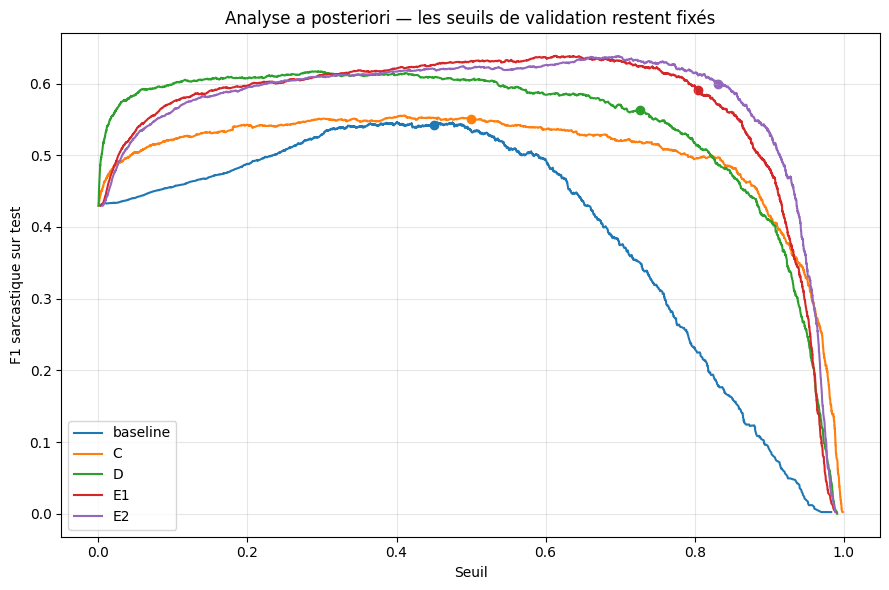

,modele,seuil_val_conserve,seuil_test_optimal_analyse_uniquement,ecart_test_moins_val,F1_test_au_seuil_val,F1_test_optimal_aposteriori
0,baseline,0.4498,0.4005,-0.0493,0.5424,0.5464
1,C,0.5000,0.4109,-0.0891,0.5499,0.5556
2,D,0.7260,0.2945,-0.4316,0.5625,0.6172
3,E1,0.8041,0.6141,-0.1900,0.5908,0.6388
4,E2,0.8317,0.6976,-0.1342,0.5998,0.6386


In [ ]:
y_test_f = labels_binaires(test).to_numpy()
textes_test_f = test["tweet"].astype(str).tolist()

print(
    "Taux sarcasme validation :",
    round(100 * labels_binaires(val).mean(), 2),
    "%"
)

print(
    "Taux sarcasme test :",
    round(100 * y_test_f.mean(), 2),
    "%"
)

predictions_test_f = {}
resultats_f1 = []

# Évaluer toutes les graines déjà disponibles.
for spec in specs_toutes:
    nom = spec["famille"]
    graine = spec["graine"]

    predicteur = PredicteurF(spec)

    scores = predicteur.scores(textes_test_f)
    seuil = float(predicteur.seuil)
    predictions = (scores >= seuil).astype(int)

    predictions_test_f[(nom, graine)] = {
        "scores": scores,
        "predictions": predictions,
        "seuil": seuil
    }

    pd.DataFrame({
        "id": test["id"].to_numpy(),
        "y_true": y_test_f,
        "y_pred": predictions,
        "prob_non_sarcastique": 1 - scores,
        "prob_sarcastique": scores
    }).to_csv(
        f"predictions/{nom}_seed{graine}.csv",
        index=False
    )

    resultats_f1.append({
        "modele": nom,
        "graine": graine,
        "seuil_val": seuil,
        **metriques_f(y_test_f, predictions)
    })

    predicteur.fermer()

tableau_f1 = pd.DataFrame(resultats_f1)
display(tableau_f1.round(4))

tableau_f1.to_csv(
    "results/F/F1_scores_test.csv",
    index=False
)

# Courbe sur test : analyse uniquement, graine 42.
analyse_seuils = []

plt.figure(figsize=(9, 6))

for nom in specs_42:
    sortie = predictions_test_f[(nom, 42)]
    scores = sortie["scores"]
    seuil_val = sortie["seuil"]

    precision, rappel, seuils = precision_recall_curve(
        y_test_f, scores
    )

    f1 = (
        2 * precision[:-1] * rappel[:-1]
        / np.maximum(
            precision[:-1] + rappel[:-1],
            1e-12
        )
    )

    indice = int(np.argmax(f1))
    seuil_test_analyse = float(seuils[indice])

    plt.plot(seuils, f1, label=nom)

    plt.scatter(
        [seuil_val],
        [f1_score(
            y_test_f,
            scores >= seuil_val,
            zero_division=0
        )]
    )

    analyse_seuils.append({
        "modele": nom,
        "seuil_val_conserve": seuil_val,
        "seuil_test_optimal_analyse_uniquement": seuil_test_analyse,
        "ecart_test_moins_val": seuil_test_analyse - seuil_val,
        "F1_test_au_seuil_val": f1_score(
            y_test_f, scores >= seuil_val,
            zero_division=0
        ),
        "F1_test_optimal_aposteriori": float(f1[indice])
    })

plt.xlabel("Seuil")
plt.ylabel("F1 sarcastique sur test")
plt.title("Analyse a posteriori — les seuils de validation restent fixés")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/F/F1_courbe_seuil_test.png",
    dpi=200
)
plt.show()

tableau_seuils = pd.DataFrame(analyse_seuils)
display(tableau_seuils.round(4))

tableau_seuils.to_csv(
    "results/F/F1_analyse_seuils.csv",
    index=False
)

4. Fonctions de réentraînement pour F2 et F3

In [ ]:
@contextmanager
def contexte_reentrainement_f(train_modifie, val_modifie, dossier):
    ancien_train = globals()["train"]
    ancien_val = globals()["val"]
    ancien_dossier = Path.cwd()

    dossier = Path(dossier).resolve()
    dossier.mkdir(parents=True, exist_ok=True)

    try:
        globals()["train"] = train_modifie
        globals()["val"] = val_modifie

        os.chdir(dossier)

        for nom in [
            "results", "predictions",
            "checkpoints", "resources"
        ]:
            Path(nom).mkdir(exist_ok=True)

        yield dossier

    finally:
        globals()["train"] = ancien_train
        globals()["val"] = ancien_val
        os.chdir(ancien_dossier)


def reentrainer_baseline_f(train_df, val_df, graine, dossier):
    debut = time.perf_counter()

    vectoriseur = clone(tfidf)
    classifieur = clone(lr)
    classifieur.set_params(random_state=graine)

    X_train = vectoriseur.fit_transform(
        train_df["tweet"].apply(nettoyer_baseline)
    )

    X_val = vectoriseur.transform(
        val_df["tweet"].apply(nettoyer_baseline)
    )

    y_train = labels_binaires(train_df).to_numpy()
    y_val = labels_binaires(val_df).to_numpy()

    classifieur.fit(X_train, y_train)

    indice = list(classifieur.classes_).index(1)
    scores_val = classifieur.predict_proba(X_val)[:, indice]
    seuil = seuil_optimal_d(y_val, scores_val)

    chemin = Path(dossier) / f"baseline_seed{graine}.joblib"

    joblib.dump({
        "tfidf": vectoriseur,
        "classifieur": classifieur,
        "seuil": seuil
    }, chemin)

    return {
        "checkpoint": str(chemin),
        "val_f1_sarc": f1_score(
            y_val, scores_val >= seuil,
            zero_division=0
        ),
        "temps_entrainement_s": time.perf_counter() - debut
    }


def preparer_donnees_c_f(train_df, val_df, mode_embedding):
    donnees_train = train_df.copy()
    donnees_val = val_df.copy()

    for df in [donnees_train, donnees_val]:
        df["tokens"] = df["tweet"].apply(
            lambda texte: re.findall(
                r"\w+|[^\w\s]",
                normaliser_comparaison(texte)
            )
        )

    frequences = Counter(
        token
        for tokens in donnees_train["tokens"]
        for token in tokens
    )

    nouveau_vocab = {"<PAD>": 0, "<UNK>": 1}

    for token, frequence in sorted(frequences.items()):
        if frequence >= 2 and token not in nouveau_vocab:
            nouveau_vocab[token] = len(nouveau_vocab)

    for df in [donnees_train, donnees_val]:
        df["input_ids"] = df["tokens"].apply(
            lambda tokens: [
                nouveau_vocab.get(token, 1)
                for token in tokens
            ]
        )

    matrice_origine = MATRICES_C[mode_embedding]

    matrice = np.random.default_rng(42).normal(
        0, 0.05,
        (len(nouveau_vocab), matrice_origine.shape[1])
    ).astype("float32")

    # Réutiliser les vecteurs INITIAUX des tokens conservés.
    for token, indice in nouveau_vocab.items():
        if token in vocabulaire:
            matrice[indice] = matrice_origine[
                vocabulaire[token]
            ]

    matrice[0] = 0

    return donnees_train, donnees_val, nouveau_vocab, matrice

In [ ]:
def reentrainer_d2_f(train_df, val_df, graine, dossier):
    global encodeur_d, tokenizer_d, preprocesseur_d

    fixer_graine_c(graine)

    nom = "aubmindlab/bert-base-arabertv02-twitter"

    tokenizer_d = AutoTokenizer.from_pretrained(nom)
    preprocesseur_d = ArabertPreprocessor(model_name=nom)
    encodeur_d = AutoModel.from_pretrained(nom)

    for p in encodeur_d.parameters():
        p.requires_grad = False

    revision = getattr(
        encodeur_d.config, "_commit_hash", None
    )
    dimension = encodeur_d.config.hidden_size

    debut_extraction = time.perf_counter()

    etats_train, _ = extraire_tokens_d2(
        train_df["tweet"].apply(preparer_texte_d).tolist()
    )
    etats_val, _ = extraire_tokens_d2(
        val_df["tweet"].apply(preparer_texte_d).tolist()
    )

    temps_extraction = time.perf_counter() - debut_extraction

    encodeur_d.to("cpu")
    del encodeur_d

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    y_train = labels_binaires(train_df).to_numpy()
    y_val = labels_binaires(val_df).to_numpy()

    loader_train = DataLoader(
        DatasetD2(etats_train, y_train),
        batch_size=32,
        shuffle=True,
        collate_fn=preparer_batch_d2,
        generator=torch.Generator().manual_seed(graine)
    )

    loader_val = DataLoader(
        DatasetD2(etats_val, y_val),
        batch_size=32,
        shuffle=False,
        collate_fn=preparer_batch_d2
    )

    modele = TeteD2(dimension).to(DEVICE_D)

    effectifs = np.bincount(y_train, minlength=2)

    poids = torch.tensor(
        effectifs.sum() / (2 * effectifs),
        dtype=torch.float32,
        device=DEVICE_D
    )

    critere = nn.CrossEntropyLoss(weight=poids)
    optimiseur = torch.optim.Adam(
        modele.parameters(), lr=0.001
    )

    meilleur_f1 = -1
    meilleur_etat = None
    attente = 0
    debut = time.perf_counter()

    for epoque in range(1, 9):
        modele.train()

        for etats, longueurs, labels in loader_train:
            optimiseur.zero_grad(set_to_none=True)

            perte = critere(
                modele(etats.to(DEVICE_D), longueurs),
                labels.to(DEVICE_D)
            )

            perte.backward()
            nn.utils.clip_grad_norm_(
                modele.parameters(), 1.0
            )
            optimiseur.step()

        y, scores = predire_d2(modele, loader_val)

        f1 = f1_score(
            y, scores >= 0.5,
            zero_division=0
        )

        print(f"D2 seed {graine}, époque {epoque}, F1 val {f1:.4f}")

        if f1 > meilleur_f1 + 1e-8:
            meilleur_f1 = f1
            attente = 0
            meilleur_etat = {
                k: v.detach().cpu().clone()
                for k, v in modele.state_dict().items()
            }
        else:
            attente += 1
            if attente >= 2:
                break

    modele.load_state_dict(meilleur_etat)
    y, scores = predire_d2(modele, loader_val)
    seuil = seuil_optimal_d(y, scores)

    chemin = Path(dossier) / f"D2_seed{graine}.pt"

    torch.save({
        "state_dict": meilleur_etat,
        "dimension_entree": dimension,
        "hidden_size": 64,
        "dropout": 0.3,
        "encodeur": nom,
        "revision_encodeur": revision,
        "max_length": MAX_LEN_D,
        "seuil": seuil,
        "pretraitement": "guillemets retires + ArabertPreprocessor"
    }, chemin)

    resultat = {
        "checkpoint": str(chemin),
        "val_f1_sarc": f1_score(
            y, scores >= seuil,
            zero_division=0
        ),
        "temps_entrainement_s": time.perf_counter() - debut,
        "temps_extraction_s": temps_extraction
    }

    del modele, optimiseur, etats_train, etats_val
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return resultat

In [ ]:
def reentrainer_f(spec, train_df, val_df, etiquette, graine=42):
    dossier = (
        RACINE_F / "experiences_F"
        / etiquette / spec["famille"] / f"seed{graine}"
    )

    dossier.mkdir(parents=True, exist_ok=True)

    with contexte_reentrainement_f(
        train_df, val_df, dossier
    ):
        if spec["type"] == "baseline":
            resultat = reentrainer_baseline_f(
                train_df, val_df, graine, dossier
            )

        elif spec["type"] == "C":
            sauvegarde = torch.load(
                spec["checkpoint"],
                map_location="cpu",
                weights_only=False
            )

            config = {
                **sauvegarde["config"],
                "seed": graine
            }
            del sauvegarde

            tr, va, vocab, matrice = preparer_donnees_c_f(
                train_df,
                val_df,
                config["embedding"]
            )

            resultat = entrainer_c(
                config,
                matrice,
                train_df=tr,
                val_df=va,
                vocab=vocab
            )

        elif spec["type"] == "D2":
            resultat = reentrainer_d2_f(
                train_df, val_df, graine, dossier
            )

        else:
            sauvegarde = torch.load(
                spec["checkpoint"],
                map_location="cpu",
                weights_only=False
            )

            nom_court = (
                "AraBERT"
                if "arabert" in sauvegarde["nom_modele"].lower()
                else "MARBERT"
            )

            multitache = sauvegarde["multitache"]
            lam = sauvegarde["lambda"]
            del sauvegarde

            resultat = entrainer_e(
                nom_court=nom_court,
                multitache=multitache,
                lam=lam,
                graine=graine
            )

        chemin = Path(resultat["checkpoint"])

        if not chemin.is_absolute():
            chemin = Path.cwd() / chemin

        resultat["checkpoint"] = str(chemin.resolve())

    nouvelle_spec = creer_spec_f(
        spec["famille"],
        spec["type"],
        resultat["checkpoint"],
        graine,
        resultat["val_f1_sarc"]
    )

    # Ajouter la trace du réentraînement au journal principal.
    trace = {
        "modele": f"{etiquette}_{spec['famille']}",
        "graine": graine,
        "protocole": etiquette,
        **{
            k: v for k, v in resultat.items()
            if not isinstance(v, dict)
        }
    }

    fichier = RACINE_F / "results/results.csv"
    lignes = pd.DataFrame([trace])

    if fichier.exists():
        lignes = pd.concat(
            [pd.read_csv(fichier), lignes],
            ignore_index=True
        )

    lignes.to_csv(fichier, index=False)

    return nouvelle_spec

5. F2 — Retirer le dialecte égyptien de train

In [ ]:
meilleur_e_f = max(
    [specs_42["E1"], specs_42["E2"]],
    key=lambda s: s["f1_val"]
)

train_sans_egypt = train.loc[
    train["dialect"].ne("egypt")
].copy()

spec_sans_egypt = reentrainer_f(
    meilleur_e_f,
    train_sans_egypt,
    val,
    etiquette="F2_sans_egypt",
    graine=42
)

masque_egypt = test["dialect"].eq("egypt").to_numpy()

assert masque_egypt.any(), "Aucun tweet egypt dans test."

resultats_f2 = []

for condition, spec in [
    ("train_complet", meilleur_e_f),
    ("train_sans_egypt", spec_sans_egypt)
]:
    predicteur = PredicteurF(spec)

    scores = predicteur.scores(
        test.loc[masque_egypt, "tweet"].tolist()
    )

    predictions = (
        scores >= predicteur.seuil
    ).astype(int)

    resultats_f2.append({
        "condition": condition,
        "modele": spec["famille"],
        "effectif_test_egypt": int(masque_egypt.sum()),
        "seuil_val": predicteur.seuil,
        **metriques_f(
            y_test_f[masque_egypt],
            predictions
        )
    })

    predicteur.fermer()

tableau_f2 = pd.DataFrame(resultats_f2)
display(tableau_f2.round(4))

chute_f2 = (
    tableau_f2.iloc[0]["f1_sarc"]
    - tableau_f2.iloc[1]["f1_sarc"]
)

print("Chute du F1 sur egypt :", chute_f2)
print("Tweets magreb dans train :", train["dialect"].eq("magreb").sum())
print("Tweets magreb dans test :", test["dialect"].eq("magreb").sum())

tableau_f2.to_csv(
    "results/F/F2_dialecte_non_vu.csv",
    index=False
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E2_AraBERT_lambda0.3_seed42 | époque 1 | F1 val 0.6731 | seuil 0.7021
E2_AraBERT_lambda0.3_seed42 | époque 2 | F1 val 0.6795 | seuil 0.5329
E2_AraBERT_lambda0.3_seed42 | époque 3 | F1 val 0.6653 | seuil 0.6493
E2_AraBERT_lambda0.3_seed42 | époque 4 | F1 val 0.6642 | seuil 0.1011
Early stopping.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,condition,modele,effectif_test_egypt,seuil_val,accuracy,precision_sarc,rappel_sarc,f1_sarc,macro_f1
0,train_complet,E2,306,0.8317,0.7680,0.7442,0.8258,0.7829,0.7669
1,train_sans_egypt,E2,306,0.5329,0.7451,0.6974,0.8774,0.7771,0.7397


Chute du F1 sur egypt : 0.005731760594145929
Tweets magreb dans train : 35
Tweets magreb dans test : 2


6. F3 — URL, mentions et réentraînement sans ces indices

In [ ]:
masque_url_f = test["tweet"].astype(str).str.contains(
    r"https?://\S+|www\.\S+",
    regex=True
).to_numpy()

train_sans_raccourcis = train.copy()
val_sans_raccourcis = val.copy()

train_sans_raccourcis["tweet"] = (
    train_sans_raccourcis["tweet"]
    .apply(retirer_raccourcis_f)
)

val_sans_raccourcis["tweet"] = (
    val_sans_raccourcis["tweet"]
    .apply(retirer_raccourcis_f)
)

specs_f3 = {}
resultats_f3 = []

for nom, spec in specs_42.items():
    nouvelle_spec = reentrainer_f(
        spec,
        train_sans_raccourcis,
        val_sans_raccourcis,
        etiquette="F3_sans_URL_mentions",
        graine=42
    )

    nouvelle_spec["sans_raccourcis"] = True
    specs_f3[nom] = nouvelle_spec

    predicteur = PredicteurF(nouvelle_spec)

    scores_apres = predicteur.scores(textes_test_f)

    predictions_apres = (
        scores_apres >= predicteur.seuil
    ).astype(int)

    predictions_avant = predictions_test_f[
        (nom, 42)
    ]["predictions"]

    for condition, predictions in [
        ("original", predictions_avant),
        ("reentraine_sans_URL_mentions", predictions_apres)
    ]:
        for sous_groupe, masque in [
            ("avec_URL", masque_url_f),
            ("sans_URL", ~masque_url_f),
            ("test_complet", np.ones(len(test), dtype=bool))
        ]:
            if not masque.any():
                continue

            resultats_f3.append({
                "modele": nom,
                "condition": condition,
                "sous_groupe": sous_groupe,
                "effectif": int(masque.sum()),
                **metriques_f(
                    y_test_f[masque],
                    predictions[masque]
                )
            })

    pd.DataFrame({
        "id": test["id"].to_numpy(),
        "y_true": y_test_f,
        "y_pred": predictions_apres,
        "prob_sarcastique": scores_apres
    }).to_csv(
        f"predictions/F3_{nom}_seed42.csv",
        index=False
    )

    predicteur.fermer()

tableau_f3 = pd.DataFrame(resultats_f3)
display(tableau_f3.round(4))

tableau_f3.to_csv(
    "results/F/F3_raccourcis.csv",
    index=False
)

C1_aravec_thaw_pos1_weighted_seed42 | époque 1 | perte 0.5898 | F1 val 0.4470
C1_aravec_thaw_pos1_weighted_seed42 | époque 2 | perte 0.5140 | F1 val 0.4740
C1_aravec_thaw_pos1_weighted_seed42 | époque 3 | perte 0.4660 | F1 val 0.4873
C1_aravec_thaw_pos1_weighted_seed42 | époque 4 | perte 0.4254 | F1 val 0.5127
C1_aravec_thaw_pos1_weighted_seed42 | époque 5 | perte 0.3870 | F1 val 0.5072
C1_aravec_thaw_pos1_weighted_seed42 | époque 6 | perte 0.3524 | F1 val 0.5157
C1_aravec_thaw_pos1_weighted_seed42 | époque 7 | perte 0.3178 | F1 val 0.5143
C1_aravec_thaw_pos1_weighted_seed42 | époque 8 | perte 0.2835 | F1 val 0.5137
Early stopping.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Extraction des tokens D2:   0%|          | 0/342 [00:00<?, ?it/s]

Extraction des tokens D2:   0%|          | 0/40 [00:00<?, ?it/s]

...

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E2_AraBERT_lambda0.3_seed42 | époque 1 | F1 val 0.6910 | seuil 0.7872
E2_AraBERT_lambda0.3_seed42 | époque 2 | F1 val 0.6899 | seuil 0.7317
E2_AraBERT_lambda0.3_seed42 | époque 3 | F1 val 0.6901 | seuil 0.3816
Early stopping.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,modele,condition,sous_groupe,effectif,accuracy,precision_sarc,rappel_sarc,f1_sarc,macro_f1
0,baseline,original,avec_URL,440,0.9477,0.1111,0.0625,0.0800,0.5265
1,baseline,original,sans_URL,2560,0.6418,0.4542,0.6907,0.5481,0.6257
2,baseline,original,test_complet,3000,0.6867,0.4517,0.6784,0.5424,0.6521
3,baseline,reentraine_sans_URL_mentions,avec_URL,440,0.7659,0.0693,0.4375,0.1197,0.4923
4,baseline,reentraine_sans_URL_mentions,sans_URL,2560,0.6082,0.4310,0.7677,0.5520,0.6019
5,baseline,reentraine_sans_URL_mentions,test_complet,3000,0.6313,0.4072,0.7613,0.5306,0.6135
6,C,original,avec_URL,440,0.9068,0.0690,0.1250,0.0889,0.5199
7,C,original,sans_URL,2560,0.6746,0.4872,0.6609,0.5609,0.6512
8,C,original,test_complet,3000,0.7087,0.4764,0.6504,0.5499,0.6673
9,C,reentraine_sans_URL_mentions,avec_URL,440,0.8500,0.0833,0.3125,0.1316,0.5247


7. F4 — Supprimer les marqueurs sur les vrais positifs

In [ ]:
import emoji

if hasattr(emoji, "emoji_list"):
    def retirer_emojis_f(texte):
        elements = emoji.emoji_list(texte)

        for element in reversed(elements):
            texte = (
                texte[:element["match_start"]]
                + " "
                + texte[element["match_end"]:]
            )

        return texte

else:
    regex_emojis_f = emoji.get_emoji_regexp()

    def retirer_emojis_f(texte):
        return regex_emojis_f.sub(" ", texte)


def retirer_marqueurs_f(texte):
    texte = retirer_emojis_f(str(texte))

    # Même marqueur de rire arabe que dans l'audit.
    texte = re.sub(r"ه{3,}", " ", texte)

    # Supprimer les groupes de ponctuation identique répétée.
    texte = re.sub(
        r"([!?؟.,،؛:…])\1+",
        " ",
        texte
    )

    return re.sub(r"\s+", " ", texte).strip()


resultats_f4 = []

for nom, spec in specs_42.items():
    predictions_originales = predictions_test_f[
        (nom, 42)
    ]["predictions"]

    vrais_positifs = (
        (y_test_f == 1)
        & (predictions_originales == 1)
    )

    indices = np.flatnonzero(vrais_positifs)

    if len(indices) == 0:
        resultats_f4.append({
            "modele": nom,
            "vrais_positifs_initiaux": 0,
            "taux_detection_apres_pct": np.nan,
            "chute_points_pct": np.nan
        })
        continue

    textes_modifies = [
        retirer_marqueurs_f(textes_test_f[i])
        for i in indices
    ]

    predicteur = PredicteurF(spec)
    scores = predicteur.scores(textes_modifies)

    toujours_detectes = scores >= predicteur.seuil
    taux_apres = 100 * toujours_detectes.mean()

    resultats_f4.append({
        "modele": nom,
        "vrais_positifs_initiaux": len(indices),
        "tweets_effectivement_modifies": sum(
            nouveau != textes_test_f[i]
            for nouveau, i in zip(textes_modifies, indices)
        ),
        "taux_detection_avant_pct": 100.0,
        "taux_detection_apres_pct": taux_apres,
        "chute_points_pct": 100 - taux_apres
    })

    predicteur.fermer()

tableau_f4 = pd.DataFrame(resultats_f4)
display(tableau_f4.round(2))

tableau_f4.to_csv(
    "results/F/F4_suppression_marqueurs.csv",
    index=False
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,modele,vrais_positifs_initiaux,tweets_effectivement_modifies,taux_detection_avant_pct,taux_detection_apres_pct,chute_points_pct
0,baseline,557,518,100.0,94.25,5.75
1,C,534,497,100.0,94.76,5.24
2,D,425,401,100.0,92.00,8.00
3,E1,467,442,100.0,94.00,6.00
4,E2,487,463,100.0,94.46,5.54


8. F5 — Trois graines, bootstrap et McNemar

In [ ]:
for famille in ["baseline", "D"]:
    for graine in [43, 44]:
        nouvelle_spec = reentrainer_f(
            specs_42[famille],
            train,
            val,
            etiquette="F5_graines",
            graine=graine
        )

        specs_toutes.append(nouvelle_spec)

        predicteur = PredicteurF(nouvelle_spec)
        scores = predicteur.scores(textes_test_f)

        predictions = (
            scores >= predicteur.seuil
        ).astype(int)

        predictions_test_f[(famille, graine)] = {
            "scores": scores,
            "predictions": predictions,
            "seuil": predicteur.seuil
        }

        pd.DataFrame({
            "id": test["id"].to_numpy(),
            "y_true": y_test_f,
            "y_pred": predictions,
            "prob_non_sarcastique": 1 - scores,
            "prob_sarcastique": scores
        }).to_csv(
            f"predictions/{famille}_seed{graine}.csv",
            index=False
        )

        predicteur.fermer()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Extraction des tokens D2:   0%|          | 0/342 [00:00<?, ?it/s]

Extraction des tokens D2:   0%|          | 0/40 [00:00<?, ?it/s]

D2 seed 43, époque 1, F1 val 0.6316
D2 seed 43, époque 2, F1 val 0.6144
D2 seed 43, époque 3, F1 val 0.6711
D2 seed 43, époque 4, F1 val 0.6584
D2 seed 43, époque 5, F1 val 0.6384


...

Extraction des tokens D2:   0%|          | 0/342 [00:00<?, ?it/s]

Extraction des tokens D2:   0%|          | 0/40 [00:00<?, ?it/s]

D2 seed 44, époque 1, F1 val 0.6400
D2 seed 44, époque 2, F1 val 0.6174
D2 seed 44, époque 3, F1 val 0.6587
D2 seed 44, époque 4, F1 val 0.6427
D2 seed 44, époque 5, F1 val 0.6087


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def f1_rapide_f(y, prediction):
    tp = np.sum((y == 1) & (prediction == 1))
    fp = np.sum((y == 0) & (prediction == 1))
    fn = np.sum((y == 1) & (prediction == 0))

    denominateur = 2 * tp + fp + fn

    return 2 * tp / denominateur if denominateur else 0.0


def bootstrap_f1_f(y, prediction, n_boot=1000):
    rng = np.random.default_rng(42)
    valeurs = []

    for _ in range(n_boot):
        indices = rng.integers(
            0, len(y), size=len(y)
        )

        valeurs.append(
            f1_rapide_f(
                y[indices],
                prediction[indices]
            )
        )

    return np.percentile(valeurs, [2.5, 97.5])


resultats_f5 = []

for (nom, graine), sortie in predictions_test_f.items():
    prediction = sortie["predictions"]

    borne_basse, borne_haute = bootstrap_f1_f(
        y_test_f,
        prediction
    )

    resultats_f5.append({
        "modele": nom,
        "graine": graine,
        "F1_test": f1_rapide_f(y_test_f, prediction),
        "IC95_bas": borne_basse,
        "IC95_haut": borne_haute
    })

tableau_f5 = pd.DataFrame(resultats_f5)

resume_graines = tableau_f5.groupby(
    "modele"
)["F1_test"].agg(
    moyenne="mean",
    ecart_type="std",
    nombre_graines="count"
).reset_index()

display(tableau_f5.round(4))
display(resume_graines.round(4))

tableau_f5.to_csv(
    "results/F/F5_bootstrap_par_graine.csv",
    index=False
)

resume_graines.to_csv(
    "results/F/F5_moyenne_ecart_type.csv",
    index=False
)

,modele,graine,F1_test,IC95_bas,IC95_haut
0,baseline,42,0.5424,0.5138,0.5700
1,C,42,0.5499,0.5229,0.5770
2,C,43,0.5381,0.5135,0.5649
3,C,44,0.5525,0.5262,0.5787
4,D,42,0.5625,0.5331,0.5917
5,E1,42,0.5908,0.5629,0.6190
6,E1,43,0.6036,0.5764,0.6316
7,E1,44,0.6056,0.5794,0.6341
8,E2,42,0.5998,0.5722,0.6281
9,E2,43,0.6184,0.5915,0.6433


,modele,moyenne,ecart_type,nombre_graines
0,C,0.5468,0.0077,3
1,D,0.5710,0.0110,3
2,E1,0.6000,0.0080,3
3,E2,0.6094,0.0094,3
4,baseline,0.5424,0.0000,3


In [ ]:
y_test_f = np.asarray(y_test_f)

prediction_a = np.asarray(
    predictions_test_f[("D", 43)]["predictions"]
)
prediction_b = np.asarray(
    predictions_test_f[("baseline", 43)]["predictions"]
)

rng = np.random.default_rng(42)
differences_f1 = []

for _ in range(1000):
    indices = rng.integers(
        0, len(y_test_f), size=len(y_test_f)
    )

    differences_f1.append(
        f1_rapide_f(
            y_test_f[indices],
            prediction_a[indices]
        )
        - f1_rapide_f(
            y_test_f[indices],
            prediction_b[indices]
        )
    )

ic_difference = np.percentile(
    differences_f1, [2.5, 97.5]
)

difference = (
    f1_rapide_f(y_test_f, prediction_a)
    - f1_rapide_f(y_test_f, prediction_b)
)

print("Différence F1 D − baseline :", difference)
print("IC95 de la différence :", ic_difference)

Différence F1 D − baseline : 0.024807801305061772
IC95 de la différence : [-0.00607628  0.05362048]


Test de McNemar — comparaison E1 et E2, graine 42

In [ ]:
from google.colab import files
from pathlib import Path

Path("predictions").mkdir(exist_ok=True)

for modele in ["E1", "E2"]:
    print(f"Sélectionne le fichier {modele}_seed42.csv")
    fichiers = files.upload()

    if len(fichiers) != 1:
        raise ValueError("Sélectionne un seul fichier à la fois.")

    nom_recu, contenu = next(iter(fichiers.items()))

    if not Path(nom_recu).name.startswith(f"{modele}_seed42"):
        raise ValueError(f"Le fichier sélectionné doit correspondre à {modele}.")

    destination = Path("predictions") / f"{modele}_seed42.csv"
    destination.write_bytes(contenu)

    print(f"Enregistré : {destination}\n")

print("Import terminé. Relance uniquement la cellule McNemar.")

Sélectionne le fichier E1_seed42.csv


Saving E1_seed42.csv to E1_seed42 (2).csv
Enregistré : predictions/E1_seed42.csv

Sélectionne le fichier E2_seed42.csv


Saving E2_seed42.csv to E2_seed42.csv
Enregistré : predictions/E2_seed42.csv

Import terminé. Relance uniquement la cellule McNemar.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import binomtest

# Charger et aligner les prédictions par identifiant.
def charger_predictions(nom):
    df = pd.read_csv(f"predictions/{nom}_seed42.csv")

    if not {"id", "y_true", "y_pred"}.issubset(df.columns):
        raise ValueError(f"Colonnes manquantes pour {nom}.")

    if not df["id"].is_unique:
        raise ValueError(f"Identifiants répétés pour {nom}.")

    for colonne in ["y_true", "y_pred"]:
        if not df[colonne].isin([0, 1]).all():
            raise ValueError(f"Labels invalides pour {nom}.")

    return df.set_index("id").sort_index()

e1 = charger_predictions("E1")
e2 = charger_predictions("E2")

if not e1.index.equals(e2.index):
    raise ValueError("Les fichiers ne contiennent pas les mêmes tweets.")

if not np.array_equal(e1["y_true"], e2["y_true"]):
    raise ValueError("Les vrais labels ne correspondent pas.")

correct_e1 = (e1["y_pred"] == e1["y_true"]).to_numpy()
correct_e2 = (e2["y_pred"] == e2["y_true"]).to_numpy()

# Tableau des prédictions correctes / incorrectes.
les_deux_corrects = int((correct_e1 & correct_e2).sum())
e1_seul_correct = int((correct_e1 & ~correct_e2).sum())
e2_seul_correct = int((~correct_e1 & correct_e2).sum())
les_deux_incorrects = int((~correct_e1 & ~correct_e2).sum())

tableau = pd.DataFrame(
    [
        [les_deux_corrects, e1_seul_correct],
        [e2_seul_correct, les_deux_incorrects]
    ],
    index=["E1 correct", "E1 incorrect"],
    columns=["E2 correct", "E2 incorrect"]
)

display(tableau)

# Test exact de McNemar.
desaccords = e1_seul_correct + e2_seul_correct

p_value = (
    binomtest(
        e1_seul_correct,
        n=desaccords,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if desaccords > 0 else 1.0
)

resultat = pd.DataFrame([{
    "modele_A": "E1",
    "modele_B": "E2",
    "graine": 42,
    "nombre_tweets": len(e1),
    "E1_correct_E2_incorrect": e1_seul_correct,
    "E1_incorrect_E2_correct": e2_seul_correct,
    "p_value": p_value,
    "significatif_5pct": p_value < 0.05
}])

display(resultat)

Path("results/F").mkdir(parents=True, exist_ok=True)
resultat.to_csv("results/F/F5_McNemar.csv", index=False)

print("p-value :", p_value)

if p_value < 0.05:
    print("Différence significative des taux d’erreur au seuil de 5 %.")
else:
    print("Pas de différence significative détectée au seuil de 5 %.")

print("Résultat enregistré dans results/F/F5_McNemar.csv")

,E2 correct,E2 incorrect
E1 correct,2318,35
E1 incorrect,32,615


,modele_A,modele_B,graine,nombre_tweets,E1_correct_E2_incorrect,E1_incorrect_E2_correct,p_value,significatif_5pct
0,E1,E2,42,3000,35,32,0.807195,False


p-value : 0.8071946913670247
Pas de différence significative détectée au seuil de 5 %.
Résultat enregistré dans results/F/F5_McNemar.csv


In [ ]:
from google.colab import files

files.download("results/F/F5_McNemar.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

9. F6 — Préparer les 30 erreurs à analyser

In [ ]:
cles_contradictoires_f = set()

for fichier in Path("results").glob("conflits_*.csv"):
    conflits = pd.read_csv(fichier)

    if "tweet" in conflits.columns:
        cles_contradictoires_f.update(
            conflits["tweet"].astype(str).apply(
                normaliser_comparaison
            )
        )

rng = np.random.default_rng(42)

for nom in specs_42:
    predictions = predictions_test_f[
        (nom, 42)
    ]["predictions"]

    faux_negatifs = np.flatnonzero(
        (y_test_f == 1) & (predictions == 0)
    )

    faux_positifs = np.flatnonzero(
        (y_test_f == 0) & (predictions == 1)
    )

    lignes = []

    for type_erreur, indices in [
        ("faux_negatif", faux_negatifs),
        ("faux_positif", faux_positifs)
    ]:
        selection = rng.choice(
            indices,
            size=min(15, len(indices)),
            replace=False
        )

        for indice in selection:
            ligne = test.iloc[indice]

            lignes.append({
                "id": ligne["id"],
                "tweet": ligne["tweet"],
                "dialect": ligne["dialect"],
                "sentiment": ligne["sentiment"],
                "y_true": y_test_f[indice],
                "y_pred": predictions[indice],
                "type_erreur": type_erreur,
                "doublon_contradictoire_4_1": (
                    normaliser_comparaison(ligne["tweet"])
                    in cles_contradictoires_f
                ),
                "categorie_principale": "",
                "justification": ""
            })

    erreurs = pd.DataFrame(lignes)

    erreurs.to_csv(
        f"results/F/F6_erreurs_{nom}_a_classer.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(
        nom,
        "— FN sélectionnés :", min(15, len(faux_negatifs)),
        "— FP sélectionnés :", min(15, len(faux_positifs))
    )

baseline — FN sélectionnés : 15 — FP sélectionnés : 15
C — FN sélectionnés : 15 — FP sélectionnés : 15
D — FN sélectionnés : 15 — FP sélectionnés : 15
E1 — FN sélectionnés : 15 — FP sélectionnés : 15
E2 — FN sélectionnés : 15 — FP sélectionnés : 15


In [ ]:
from google.colab import files
from pathlib import Path
from IPython.display import display
import pandas as pd
import io

print("Sélectionne F6_erreurs_E2_a_classer.csv")
fichiers = files.upload()

if len(fichiers) != 1:
    raise ValueError("Sélectionne un seul fichier CSV.")

nom, contenu = next(iter(fichiers.items()))

erreurs = pd.read_csv(
    io.BytesIO(contenu),
    encoding="utf-8-sig"
)

colonnes_requises = {
    "id", "tweet", "y_true", "y_pred", "type_erreur"
}

if not colonnes_requises.issubset(erreurs.columns):
    raise ValueError("Ce fichier ne contient pas les colonnes attendues.")

for colonne in ["categorie_principale", "justification"]:
    if colonne not in erreurs.columns:
        erreurs[colonne] = ""
    erreurs[colonne] = erreurs[colonne].fillna("").astype(str)

# Conserver le fichier sous un nom fixe, même si Colab le renomme.
chemin = Path("results/F/F6_erreurs_E2_a_classer.csv")
chemin.parent.mkdir(parents=True, exist_ok=True)
erreurs.to_csv(chemin, index=False, encoding="utf-8-sig")

print("\nNombre d’erreurs :", len(erreurs))
print(erreurs["type_erreur"].value_counts())

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(erreurs[[
        "id", "tweet", "y_true", "y_pred",
        "type_erreur", "categorie_principale", "justification"
    ]])

Sélectionne F6_erreurs_E2_a_classer.csv


Saving F6_erreurs_E2_a_classer.csv to F6_erreurs_E2_a_classer.csv

Nombre d’erreurs : 30
type_erreur
faux_negatif    15
faux_positif    15
Name: count, dtype: int64


,id,tweet,y_true,y_pred,type_erreur,categorie_principale,justification
0,2159,في ظل هذا الحزن من المضحك ان تقرا بان البنك المستهدف هو بنك ايراني وان احدهم يقول ان تفجيره من قبل الشيعة لاتهام داعش #البحرين,1,0,faux_negatif,,
1,419,في بلايستيشن3 من الممكن أن تلغي التسلل وفي الدوري السعودي من الممكن أن تلغي ركلات الجزاء :)..! #النصر_الفيصلي #متصدر_لاتكلمني,1,0,faux_negatif,,
2,2337,#Polytechnic التعليم بلغة الغرب والعياذ. بالله! اللغة الاجنبية الغربية الكافرة,1,0,faux_negatif,,
3,1955,اول مرة يطلع ابو التكسي انسان محترم ومارفض يوصلني ...بالعاده التكاسي لازم تاخذ اذنهم وتسالهم وين تحبون تروحون ؟؟ #ازمة_تكاسي,1,0,faux_negatif,,
4,1965,"مش بتقلدوا الأجانب في قصة الشعر و المنطلون المقطع والموضة ؟ طب حاولوا تقلدوهم في نظافة شوارعهم وبيوتهم ف إختيار ألفاظهم ف أمانتهم ف إحترامهم للآخرين ف رفضهم للغلط ف ضميرهم الصاحي . أعتقد الأشياء إللي قولتها تساعد ف بنـاء المجتمع ,, ومش المنطلون ابو وسط ساقط ( البنطلون)",1,0,faux_negatif,,
5,2004,و العرب سكتوا عا مجزرة حماة بالسبعينيات و سكتوا عا كل التدمير بلبنان و هني بيرموا كل المسؤولية عا الغرب و بيرجعوا بيحكوا بالانتداب,1,0,faux_negatif,,
6,1774,عيال الوفاق يلعبون بالكلاشنكوف واحناالجراخيه ممنوعه ولاعندالجسراذا بتدخلهم سولك محضر ويمنعون انهاتدش الاالكلاشنكوف اشلون دشت ؟ القدر,1,0,faux_negatif,,
7,331,"أتصور لو ابن سينا كان في هذا الزمان، جان فتح له مطعم ووفر الأوراق التي كتب عليها كتاب ""الإشارات"" لتغليف السندويشات #iSay",1,0,faux_negatif,,
8,302,مش مهم في كارثة سقوط طيارة إن وزير الطيران بقاله أكثر من ساعة بيتكلم في مؤتمر صحفي. المهم إنه مقالش معلومة واحدة,1,0,faux_negatif,,
9,2237,#رسالة_لكل_مدخن_ومدخنه عادي الناس الي حولكم يستمتعوا بريحتكم الجميلة وبياض اسنانكم ونفسيتكم المرتاحة -.-,1,0,faux_negatif,,


In [ ]:
categories = {
    "1": "contexte_connaissance_du_monde",
    "2": "ironie_sans_marqueur",
    "3": "marqueur_mal_interprete",
    "4": "dialecte",
    "5": "bruit_annotation"
}

chemin_complete = Path("results/F/F6_erreurs_E2_complete.csv")

for index, ligne in erreurs.iterrows():
    # Ne pas redemander les annotations déjà remplies.
    if (
        ligne["categorie_principale"].strip()
        and ligne["justification"].strip()
    ):
        continue

    print("\n" + "=" * 50)
    print("ID :", ligne["id"])
    print("Erreur :", ligne["type_erreur"])
    print("Tweet :", ligne["tweet"])
    print("""
1 : Contexte ou connaissance du monde nécessaire
2 : Ironie sans marqueur explicite
3 : Marqueur mal interprété
4 : Difficulté liée au dialecte
5 : Bruit d’annotation suspecté
0 : Passer ce tweet
q : Arrêter
""")

    choix = input("Numéro de la catégorie : ").strip().lower()

    while choix not in {*categories, "0", "q"}:
        choix = input("Choisis 1 à 5, 0 ou q : ").strip().lower()

    if choix == "q":
        break

    if choix == "0":
        continue

    justification = input(
        "Courte explication de ton choix : "
    ).strip()

    if not justification:
        print("Justification vide : tweet laissé à compléter.")
        continue

    erreurs.at[index, "categorie_principale"] = categories[choix]
    erreurs.at[index, "justification"] = justification

    erreurs.to_csv(
        chemin_complete,
        index=False,
        encoding="utf-8-sig"
    )

    print("Annotation sauvegardée.")

# Enregistrer aussi si tu as choisi de passer ou d’arrêter.
erreurs.to_csv(
    chemin_complete,
    index=False,
    encoding="utf-8-sig"
)

completes = (
    erreurs["categorie_principale"].str.strip().ne("")
    & erreurs["justification"].str.strip().ne("")
)

print(f"\nErreurs complétées : {completes.sum()} / {len(erreurs)}")
files.download(str(chemin_complete))


ID : 2159
Erreur : faux_negatif
Tweet : في ظل هذا الحزن من المضحك ان تقرا بان البنك المستهدف هو بنك ايراني وان احدهم يقول ان تفجيره من قبل الشيعة لاتهام داعش   #البحرين

1 : Contexte ou connaissance du monde nécessaire
2 : Ironie sans marqueur explicite
3 : Marqueur mal interprété
4 : Difficulté liée au dialecte
5 : Bruit d’annotation suspecté
0 : Passer ce tweet
q : Arrêter

Numéro de la catégorie : 1
Courte explication de ton choix : Le tweet tourne en dérision une explication de l’attentat. Comprendre les acteurs et le contexte politique aide à saisir cette moquerie.
Annotation sauvegardée.

ID : 419
Erreur : faux_negatif
Tweet : في بلايستيشن3 من الممكن أن تلغي التسلل وفي الدوري السعودي من الممكن أن تلغي ركلات الجزاء :)..! #النصر_الفيصلي #متصدر_لاتكلمني

1 : Contexte ou connaissance du monde nécessaire
2 : Ironie sans marqueur explicite
3 : Marqueur mal interprété
4 : Difficulté liée au dialecte
5 : Bruit d’annotation suspecté
0 : Passer ce tweet
q : Arrêter

Numéro de la catégorie

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

COMPARAISON AVEC labels contradictoires

In [ ]:
import io
import re
import unicodedata
import zipfile
import pandas as pd

from pathlib import Path
from google.colab import files
from sklearn.model_selection import train_test_split

# 1. Importer le CSV annoté
print("Sélectionne ton CSV E2 avec catégories et justifications.")
uploads = files.upload()

if len(uploads) != 1:
    raise ValueError("Sélectionne un seul fichier CSV.")

contenu = next(iter(uploads.values()))
erreurs_f6 = pd.read_csv(io.BytesIO(contenu), encoding="utf-8-sig")

colonnes = {"tweet", "categorie_principale", "justification"}
if not colonnes.issubset(erreurs_f6.columns):
    raise ValueError("Le fichier ne contient pas les colonnes attendues.")

# 2. Même normalisation que dans ta partie 4.1
def normaliser_croisement(texte):
    texte = unicodedata.normalize("NFC", str(texte)).strip()

    if len(texte) >= 2 and texte.startswith('"') and texte.endswith('"'):
        texte = texte[1:-1]

    texte = re.sub(r"[\u064B-\u065F\u0670]", "", texte)
    texte = texte.replace("\u0640", "")
    texte = re.sub(r"[أإآٱ]", "ا", texte)
    return re.sub(r"\s+", " ", texte).strip()

# 3. Recharger les données dans des variables séparées
BASE = (
    "https://raw.githubusercontent.com/"
    "iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"
)

full_verif = pd.read_csv(BASE + "training_data.csv")
test_verif = pd.read_csv(BASE + "testing_data.csv")

full_verif["id"] = range(len(full_verif))
test_verif["id"] = range(len(test_verif))

train_verif, _ = train_test_split(
    full_verif,
    test_size=0.10,
    random_state=42,
    stratify=full_verif["sarcasm"]
)

# Audit sur train AVANT nettoyage et sur le test officiel
audit_verif = pd.concat([
    train_verif.assign(ensemble="train_avant_nettoyage"),
    test_verif.assign(ensemble="test")
], ignore_index=True)

audit_verif["texte_normalise"] = (
    audit_verif["tweet"].apply(normaliser_croisement)
)

audit_verif["label_binaire"] = (
    audit_verif["sarcasm"].astype(str).str.strip().str.lower()
    .map({"true": 1, "false": 0, "1": 1, "0": 0})
)

if audit_verif["label_binaire"].isna().any():
    raise ValueError("Label de sarcasme inattendu.")

# 4. Repérer les mêmes textes portant des labels différents
non_vides = audit_verif["texte_normalise"].ne("")

diversite = (
    audit_verif.loc[non_vides]
    .groupby("texte_normalise")["label_binaire"]
    .nunique()
)

cles_contradictoires = set(diversite[diversite > 1].index)

conflits = audit_verif.loc[
    audit_verif["texte_normalise"].isin(cles_contradictoires)
].copy()

# 5. Croiser les 30 erreurs avec cette liste
# Les catégories et justifications sont conservées.
annotations_avant = erreurs_f6[
    ["categorie_principale", "justification"]
].copy()

erreurs_f6["doublon_contradictoire_4_1"] = (
    erreurs_f6["tweet"]
    .apply(normaliser_croisement)
    .isin(cles_contradictoires)
)

assert erreurs_f6[
    ["categorie_principale", "justification"]
].equals(annotations_avant)

# 6. Enregistrer dans de NOUVEAUX fichiers
sortie = Path("results/F")
sortie.mkdir(parents=True, exist_ok=True)

fichier_erreurs = sortie / "F6_erreurs_E2_annotees_verifiees.csv"
fichier_conflits = sortie / "F6_doublons_contradictoires_train_test.csv"

erreurs_f6.to_csv(fichier_erreurs, index=False, encoding="utf-8-sig")
conflits.to_csv(fichier_conflits, index=False, encoding="utf-8-sig")

nombre = int(erreurs_f6["doublon_contradictoire_4_1"].sum())

print("Périmètre : train avant nettoyage + test, après normalisation.")
print("Groupes de textes aux labels contradictoires :", len(cles_contradictoires))
print("Erreurs F6 correspondant à ces groupes :", nombre, "/", len(erreurs_f6))
print("Catégories et justifications conservées.")

display(erreurs_f6[[
    "id", "doublon_contradictoire_4_1",
    "categorie_principale", "justification"
]])

# 7. Télécharger les deux fichiers dans un petit ZIP
archive = sortie / "F6_verification_doublons.zip"

with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for fichier in [fichier_erreurs, fichier_conflits]:
        z.write(fichier, arcname=fichier.name)

files.download(str(archive))

Sélectionne ton CSV E2 avec catégories et justifications.


Saving F6_erreurs_E2_complete.csv to F6_erreurs_E2_complete.csv
Périmètre : train avant nettoyage + test, après normalisation.
Groupes de textes aux labels contradictoires : 50
Erreurs F6 correspondant à ces groupes : 0 / 30
Catégories et justifications conservées.


,id,doublon_contradictoire_4_1,categorie_principale,justification
0,2159,False,contexte_connaissance_du_monde,Le tweet tourne en dérision une explication de...
1,419,False,contexte_connaissance_du_monde,La comparaison entre les règles du jeu vidéo e...
2,2337,False,ironie_sans_marqueur,La qualification exagérée de la langue étrangè...
3,1955,False,ironie_sans_marqueur,Le tweet inverse les rôles : le client devrait...
4,1965,False,bruit_annotation,Le texte peut se lire comme un conseil sérieux...
5,2004,False,contexte_connaissance_du_monde,contexte requis\tLe reproche concernant le sil...
6,1774,False,dialecte,Les expressions dialectales et le vocabulaire ...
7,331,False,contexte_connaissance_du_monde,Imaginer Ibn Sina utilisant son livre pour emb...
8,302,False,ironie_sans_marqueur,Le contraste entre un long discours du ministr...
9,2237,False,marqueur_mal_interprete,Les compliments sur l’odeur et les dents des f...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Partie G — Comparaison & décision

1. Construire le tableau de comparaison.
Ce code utilise les prédictions du test enregistrées en partie F. Il calcule les scores globaux et ceux de plusieurs sous-groupes.

In [ ]:
import gc
import json
import time
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Path("results/G").mkdir(parents=True, exist_ok=True)

# Ces variables viennent de la partie F.
assert "specs_42" in globals(), "Exécuter la préparation de F."
assert "PredicteurF" in globals(), "Exécuter la classe PredicteurF de F."

y_test_g = labels_binaires(test).to_numpy()

masque_url_g = (
    test["tweet"].astype(str)
    .str.contains(r"https?://\S+|www\.\S+", regex=True)
    .to_numpy()
)

masque_egypt_g = (
    test["dialect"].astype(str).eq("egypt").to_numpy()
)

def f1_sous_groupe_g(y, predictions, masque):
    if not masque.any():
        return np.nan

    return f1_score(
        y[masque],
        predictions[masque],
        zero_division=0
    )

def lire_predictions_g(famille, graine):
    fichier = Path(
        f"predictions/{famille}_seed{graine}.csv"
    )

    if not fichier.exists():
        raise FileNotFoundError(
            f"{fichier} absent : terminer la partie F."
        )

    predictions = pd.read_csv(fichier)

    # Aligner les lignes sur l'ordre actuel du test.
    assert predictions["id"].is_unique
    assert test["id"].is_unique

    predictions = (
        predictions.set_index("id")
        .loc[test["id"].to_numpy()]
        .reset_index()
    )

    assert np.array_equal(
        predictions["y_true"].astype(int).to_numpy(),
        y_test_g
    ), "Les labels du fichier ne correspondent pas au test."

    return predictions


# Métadonnées des entraînements déjà réalisés.
metadonnees_g = {
    "baseline": [resultat_baseline],
    "C": json.loads(
        Path("results/C_modeles_finaux.json")
        .read_text(encoding="utf-8")
    ),
    "D": pd.read_csv(
        "results/D2_resultat.csv"
    ).tail(1).to_dict("records")
}

finaux_e_g = json.loads(
    Path("results/E_modeles_finaux.json")
    .read_text(encoding="utf-8")
)

for famille in ["E1", "E2"]:
    metadonnees_g[famille] = [
        ligne for ligne in finaux_e_g
        if ligne["tache"] == famille
    ]


def moyenne_metadonnee_g(famille, colonne):
    valeurs = pd.to_numeric(
        pd.Series([
            ligne.get(colonne, np.nan)
            for ligne in metadonnees_g[famille]
        ]),
        errors="coerce"
    ).dropna()

    return float(valeurs.mean()) if len(valeurs) else np.nan


lignes_g = []

for famille, spec in specs_42.items():
    scores_graines = []
    graines_disponibles = []

    for graine in [42, 43, 44]:
        fichier = Path(
            f"predictions/{famille}_seed{graine}.csv"
        )

        if fichier.exists():
            donnees = lire_predictions_g(famille, graine)

            scores_graines.append(
                f1_score(
                    y_test_g,
                    donnees["y_pred"].astype(int),
                    zero_division=0
                )
            )
            graines_disponibles.append(graine)

    donnees_42 = lire_predictions_g(famille, 42)
    predictions_42 = (
        donnees_42["y_pred"].astype(int).to_numpy()
    )

    f1_url = f1_sous_groupe_g(
        y_test_g, predictions_42, masque_url_g
    )

    f1_sans_url = f1_sous_groupe_g(
        y_test_g, predictions_42, ~masque_url_g
    )

    lignes_g.append({
        "famille": famille,
        "graines": ",".join(map(str, graines_disponibles)),
        "nombre_graines": len(scores_graines),

        "test_f1_moyen": np.mean(scores_graines),
        "test_f1_ecart_type": (
            np.std(scores_graines, ddof=1)
            if len(scores_graines) > 1 else np.nan
        ),

        "test_f1_seed42": f1_score(
            y_test_g, predictions_42, zero_division=0
        ),
        "test_precision_seed42": precision_score(
            y_test_g, predictions_42, zero_division=0
        ),
        "test_rappel_seed42": recall_score(
            y_test_g, predictions_42, zero_division=0
        ),

        "test_f1_avec_URL_seed42": f1_url,
        "test_f1_sans_URL_seed42": f1_sans_url,

        "ecart_absolu_f1_URL_seed42": abs(
            f1_url - f1_sans_url
        ),

        "test_f1_egypt_seed42": f1_sous_groupe_g(
            y_test_g, predictions_42, masque_egypt_g
        ),

        "temps_entrainement_moyen_s":
            moyenne_metadonnee_g(
                famille, "temps_entrainement_s"
            ),

        "temps_extraction_moyen_s":
            moyenne_metadonnee_g(
                famille, "temps_extraction_commun_s"
            ),

        "parametres_entraines":
            moyenne_metadonnee_g(
                famille, "parametres_entraines"
            )
    })

tableau_g = pd.DataFrame(lignes_g)

display(tableau_g.round(4))

,famille,graines,nombre_graines,test_f1_moyen,test_f1_ecart_type,test_f1_seed42,test_precision_seed42,test_rappel_seed42,test_f1_avec_URL_seed42,test_f1_sans_URL_seed42,ecart_absolu_f1_URL_seed42,test_f1_egypt_seed42,temps_entrainement_moyen_s,temps_extraction_moyen_s,parametres_entraines
0,baseline,"42,43,44",3,0.5424,0.0000,0.5424,0.4517,0.6784,0.0800,0.5481,0.4681,0.6888,19.4618,NaN,874343.0
1,C,"42,43,44",3,0.5468,0.0077,0.5499,0.4764,0.6504,0.0889,0.5609,0.4720,0.7143,20.3396,NaN,1639550.0
2,D,"42,43,44",3,0.5710,0.0110,0.5625,0.6159,0.5177,0.1429,0.5705,0.4276,0.7335,23.5337,33.3471,435586.0
3,E1,"42,43,44",3,0.6000,0.0080,0.5908,0.6145,0.5688,0.1818,0.5965,0.4147,0.7788,313.1910,NaN,134604290.0
4,E2,"42,43,44",3,0.6094,0.0094,0.5998,0.6065,0.5932,0.0833,0.6075,0.5242,0.7829,291.4487,NaN,134606597.0


2. Mesurer la latence sur CPU et la taille des modèles

In [ ]:
import io

def taille_modele_mo_g(predicteur, spec):
    if spec["type"] == "baseline":
        contenu = joblib.load(spec["checkpoint"])

        tampon = io.BytesIO()
        joblib.dump(contenu, tampon, compress=0)

        return tampon.getbuffer().nbytes / (1024 ** 2)

    tenseurs_vus = set()
    total_octets = 0

    for nom_attribut in ["modele", "encodeur"]:
        module = getattr(predicteur, nom_attribut, None)

        if not isinstance(module, torch.nn.Module):
            continue

        for tenseur in [
            *module.parameters(),
            *module.buffers()
        ]:
            identifiant = id(tenseur)

            if identifiant not in tenseurs_vus:
                tenseurs_vus.add(identifiant)

                total_octets += (
                    tenseur.numel() * tenseur.element_size()
                )

    return total_octets / (1024 ** 2)


# Même échantillon pour tous les modèles.
textes_benchmark_g = (
    test["tweet"].astype(str)
    .sample(n=min(30, len(test)), random_state=42)
    .tolist()
)

# Conserver la configuration actuelle.
anciens_devices_g = {
    nom: globals()[nom]
    for nom in ["DEVICE_F", "DEVICE_C", "DEVICE_D", "DEVICE_E"]
    if nom in globals()
}

anciens_threads_g = torch.get_num_threads()

mesures_cpu_g = []

try:
    # CPU imposé pour cette mesure.
    for nom in anciens_devices_g:
        globals()[nom] = torch.device("cpu")

    # Nombre de threads identique pour tous les modèles.
    torch.set_num_threads(2)

    for famille, spec in specs_42.items():
        print(f"Mesure CPU : {famille}")

        predicteur = None

        try:
            # Chargement exclu du chronométrage.
            predicteur = PredicteurF(spec)

            taille_mo = taille_modele_mo_g(
                predicteur, spec
            )

            # Échauffement.
            for _ in range(3):
                predicteur.scores([
                    textes_benchmark_g[0]
                ])

            durees_ms = []

            for texte in textes_benchmark_g:
                debut = time.perf_counter()

                predicteur.scores([texte])

                durees_ms.append(
                    1000 * (time.perf_counter() - debut)
                )

            mesures_cpu_g.append({
                "famille": famille,
                "latence_CPU_moyenne_ms_par_tweet":
                    np.mean(durees_ms),
                "latence_CPU_mediane_ms_par_tweet":
                    np.median(durees_ms),
                "latence_CPU_p95_ms_par_tweet":
                    np.percentile(durees_ms, 95),
                "taille_modele_Mio": taille_mo,
                "nombre_tweets_benchmark":
                    len(textes_benchmark_g),
                "threads_CPU": 2
            })

        finally:
            if predicteur is not None:
                predicteur.fermer()

            gc.collect()

finally:
    # Restaurer les appareils pour les cellules suivantes.
    for nom, appareil in anciens_devices_g.items():
        globals()[nom] = appareil

    torch.set_num_threads(anciens_threads_g)


tableau_cpu_g = pd.DataFrame(mesures_cpu_g)

tableau_g = tableau_g.merge(
    tableau_cpu_g,
    on="famille",
    how="left"
)

tableau_g.to_csv(
    "results/G/G_comparaison_finale.csv",
    index=False
)

display(tableau_g.round(4))

Mesure CPU : baseline
Mesure CPU : C
Mesure CPU : D


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Mesure CPU : E1


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Mesure CPU : E2


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,famille,graines,nombre_graines,test_f1_moyen,test_f1_ecart_type,test_f1_seed42,test_precision_seed42,test_rappel_seed42,test_f1_avec_URL_seed42,test_f1_sans_URL_seed42,...,test_f1_egypt_seed42,temps_entrainement_moyen_s,temps_extraction_moyen_s,parametres_entraines,latence_CPU_moyenne_ms_par_tweet,latence_CPU_mediane_ms_par_tweet,latence_CPU_p95_ms_par_tweet,taille_modele_Mio,nombre_tweets_benchmark,threads_CPU
0,baseline,"42,43,44",3,0.5424,0.0000,0.5424,0.4517,0.6784,0.0800,0.5481,...,0.6888,19.4618,NaN,874343.0,1.8045,1.8431,1.9812,27.5965,30,2
1,C,"42,43,44",3,0.5468,0.0077,0.5499,0.4764,0.6504,0.0889,0.5609,...,0.7143,20.3396,NaN,1639550.0,2.6327,2.4649,3.6000,6.2544,30,2
2,D,"42,43,44",3,0.5710,0.0110,0.5625,0.6159,0.5177,0.1429,0.5705,...,0.7335,23.5337,33.3471,435586.0,116.4535,114.4372,167.7193,517.3911,30,2
3,E1,"42,43,44",3,0.6000,0.0080,0.5908,0.6145,0.5688,0.1818,0.5965,...,0.7788,313.1910,NaN,134604290.0,108.0317,107.2674,140.9096,513.4824,30,2
4,E2,"42,43,44",3,0.6094,0.0094,0.5998,0.6065,0.5932,0.0833,0.6075,...,0.7829,291.4487,NaN,134606597.0,107.2697,106.7280,149.2450,513.4912,30,2


3. Afficher les tests de robustesse et de généralisation de F

In [ ]:
fichiers_complementaires_g = {
    "Dialecte non vu — F2":
        "results/F/F2_dialecte_non_vu.csv",

    "Suppression URL et mentions — F3":
        "results/F/F3_raccourcis.csv",

    "Suppression des indices du sarcasme — F4":
        "results/F/F4_suppression_marqueurs.csv"
}

for titre, chemin in fichiers_complementaires_g.items():
    fichier = Path(chemin)

    print(f"\n===== {titre} =====")

    if fichier.exists():
        tableau = pd.read_csv(fichier)

        display(tableau.round(4))

        tableau.to_csv(
            Path("results/G") / fichier.name,
            index=False
        )

    else:
        print(
            "Fichier absent : exécuter l'expérience "
            "correspondante en partie F."
        )


===== Dialecte non vu — F2 =====


,condition,modele,effectif_test_egypt,seuil_val,accuracy,precision_sarc,rappel_sarc,f1_sarc,macro_f1
0,train_complet,E2,306,0.8317,0.7680,0.7442,0.8258,0.7829,0.7669
1,train_sans_egypt,E2,306,0.5329,0.7451,0.6974,0.8774,0.7771,0.7397



===== Suppression URL et mentions — F3 =====


,modele,condition,sous_groupe,effectif,accuracy,precision_sarc,rappel_sarc,f1_sarc,macro_f1
0,baseline,original,avec_URL,440,0.9477,0.1111,0.0625,0.0800,0.5265
1,baseline,original,sans_URL,2560,0.6418,0.4542,0.6907,0.5481,0.6257
2,baseline,original,test_complet,3000,0.6867,0.4517,0.6784,0.5424,0.6521
3,baseline,reentraine_sans_URL_mentions,avec_URL,440,0.7659,0.0693,0.4375,0.1197,0.4923
4,baseline,reentraine_sans_URL_mentions,sans_URL,2560,0.6082,0.4310,0.7677,0.5520,0.6019
5,baseline,reentraine_sans_URL_mentions,test_complet,3000,0.6313,0.4072,0.7613,0.5306,0.6135
6,C,original,avec_URL,440,0.9068,0.0690,0.1250,0.0889,0.5199
7,C,original,sans_URL,2560,0.6746,0.4872,0.6609,0.5609,0.6512
8,C,original,test_complet,3000,0.7087,0.4764,0.6504,0.5499,0.6673
9,C,reentraine_sans_URL_mentions,avec_URL,440,0.8500,0.0833,0.3125,0.1316,0.5247



===== Suppression des indices du sarcasme — F4 =====


,modele,vrais_positifs_initiaux,tweets_effectivement_modifies,taux_detection_avant_pct,taux_detection_apres_pct,chute_points_pct
0,baseline,557,518,100.0,94.2549,5.7451
1,C,534,497,100.0,94.7566,5.2434
2,D,425,401,100.0,92.0000,8.0000
3,E1,467,442,100.0,94.0043,5.9957
4,E2,487,463,100.0,94.4559,5.5441


4. Matrice de confusion du modèle retenu

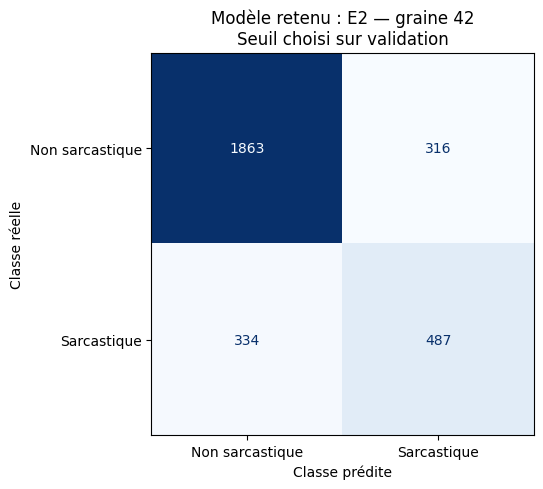

Modèle retenu : E2
Vrais négatifs : 1863
Faux positifs : 316
Faux négatifs : 334
Vrais positifs : 487


,famille,graines,nombre_graines,test_f1_moyen,test_f1_ecart_type,test_f1_seed42,test_precision_seed42,test_rappel_seed42,test_f1_avec_URL_seed42,test_f1_sans_URL_seed42,...,test_f1_egypt_seed42,temps_entrainement_moyen_s,temps_extraction_moyen_s,parametres_entraines,latence_CPU_moyenne_ms_par_tweet,latence_CPU_mediane_ms_par_tweet,latence_CPU_p95_ms_par_tweet,taille_modele_Mio,nombre_tweets_benchmark,threads_CPU
4,E2,"42,43,44",3,0.6094,0.0094,0.5998,0.6065,0.5932,0.0833,0.6075,...,0.7829,291.4487,NaN,134606597.0,107.2697,106.728,149.245,513.4912,30,2


In [ ]:
MODELE_RETENU_G = max(
    specs_42,
    key=lambda famille: specs_42[famille]["f1_val"]
)

# Exemple de choix manuel :
# MODELE_RETENU_G = "E1"

assert MODELE_RETENU_G in specs_42

donnees_retenues_g = lire_predictions_g(
    MODELE_RETENU_G, 42
)

y_pred_retenu_g = (
    donnees_retenues_g["y_pred"]
    .astype(int)
    .to_numpy()
)

# Les prédictions utilisent déjà le seuil choisi sur val.
matrice_g = confusion_matrix(
    y_test_g,
    y_pred_retenu_g,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matrice_g,
    display_labels=[
        "Non sarcastique",
        "Sarcastique"
    ]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    f"Modèle retenu : {MODELE_RETENU_G} — graine 42\n"
    "Seuil choisi sur validation"
)

ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")

plt.tight_layout()

plt.savefig(
    "results/G/G_matrice_confusion.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

vn, fp, fn, vp = matrice_g.ravel()

print("Modèle retenu :", MODELE_RETENU_G)
print("Vrais négatifs :", vn)
print("Faux positifs :", fp)
print("Faux négatifs :", fn)
print("Vrais positifs :", vp)

display(
    tableau_g.loc[
        tableau_g["famille"] == MODELE_RETENU_G
    ].round(4)
)